# AI-Powered Network Intrusion Detection System
## Notebook 07 – LSTM-Based Intrusion Detection Model

**Author:** Jithesh Shetty  
**Role:** Member A – ML & Data Engineer  
**Dataset:** CICIDS-2017  
**Model:** Long Short-Term Memory (LSTM)  
**Task:** Multi-Class Network Intrusion Detection  

---

### Notebook Purpose

This notebook develops, investigates, evaluates, and persists an LSTM-based deep learning model for network intrusion detection.

The LSTM model is intended to complement the Random Forest model developed in the previous stage of the project by learning patterns across sequential network traffic observations. The final trained model will be persisted as a reusable artifact so that other project components and team members can integrate it without requiring model retraining.

The notebook follows the project's established **investigation → decision → implementation → validation → documentation** methodology. Model architecture, sequence construction, training configuration, evaluation metrics, and persistence decisions are therefore investigated and documented rather than chosen arbitrarily.

---

### Objectives

The objectives of this notebook are to:

1. Prepare the previously established network-flow features for LSTM-based sequential learning.
2. Investigate and establish an appropriate strategy for constructing sequential inputs from the CICIDS-2017 flow data.
3. Design and investigate a suitable LSTM architecture for multi-class intrusion detection.
4. Train and validate the LSTM model.
5. Investigate relevant hyperparameters and training behaviour.
6. Evaluate the trained model using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.
7. Perform class-wise and error analysis to understand model behaviour.
8. Select and document the final LSTM configuration based on experimental evidence.
9. Persist the final trained LSTM model and the metadata required for reliable downstream use.
10. Validate the persisted model through a load-and-predict test.
11. Produce reproducible artifacts and documentation for integration with the remaining project components.

---

### Relationship to Previous Notebooks

This notebook continues the modelling pipeline established in the previous notebooks.

The Random Forest model was previously trained and persisted as a reusable model artifact. The subsequent SHAP analysis used that persisted model and its established feature representation to investigate model explainability.

The LSTM model developed here will follow the same reproducibility and handoff principles:

**Established preprocessing / feature representation**  
→ **Sequential input preparation**  
→ **LSTM investigation and training**  
→ **Evaluation and error analysis**  
→ **Final model selection**  
→ **Model persistence**  
→ **Artifact validation**  
→ **Handoff for downstream integration**

The LSTM model will be developed as a complementary model rather than as a replacement for the previously established Random Forest model.

---

### Reproducibility Principle

All important modelling decisions made in this notebook will be supported by observations, experiments, or previously established project artifacts.

The notebook will distinguish between:

- **Investigation** – what was tested or observed
- **Decision** – what configuration was selected and why
- **Implementation** – the selected configuration put into practice
- **Validation** – evidence that the implementation behaves as expected

This ensures that the final LSTM model is reproducible, explainable, and suitable for downstream integration.

### 7.1 Environment & Project Recovery Setup

**Purpose:**

Initialize the Colab runtime and recover the previously established project artifacts required for LSTM model development.

This section follows the same recovery-oriented approach used in the previous modelling notebooks. The Google Drive project structure and model-preparation artifacts established by the earlier preprocessing pipeline are reused rather than recreated.

A single setup cell is used to:

- Mount Google Drive
- Import the libraries required for LSTM development and evaluation
- Define the established project paths
- Define LSTM-specific output and model directories
- Verify the required model-preparation artifacts
- Load the scaled feature matrices and target arrays
- Load the fitted scaler and feature metadata
- Display the recovered dataset and feature configuration

The persisted preprocessing artifacts are treated as **read-only inputs**. No additional scaling, feature selection, or train-test splitting is performed at this stage.

The LSTM-specific sequence construction strategy will be investigated separately in the following sections before any sequence data is created.

In [4]:
# ============================================================
# 7.1 Environment & Project Recovery Setup
# ============================================================

import os
import json
import gc
import time
import random
import joblib

import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# Deep learning
# ------------------------------------------------------------

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# Model evaluation
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Google Drive
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_PATH = (
    "/content/drive/MyDrive/"
    "AI-Network-Intrusion-Detection-System"
)

DATA_PATH = os.path.join(
    PROJECT_PATH,
    "data"
)

RAW_DATA_PATH = os.path.join(
    DATA_PATH,
    "raw"
)

PROCESSED_DATA_PATH = os.path.join(
    DATA_PATH,
    "processed"
)

OUTPUTS_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

MODELS_PATH = os.path.join(
    PROJECT_PATH,
    "trained_models"
)

# Established model-preparation artifacts
MODEL_PREP_PATH = os.path.join(
    OUTPUTS_PATH,
    "model_preparation"
)

# LSTM-specific outputs
LSTM_OUTPUTS_PATH = os.path.join(
    OUTPUTS_PATH,
    "lstm"
)

LSTM_MODELS_PATH = os.path.join(
    MODELS_PATH,
    "lstm"
)

# Create LSTM output/model directories if required
os.makedirs(
    LSTM_OUTPUTS_PATH,
    exist_ok=True
)

os.makedirs(
    LSTM_MODELS_PATH,
    exist_ok=True
)

# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# MODEL-PREPARATION ARTIFACT PATHS
# ============================================================

X_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_train_scaled.npy"
)

X_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "X_test_scaled.npy"
)

Y_TRAIN_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_train.npy"
)

Y_TEST_PATH = os.path.join(
    MODEL_PREP_PATH,
    "y_test.npy"
)

SCALER_PATH = os.path.join(
    MODEL_PREP_PATH,
    "standard_scaler.joblib"
)

FEATURE_METADATA_PATH = os.path.join(
    MODEL_PREP_PATH,
    "feature_metadata.json"
)

# ============================================================
# REQUIRED ARTIFACT VALIDATION
# ============================================================

required_artifacts = {
    "X_train_scaled.npy": X_TRAIN_PATH,
    "X_test_scaled.npy": X_TEST_PATH,
    "y_train.npy": Y_TRAIN_PATH,
    "y_test.npy": Y_TEST_PATH,
    "standard_scaler.joblib": SCALER_PATH,
    "feature_metadata.json": FEATURE_METADATA_PATH
}

print("=" * 75)
print("LSTM NOTEBOOK 07 - ENVIRONMENT RECOVERY")
print("=" * 75)

print("\nProject path:")
print(PROJECT_PATH)

print("\nModel-preparation path:")
print(MODEL_PREP_PATH)

print("\nLSTM outputs path:")
print(LSTM_OUTPUTS_PATH)

print("\nLSTM models path:")
print(LSTM_MODELS_PATH)

print("\nChecking required model-preparation artifacts:")
print("-" * 75)

for artifact_name, artifact_path in required_artifacts.items():

    if not os.path.exists(artifact_path):

        raise FileNotFoundError(
            f"Required artifact not found:\n{artifact_path}"
        )

    print(f"✓ {artifact_name}")

# ============================================================
# LOAD MODEL-READY FEATURE MATRICES
# ============================================================

print("\n" + "=" * 75)
print("LOADING MODEL-READY DATA")
print("=" * 75)

# Memory mapping avoids unnecessarily loading the complete
# feature matrices into RAM at notebook startup.

X_train = np.load(
    X_TRAIN_PATH,
    mmap_mode="r"
)

X_test = np.load(
    X_TEST_PATH,
    mmap_mode="r"
)

# Target arrays are comparatively small and can be loaded normally.

y_train = np.load(
    Y_TRAIN_PATH
)

y_test = np.load(
    Y_TEST_PATH
)

# Load the previously fitted scaler.
scaler = joblib.load(
    SCALER_PATH
)

# Load feature metadata.
with open(
    FEATURE_METADATA_PATH,
    "r"
) as f:

    feature_metadata = json.load(f)

# ============================================================
# RECOVER FEATURE INFORMATION
# ============================================================

feature_names = feature_metadata.get(
    "feature_columns",
    []
)

number_of_features = feature_metadata.get(
    "number_of_features",
    X_train.shape[1]
)

target_column = feature_metadata.get(
    "target_column",
    "Label"
)

dataset_name = feature_metadata.get(
    "dataset",
    "CICIDS-2017"
)

# ============================================================
# ENVIRONMENT SUMMARY
# ============================================================

print("\nData loaded successfully.")

print("\nDataset:")
print(dataset_name)

print("\nFeature representation:")
print("Training shape :", X_train.shape)
print("Testing shape  :", X_test.shape)
print("Feature count  :", X_train.shape[1])

print("\nTarget representation:")
print("Training shape :", y_train.shape)
print("Testing shape  :", y_test.shape)
print("Target column  :", target_column)

print("\nScaler:")
print("Type            :", type(scaler).__name__)
print("Scaler features :", scaler.n_features_in_)

print("\nFeature metadata:")
print("Metadata feature count:", number_of_features)

if feature_names:
    print("Feature names recovered:", len(feature_names))
else:
    print(
        "Feature names are not explicitly stored in metadata; "
        "they will be recovered from the established feature mapping."
    )

# ============================================================
# PYTORCH ENVIRONMENT
# ============================================================

print("\n" + "=" * 75)
print("PYTORCH ENVIRONMENT")
print("=" * 75)

print("PyTorch version:", torch.__version__)
print("Device         :", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU            :",
        torch.cuda.get_device_name(0)
    )

else:

    print("GPU            : Not available")

# ============================================================
# BASIC RECOVERY VALIDATION
# ============================================================

assert X_train.ndim == 2
assert X_test.ndim == 2

assert y_train.ndim == 1
assert y_test.ndim == 1

assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]

assert X_train.shape[1] == X_test.shape[1]

assert scaler.n_features_in_ == X_train.shape[1]

assert X_train.shape[1] == number_of_features

print("\n" + "=" * 75)
print("RECOVERY VALIDATION")
print("=" * 75)

print("✓ Training feature/target alignment")
print("✓ Testing feature/target alignment")
print("✓ Training/testing feature count consistency")
print("✓ Scaler feature count consistency")
print("✓ Feature metadata consistency")

print("\nEnvironment and project artifacts recovered successfully.")
print("No preprocessing or model training has been performed.")
print("=" * 75)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LSTM NOTEBOOK 07 - ENVIRONMENT RECOVERY

Project path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System

Model-preparation path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation

LSTM outputs path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm

LSTM models path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/lstm

Checking required model-preparation artifacts:
---------------------------------------------------------------------------
✓ X_train_scaled.npy
✓ X_test_scaled.npy
✓ y_train.npy
✓ y_test.npy
✓ standard_scaler.joblib
✓ feature_metadata.json

LOADING MODEL-READY DATA

Data loaded successfully.

Dataset:
CICIDS2017

Feature representation:
Training shape : (2264594, 63)
Testing shape  : (566149, 63)
Feature count  : 63

Target representation:
Trai

## 7.2 LSTM Input Design and Sequence Construction

### Objective

Investigate how the existing model-ready tabular data should be transformed into sequential input suitable for an LSTM-based intrusion detection model.

### Purpose

The existing dataset has been prepared as model-ready feature and target arrays and was previously used for the Random Forest model. The LSTM model requires sequential input rather than independent feature vectors.

This section will therefore investigate:

- the structure and ordering of the available samples,
- whether the current data supports meaningful sequence construction,
- an appropriate sequence length,
- how sequence construction affects the training and testing datasets,
- and how to prevent information leakage between training and testing data.

### Approach

The LSTM input strategy will be established through the following process:

1. **Investigate** the available data structure and sample ordering.
2. **Determine** whether a meaningful sequential representation can be constructed.
3. **Decide** the sequence construction strategy and sequence length based on the investigation.
4. **Implement** the selected sequence representation.
5. **Validate** the resulting tensors before model training.

No arbitrary reshaping or sequence construction will be performed before the ordering and sequence strategy have been investigated and justified.

### 7.2.1 Investigate Data Ordering and Sequential Information

Before constructing LSTM sequences, the ordering and structure of the model-ready data must be investigated.

An LSTM learns relationships between observations across a sequence. Therefore, simply grouping consecutive rows together would only be valid if the existing row ordering provides a defensible representation of sequential network activity.

This investigation will examine:

- the available feature metadata,
- whether temporal or ordering-related information is retained,
- the ordering of samples within the training and testing arrays,
- target-label distribution and transitions,
- the presence of repeated or consecutive observations,
- and whether training and testing data can be converted into sequences independently without introducing leakage.

The investigation will be performed without modifying the existing model-ready datasets.

The findings will be used to determine and justify the sequence construction strategy and sequence length before implementation.

In [5]:
# ============================================================
# 7.2.1 DATA ORDERING AND SEQUENTIAL INFORMATION INVESTIGATION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("LSTM INPUT DESIGN INVESTIGATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Basic dataset structure
# ------------------------------------------------------------

print("\n[1] DATASET STRUCTURE")
print("-" * 75)

print(f"Training feature shape : {X_train.shape}")
print(f"Testing feature shape  : {X_test.shape}")
print(f"Training target shape  : {y_train.shape}")
print(f"Testing target shape   : {y_test.shape}")

print(f"\nTraining samples : {len(X_train):,}")
print(f"Testing samples  : {len(X_test):,}")
print(f"Feature count    : {X_train.shape[1]}")

# ------------------------------------------------------------
# 2. Feature metadata
# ------------------------------------------------------------

print("\n[2] FEATURE METADATA")
print("-" * 75)

if "feature_metadata" in globals():
    if isinstance(feature_metadata, dict):
        feature_names = (
            feature_metadata.get("feature_names")
            or feature_metadata.get("features")
            or feature_metadata.get("columns")
        )
    else:
        feature_names = None
else:
    feature_names = None

if feature_names is not None:
    print(f"Number of recovered feature names: {len(feature_names)}")

    print("\nFeature names:")
    for i, name in enumerate(feature_names):
        print(f"{i:02d}: {name}")

    temporal_keywords = [
        "time",
        "timestamp",
        "date",
        "duration",
        "start",
        "end"
    ]

    possible_temporal = [
        name for name in feature_names
        if any(keyword in str(name).lower()
               for keyword in temporal_keywords)
    ]

    print("\nPotential temporal/order-related features:")
    if possible_temporal:
        for name in possible_temporal:
            print(f"  - {name}")
    else:
        print("  None identified from feature names.")

else:
    print("Feature names were not recovered from feature metadata.")
    print("The investigation will continue using the available arrays.")

# ------------------------------------------------------------
# 3. Target representation and class distribution
# ------------------------------------------------------------

print("\n[3] TARGET DISTRIBUTION")
print("-" * 75)

def show_target_distribution(name, y):
    values, counts = np.unique(y, return_counts=True)

    print(f"\n{name}:")
    for value, count in zip(values, counts):
        percentage = (count / len(y)) * 100
        print(f"  Class {value}: {count:,} samples ({percentage:.2f}%)")

show_target_distribution("Training target", y_train)
show_target_distribution("Testing target", y_test)

# ------------------------------------------------------------
# 4. Target transitions in existing row order
# ------------------------------------------------------------

print("\n[4] TARGET TRANSITIONS IN CURRENT ROW ORDER")
print("-" * 75)

def analyze_transitions(name, y):
    y_flat = np.asarray(y).reshape(-1)

    transitions = np.sum(y_flat[1:] != y_flat[:-1])
    transition_rate = transitions / max(len(y_flat) - 1, 1)

    print(f"\n{name}:")
    print(f"  Consecutive label transitions : {transitions:,}")
    print(f"  Transition rate               : {transition_rate:.4f}")

    # Lengths of consecutive same-label runs
    change_points = np.where(y_flat[1:] != y_flat[:-1])[0] + 1
    boundaries = np.concatenate(([0], change_points, [len(y_flat)]))
    run_lengths = np.diff(boundaries)

    print(f"  Number of label runs          : {len(run_lengths):,}")
    print(f"  Mean run length               : {run_lengths.mean():.2f}")
    print(f"  Median run length             : {np.median(run_lengths):.2f}")
    print(f"  Maximum run length            : {run_lengths.max():,}")

analyze_transitions("Training data", y_train)
analyze_transitions("Testing data", y_test)

# ------------------------------------------------------------
# 5. Inspect beginning and end of target ordering
# ------------------------------------------------------------

print("\n[5] TARGET ORDERING INSPECTION")
print("-" * 75)

def inspect_target_edges(name, y, n=30):
    y_flat = np.asarray(y).reshape(-1)

    print(f"\n{name} - first {n} targets:")
    print(y_flat[:n])

    print(f"\n{name} - last {n} targets:")
    print(y_flat[-n:])

inspect_target_edges("Training data", y_train)
inspect_target_edges("Testing data", y_test)

# ------------------------------------------------------------
# 6. Check whether samples are exact duplicates
# ------------------------------------------------------------

print("\n[6] DUPLICATE SAMPLE INVESTIGATION")
print("-" * 75)

def duplicate_summary(name, X):
    # Exact duplicate rows
    unique_count = np.unique(X, axis=0).shape[0]
    duplicate_count = len(X) - unique_count

    print(f"{name}:")
    print(f"  Total samples       : {len(X):,}")
    print(f"  Unique feature rows : {unique_count:,}")
    print(f"  Duplicate rows      : {duplicate_count:,}")

duplicate_summary("Training features", X_train)
duplicate_summary("Testing features", X_test)

# ------------------------------------------------------------
# 7. Check train/test feature overlap
# ------------------------------------------------------------

print("\n[7] TRAIN/TEST FEATURE OVERLAP CHECK")
print("-" * 75)

train_unique = set(map(tuple, X_train))
test_unique = set(map(tuple, X_test))

overlap_count = len(train_unique.intersection(test_unique))

print(f"Exact feature-vector overlap : {overlap_count:,}")

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INVESTIGATION COMPLETE")
print("=" * 75)

print("""
No data has been modified or reshaped in this section.

The observations above will be used to determine whether:
1. The existing row ordering can reasonably represent sequence order.
2. A temporal feature or explicit ordering signal is available.
3. Consecutive samples can be grouped into LSTM sequences.
4. Training and testing sequences should be constructed independently.
5. An appropriate sequence length can be selected and justified.
""")

LSTM INPUT DESIGN INVESTIGATION

[1] DATASET STRUCTURE
---------------------------------------------------------------------------
Training feature shape : (2264594, 63)
Testing feature shape  : (566149, 63)
Training target shape  : (2264594,)
Testing target shape   : (566149,)

Training samples : 2,264,594
Testing samples  : 566,149
Feature count    : 63

[2] FEATURE METADATA
---------------------------------------------------------------------------
Feature names were not recovered from feature metadata.
The investigation will continue using the available arrays.

[3] TARGET DISTRIBUTION
---------------------------------------------------------------------------

Training target:
  Class 0: 1,818,477 samples (80.30%)
  Class 1: 1,573 samples (0.07%)
  Class 2: 102,421 samples (4.52%)
  Class 3: 8,234 samples (0.36%)
  Class 4: 184,858 samples (8.16%)
  Class 5: 4,399 samples (0.19%)
  Class 6: 4,637 samples (0.20%)
  Class 7: 6,350 samples (0.28%)
  Class 8: 9 samples (0.00%)
  Class

### 7.2.2 Recover Feature Metadata and Inspect Feature Semantics

The initial investigation showed that the model-ready feature arrays contain 63 features, but the feature names were not recovered by the current notebook variables.

Because sequence construction and LSTM interpretation depend on understanding what each feature represents, the persisted feature metadata will be explicitly recovered from the project artifacts.

This section will:

- recover the persisted feature metadata,
- verify that the metadata contains exactly 63 features,
- inspect the feature names and their ordering,
- identify whether any explicit temporal, timestamp, flow-order, or connection-identity information is available,
- distinguish actual temporal information from ordinary traffic-flow measurements,
- and determine whether the existing feature representation provides evidence for constructing meaningful sequences.

The original model-ready feature arrays will not be modified during this investigation.

In [6]:
# ============================================================
# 7.2.2 FEATURE METADATA RECOVERY AND SEMANTIC INSPECTION
# ============================================================

import json
from pathlib import Path

print("\n" + "=" * 75)
print("FEATURE METADATA RECOVERY AND SEMANTIC INSPECTION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Locate feature metadata
# ---------------------------------------------------------------------------

print("\n[1] LOCATING FEATURE METADATA")
print("-" * 75)

metadata_path = Path(FEATURE_METADATA_PATH)

print(f"Checking: {metadata_path}")

if metadata_path.exists():
    print("✓ Feature metadata file found.")
    print(f"Selected metadata file: {metadata_path}")
else:
    raise FileNotFoundError(
        f"Required feature metadata file was not found:\n{metadata_path}"
    )


# ---------------------------------------------------------------------------
# 2. Load and inspect metadata
# ---------------------------------------------------------------------------

print("\n[2] LOADING FEATURE METADATA")
print("-" * 75)

with open(metadata_path, "r") as f:
    feature_metadata = json.load(f)

print("✓ Feature metadata loaded successfully.")
print(f"Metadata type: {type(feature_metadata).__name__}")


# ---------------------------------------------------------------------------
# 3. Inspect metadata structure
# ---------------------------------------------------------------------------

print("\n[3] METADATA STRUCTURE")
print("-" * 75)

if isinstance(feature_metadata, dict):

    print(f"Top-level keys: {list(feature_metadata.keys())}")

    for key, value in feature_metadata.items():

        if isinstance(value, list):
            print(f"  {key}: list ({len(value)} items)")

        elif isinstance(value, dict):
            print(f"  {key}: dictionary ({len(value)} entries)")

        else:
            print(f"  {key}: {type(value).__name__}")

elif isinstance(feature_metadata, list):

    print(f"Metadata contains {len(feature_metadata)} items.")

    if feature_metadata:
        print(
            f"First item type: "
            f"{type(feature_metadata[0]).__name__}"
        )
    else:
        print("Metadata list is empty.")

else:

    print(
        "Metadata has an unexpected structure and cannot be "
        "inspected using the current logic."
    )


# ---------------------------------------------------------------------------
# 4. Recover feature names
# ---------------------------------------------------------------------------

print("\n[4] FEATURE NAME RECOVERY")
print("-" * 75)

feature_names = None

if isinstance(feature_metadata, dict):

    possible_keys = [
        "feature_names",
        "features",
        "feature_columns",
        "columns",
        "names"
    ]

    for key in possible_keys:

        if key in feature_metadata:

            candidate_names = feature_metadata[key]

            if isinstance(candidate_names, list):

                feature_names = candidate_names

                print(
                    f"✓ Feature names recovered from key: '{key}'"
                )

                break


if feature_names is not None:

    print(f"Feature names recovered: {len(feature_names)}")

    print("\nAll recovered feature names:")
    for i, name in enumerate(feature_names):
        print(f"  {i:02d}: {name}")

else:

    print("✗ Feature names could not be recovered from metadata.")


# ---------------------------------------------------------------------------
# 5. Validate feature-count consistency
# ---------------------------------------------------------------------------

print("\n[5] FEATURE COUNT CONSISTENCY")
print("-" * 75)

expected_feature_count = X_train.shape[1]

print(f"Model-ready feature count : {expected_feature_count}")

if feature_names is not None:

    metadata_feature_count = len(feature_names)

    print(f"Metadata feature count    : {metadata_feature_count}")

    if metadata_feature_count == expected_feature_count:
        print("✓ Feature count is consistent.")
    else:
        print("✗ Feature count mismatch detected.")

else:

    print(
        "Feature-name count cannot be validated because "
        "feature names were not recovered."
    )


# ---------------------------------------------------------------------------
# 6. Final observation
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("FEATURE METADATA INVESTIGATION COMPLETE")
print("=" * 75)

if feature_names is not None:

    print("""
    Feature metadata has been successfully recovered and inspected.

    The metadata confirms that the model-ready representation contains
    63 flow-level network traffic features. Several features describe
    temporal characteristics within individual flows, such as Flow Duration
    and Flow IAT statistics.

    However, the recovered feature list does not contain an explicit
    timestamp, flow identifier, session identifier, or sequence/index
    feature that establishes chronological ordering between dataset rows.

    No data has been modified or reshaped in this section.
    """)

else:

    print("""
Feature metadata was located and loaded, but feature names could not
be recovered using the available metadata structure.

The investigation will continue using the available feature arrays
and persisted model-preparation artifacts.

No data has been modified or reshaped in this section.
""")


FEATURE METADATA RECOVERY AND SEMANTIC INSPECTION

[1] LOCATING FEATURE METADATA
---------------------------------------------------------------------------
Checking: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/feature_metadata.json
✓ Feature metadata file found.
Selected metadata file: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/feature_metadata.json

[2] LOADING FEATURE METADATA
---------------------------------------------------------------------------
✓ Feature metadata loaded successfully.
Metadata type: dict

[3] METADATA STRUCTURE
---------------------------------------------------------------------------
Top-level keys: ['dataset', 'number_of_features', 'feature_columns', 'target_column', 'scaling', 'scaler_fitted_on', 'train_samples', 'test_samples', 'feature_dtype', 'target_dtype']
  dataset: str
  number_of_features: int
  feature_columns: list (63 items)
  target_column: str
  scaling: st

## 7.2.3 Investigate Temporal and Ordering Information

### Objective

Determine whether the existing model-ready feature representation and row ordering provide sufficient evidence to treat consecutive samples as meaningful temporal sequences for LSTM modeling.

### Purpose

LSTM models are designed to learn dependencies across ordered sequences. Before constructing sequences from the CICIDS-2017 model-ready data, it is necessary to determine whether consecutive rows represent meaningful temporal or behavioral relationships.

This investigation examines:
- the presence of explicit temporal or ordering information in the feature representation,
- short-range label continuity across consecutive rows,
- the stability of local label continuity at different lags, and
- the separation of training and testing partitions when considering sequence construction.

The investigation does not modify, reorder, or reshape the existing data.

### Expected Outcome

The results will be used together with Sections 7.2.1 and 7.2.2 to determine whether sequence construction from the existing row order is defensible and what assumptions must be documented before constructing LSTM input sequences.

In [7]:
# ============================================================
# 7.2.3 TEMPORAL AND ORDERING INFORMATION INVESTIGATION
# ============================================================

import numpy as np

print("\n" + "=" * 75)
print("TEMPORAL AND ORDERING INFORMATION INVESTIGATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] Explicit temporal and ordering signal inspection
# ---------------------------------------------------------------------------

print("\n[1] EXPLICIT TEMPORAL AND ORDERING SIGNAL")
print("-" * 75)

temporal_keywords = [
    "timestamp",
    "date",
    "time",
    "flow id",
    "session id",
    "connection id",
    "sequence",
    "packet id",
    "index"
]

ordering_candidates = []

for feature_name in feature_names:

    feature_lower = feature_name.lower()

    if any(keyword in feature_lower for keyword in temporal_keywords):
        ordering_candidates.append(feature_name)

if ordering_candidates:

    print("Potential temporal or ordering-related features identified:")

    for feature_name in ordering_candidates:
        print(f"  - {feature_name}")

else:

    print(
        "No explicit timestamp, flow identifier, session identifier, "
        "or sequence/index feature was identified."
    )


# ---------------------------------------------------------------------------
# [2] Label continuity in current row order
# ---------------------------------------------------------------------------

print("\n[2] LABEL CONTINUITY IN CURRENT ROW ORDER")
print("-" * 75)

def analyze_label_continuity(y):

    transitions = np.sum(y[1:] != y[:-1])
    transition_rate = transitions / (len(y) - 1)

    run_lengths = []
    current_length = 1

    for i in range(1, len(y)):

        if y[i] == y[i - 1]:
            current_length += 1

        else:
            run_lengths.append(current_length)
            current_length = 1

    run_lengths.append(current_length)

    return {
        "transitions": int(transitions),
        "transition_rate": float(transition_rate),
        "number_of_runs": len(run_lengths),
        "mean_run_length": float(np.mean(run_lengths)),
        "median_run_length": float(np.median(run_lengths)),
        "maximum_run_length": int(np.max(run_lengths))
    }


train_continuity = analyze_label_continuity(y_train)
test_continuity = analyze_label_continuity(y_test)

print("Training data:")
print(f"  Consecutive transitions : {train_continuity['transitions']:,}")
print(f"  Transition rate         : {train_continuity['transition_rate']:.4f}")
print(f"  Number of label runs    : {train_continuity['number_of_runs']:,}")
print(f"  Mean run length         : {train_continuity['mean_run_length']:.2f}")
print(f"  Median run length       : {train_continuity['median_run_length']:.2f}")
print(f"  Maximum run length      : {train_continuity['maximum_run_length']}")

print("\nTesting data:")
print(f"  Consecutive transitions : {test_continuity['transitions']:,}")
print(f"  Transition rate         : {test_continuity['transition_rate']:.4f}")
print(f"  Number of label runs    : {test_continuity['number_of_runs']:,}")
print(f"  Mean run length         : {test_continuity['mean_run_length']:.2f}")
print(f"  Median run length       : {test_continuity['median_run_length']:.2f}")
print(f"  Maximum run length      : {test_continuity['maximum_run_length']}")


# ---------------------------------------------------------------------------
# [3] Short-range label continuity at different lags
# ---------------------------------------------------------------------------

print("\n[3] SHORT-RANGE LABEL CONTINUITY")
print("-" * 75)

def same_label_rate(y, lag):

    if len(y) <= lag:
        return np.nan

    return np.mean(y[lag:] == y[:-lag])


print("Same-label rate at different row-order lags:")

for lag in [1, 2, 3, 5, 10]:

    train_rate = same_label_rate(y_train, lag)
    test_rate = same_label_rate(y_test, lag)

    print(
        f"  Lag {lag:2d} | "
        f"Train: {train_rate:.4f} | "
        f"Test: {test_rate:.4f}"
    )


# ---------------------------------------------------------------------------
# [4] Train/test ordering boundary inspection
# ---------------------------------------------------------------------------

print("\n[4] TRAIN/TEST ORDERING BOUNDARY")
print("-" * 75)

print(f"Last 10 training labels : {y_train[-10:]}")
print(f"First 10 testing labels : {y_test[:10]}")

print("""
Training and testing arrays remain independent partitions.

No sequence will be allowed to cross the training/testing boundary
during subsequent sequence construction.
""")


# ---------------------------------------------------------------------------
# [5] Temporal interpretation of available features
# ---------------------------------------------------------------------------

print("\n[5] TEMPORAL INTERPRETATION OF AVAILABLE FEATURES")
print("-" * 75)

flow_temporal_features = [
    feature_name
    for feature_name in feature_names
    if any(
        keyword in feature_name.lower()
        for keyword in [
            "duration",
            "iat",
            "active",
            "idle"
        ]
    )
]

print("Flow-level temporal features identified:")

for feature_name in flow_temporal_features:
    print(f"  - {feature_name}")

print("""
These features describe temporal characteristics within individual
network flows. They do not, by themselves, establish the chronological
ordering of one dataset row relative to another.
""")


# ---------------------------------------------------------------------------
# [6] Investigation conclusion
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("TEMPORAL AND ORDERING INVESTIGATION COMPLETE")
print("=" * 75)

print("""
The feature metadata does not provide an explicit chronological
timestamp, flow identifier, session identifier, or sequence/index
feature for establishing the temporal order of dataset rows.

The current row order does exhibit local label continuity, but label
continuity alone does not establish that consecutive rows represent
successive observations from the same temporal process.

Therefore, the existing row order should not be treated as proven
chronological ordering.

These findings will be combined with the earlier data-ordering and
feature-metadata investigations to determine an appropriate and
explicitly documented LSTM sequence-construction strategy.

No data has been modified, reordered, or reshaped in this section.
""")


TEMPORAL AND ORDERING INFORMATION INVESTIGATION

[1] EXPLICIT TEMPORAL AND ORDERING SIGNAL
---------------------------------------------------------------------------
No explicit timestamp, flow identifier, session identifier, or sequence/index feature was identified.

[2] LABEL CONTINUITY IN CURRENT ROW ORDER
---------------------------------------------------------------------------
Training data:
  Consecutive transitions : 776,601
  Transition rate         : 0.3429
  Number of label runs    : 776,602
  Mean run length         : 2.92
  Median run length       : 1.00
  Maximum run length      : 60

Testing data:
  Consecutive transitions : 194,315
  Transition rate         : 0.3432
  Number of label runs    : 194,316
  Mean run length         : 2.91
  Median run length       : 1.00
  Maximum run length      : 47

[3] SHORT-RANGE LABEL CONTINUITY
---------------------------------------------------------------------------
Same-label rate at different row-order lags:
  Lag  1 | Train: 

## 7.2.4 Investigate Sequence Length

The previous investigation established that the LSTM experiment will use
fixed-length windows over the existing row order because no verified
chronological or session-based ordering signal is available.

Before constructing the LSTM input tensors, an appropriate sequence length
must be selected.

Several candidate sequence lengths will be investigated using the existing
training and testing target arrays. The investigation will examine:

- the number of complete sequences produced,
- the number and proportion of samples retained or discarded,
- label composition within candidate windows,
- the proportion of windows containing a single label versus multiple labels,
- class coverage,
- and the approximate memory requirement of the resulting feature tensors.

Because the Colab runtime has limited system RAM, this investigation will
not construct or store the full LSTM feature tensors.

Memory requirements will instead be estimated mathematically from the existing
sample count, feature count, sequence length, and feature data type.

Training and testing partitions will be evaluated independently.

No existing feature or target data will be modified, reordered, or reshaped
during this investigation.

The results will be used to select and justify the final sequence length
before the actual LSTM input construction.

In [8]:
# ============================================================
# LSTM SEQUENCE LENGTH INVESTIGATION
# ============================================================

import numpy as np
import psutil

print("\n" + "=" * 75)
print("LSTM SEQUENCE LENGTH INVESTIGATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Candidate sequence lengths
# ---------------------------------------------------------------------------

print("\n[1] CANDIDATE SEQUENCE LENGTHS")
print("-" * 75)

candidate_lengths = [5, 10, 20, 30, 50]

print(f"Candidate sequence lengths: {candidate_lengths}")
print(f"Feature count             : {X_train.shape[1]}")
print(f"Training samples          : {len(X_train):,}")
print(f"Testing samples           : {len(X_test):,}")


# ---------------------------------------------------------------------------
# 2. Sequence coverage and sample retention
# ---------------------------------------------------------------------------

print("\n[2] SEQUENCE COVERAGE AND SAMPLE RETENTION")
print("-" * 75)


def coverage_summary(sample_count, sequence_length):

    complete_sequences = sample_count // sequence_length
    used_samples = complete_sequences * sequence_length
    discarded_samples = sample_count - used_samples

    retained_percentage = (
        used_samples / sample_count
    ) * 100

    discarded_percentage = (
        discarded_samples / sample_count
    ) * 100

    return (
        complete_sequences,
        used_samples,
        discarded_samples,
        retained_percentage,
        discarded_percentage
    )


for seq_len in candidate_lengths:

    train_result = coverage_summary(
        len(X_train),
        seq_len
    )

    test_result = coverage_summary(
        len(X_test),
        seq_len
    )

    print(f"\nSequence length: {seq_len}")

    print(
        f"  Training | "
        f"Sequences: {train_result[0]:,} | "
        f"Used: {train_result[1]:,} | "
        f"Discarded: {train_result[2]:,} | "
        f"Retained: {train_result[3]:.4f}%"
    )

    print(
        f"  Testing  | "
        f"Sequences: {test_result[0]:,} | "
        f"Used: {test_result[1]:,} | "
        f"Discarded: {test_result[2]:,} | "
        f"Retained: {test_result[3]:.4f}%"
    )


# ---------------------------------------------------------------------------
# 3. Label composition within candidate windows
# ---------------------------------------------------------------------------

print("\n[3] LABEL COMPOSITION WITHIN CANDIDATE WINDOWS")
print("-" * 75)


def label_window_summary(targets, sequence_length):

    complete_samples = (
        len(targets) // sequence_length
    ) * sequence_length

    same_label_windows = 0
    mixed_label_windows = 0

    class_presence = set()

    for start in range(0, complete_samples, sequence_length):

        window = targets[
            start:start + sequence_length
        ]

        unique_labels = np.unique(window)

        class_presence.update(
            unique_labels.tolist()
        )

        if len(unique_labels) == 1:
            same_label_windows += 1
        else:
            mixed_label_windows += 1

    total_windows = (
        same_label_windows +
        mixed_label_windows
    )

    same_label_percentage = (
        same_label_windows / total_windows
    ) * 100

    mixed_label_percentage = (
        mixed_label_windows / total_windows
    ) * 100

    return {
        "total_windows": total_windows,
        "same_label_windows": same_label_windows,
        "mixed_label_windows": mixed_label_windows,
        "same_label_percentage": same_label_percentage,
        "mixed_label_percentage": mixed_label_percentage,
        "class_presence": sorted(class_presence)
    }


for seq_len in candidate_lengths:

    train_summary = label_window_summary(
        y_train,
        seq_len
    )

    test_summary = label_window_summary(
        y_test,
        seq_len
    )

    print(f"\nSequence length: {seq_len}")

    print(
        f"  Training | "
        f"Same-label: {train_summary['same_label_percentage']:.2f}% | "
        f"Mixed-label: {train_summary['mixed_label_percentage']:.2f}%"
    )

    print(
        f"  Testing  | "
        f"Same-label: {test_summary['same_label_percentage']:.2f}% | "
        f"Mixed-label: {test_summary['mixed_label_percentage']:.2f}%"
    )


# ---------------------------------------------------------------------------
# 4. Class coverage
# ---------------------------------------------------------------------------

print("\n[4] CLASS COVERAGE")
print("-" * 75)

train_classes = np.unique(y_train).tolist()
test_classes = np.unique(y_test).tolist()

print("Training classes present:")
print(train_classes)

print("\nTesting classes present:")
print(test_classes)

print(
    f"\nNumber of training classes: {len(train_classes)}"
)

print(
    f"Number of testing classes : {len(test_classes)}"
)


# ---------------------------------------------------------------------------
# 5. Approximate feature-tensor memory
# ---------------------------------------------------------------------------

print("\n[5] APPROXIMATE FEATURE-TENSOR MEMORY")
print("-" * 75)

feature_count = X_train.shape[1]

# The persisted arrays are scaled numerical features.
# Estimate using float32 because this is the intended LSTM input dtype.

bytes_per_value = np.dtype(np.float32).itemsize

print(f"Feature count       : {feature_count}")
print(f"Assumed input dtype : float32")
print(f"Bytes per value     : {bytes_per_value}")


for seq_len in candidate_lengths:

    train_sequences = len(X_train) // seq_len
    test_sequences = len(X_test) // seq_len

    train_elements = (
        train_sequences *
        seq_len *
        feature_count
    )

    test_elements = (
        test_sequences *
        seq_len *
        feature_count
    )

    train_memory_gb = (
        train_elements *
        bytes_per_value
    ) / (1024 ** 3)

    test_memory_gb = (
        test_elements *
        bytes_per_value
    ) / (1024 ** 3)

    combined_memory_gb = (
        train_memory_gb +
        test_memory_gb
    )

    print(
        f"\nLength {seq_len:>2}: "
        f"Train ≈ {train_memory_gb:.3f} GB | "
        f"Test ≈ {test_memory_gb:.3f} GB | "
        f"Combined ≈ {combined_memory_gb:.3f} GB"
    )


# ---------------------------------------------------------------------------
# 6. Current runtime memory snapshot
# ---------------------------------------------------------------------------

print("\n[6] CURRENT RUNTIME MEMORY")
print("-" * 75)

memory = psutil.virtual_memory()

print(
    f"System RAM total : "
    f"{memory.total / (1024 ** 3):.2f} GB"
)

print(
    f"System RAM used  : "
    f"{memory.used / (1024 ** 3):.2f} GB"
)

print(
    f"System RAM free  : "
    f"{memory.available / (1024 ** 3):.2f} GB"
)

print(
    f"System RAM usage : "
    f"{memory.percent:.1f}%"
)


# ---------------------------------------------------------------------------
# 7. Final observation
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE LENGTH INVESTIGATION COMPLETE")
print("=" * 75)

print("""
Candidate sequence lengths have been evaluated without constructing
large LSTM feature tensors.

The investigation considered:

1. Number of complete sequences.
2. Sample retention and discard rates.
3. Label composition within windows.
4. Class coverage.
5. Approximate feature-tensor memory requirements.
6. Current system RAM availability.

No existing feature or target data has been modified, reordered, or
reshaped in this section.

The results will be used to select and justify the final sequence
length before constructing the LSTM input representation.
""")


LSTM SEQUENCE LENGTH INVESTIGATION

[1] CANDIDATE SEQUENCE LENGTHS
---------------------------------------------------------------------------
Candidate sequence lengths: [5, 10, 20, 30, 50]
Feature count             : 63
Training samples          : 2,264,594
Testing samples           : 566,149

[2] SEQUENCE COVERAGE AND SAMPLE RETENTION
---------------------------------------------------------------------------

Sequence length: 5
  Training | Sequences: 452,918 | Used: 2,264,590 | Discarded: 4 | Retained: 99.9998%
  Testing  | Sequences: 113,229 | Used: 566,145 | Discarded: 4 | Retained: 99.9993%

Sequence length: 10
  Training | Sequences: 226,459 | Used: 2,264,590 | Discarded: 4 | Retained: 99.9998%
  Testing  | Sequences: 56,614 | Used: 566,140 | Discarded: 9 | Retained: 99.9984%

Sequence length: 20
  Training | Sequences: 113,229 | Used: 2,264,580 | Discarded: 14 | Retained: 99.9994%
  Testing  | Sequences: 28,307 | Used: 566,140 | Discarded: 9 | Retained: 99.9984%

Sequence le

## 7.2.5 Sequence Length Decision

The candidate sequence lengths were evaluated using sample retention, label composition, class coverage, computational practicality, and estimated memory requirements.

The investigation shows that shorter windows provide better local label continuity, while longer windows increasingly combine observations with different target labels. Because the available row order is not verified chronological ordering, unnecessarily long windows would introduce a larger amount of potentially unrelated information into each LSTM sequence.

The current Colab runtime is also using approximately 7.54 GB of 12.67 GB system RAM. Therefore, the final sequence construction must avoid creating multiple large candidate tensors or unnecessary copies of the model-ready data.

Based on the investigation, a sequence length of **5** will be selected for the LSTM experiment.

This provides:

- approximately 99.9998% training-sample retention,
- approximately 99.9993% testing-sample retention,
- the highest same-label window proportion among the investigated candidates,
- substantially lower sequence depth than longer candidates,
- and a practical computational and memory requirement for the available runtime.

The selected length is a methodological choice for the LSTM experiment and does not imply that each five-row window represents a verified chronological network session.

The final sequence tensors will be constructed only after this decision, with training and testing data processed independently and without crossing the partition boundary.

In [9]:
# ============================================================
# 7.2.5 SEQUENCE LENGTH DECISION
# ============================================================

print("\n" + "=" * 75)
print("LSTM SEQUENCE LENGTH DECISION")
print("=" * 75)

# ---------------------------------------------------------------------------
# 1. Decision basis
# ---------------------------------------------------------------------------

print("\n[1] DECISION BASIS")
print("-" * 75)

candidate_lengths = [5, 10, 20, 30, 50]

print(f"Candidate sequence lengths evaluated : {candidate_lengths}")
print(f"Training samples                    : {len(X_train):,}")
print(f"Testing samples                     : {len(X_test):,}")
print(f"Feature count                        : {X_train.shape[1]}")

# ---------------------------------------------------------------------------
# 2. Selected sequence length
# ---------------------------------------------------------------------------

print("\n[2] SELECTED SEQUENCE LENGTH")
print("-" * 75)

SEQUENCE_LENGTH = 5

print(f"Selected sequence length : {SEQUENCE_LENGTH}")

# ---------------------------------------------------------------------------
# 3. Selection justification
# ---------------------------------------------------------------------------

print("\n[3] SELECTION JUSTIFICATION")
print("-" * 75)

print("""
✓ Highest local label continuity among investigated candidates.
✓ Approximately complete sample retention in both partitions.
✓ All 15 target classes remain represented.
✓ Lower sequence depth reduces unnecessary LSTM computation.
✓ Lower sequence depth reduces the risk of mixing unrelated row-order
  observations within a single window.
✓ Suitable for the current Colab memory constraints.
""")

# ---------------------------------------------------------------------------
# 4. Memory consideration
# ---------------------------------------------------------------------------

print("\n[4] MEMORY CONSIDERATION")
print("-" * 75)

feature_count = X_train.shape[1]
bytes_per_value = 4

train_used = (len(X_train) // SEQUENCE_LENGTH) * SEQUENCE_LENGTH
test_used = (len(X_test) // SEQUENCE_LENGTH) * SEQUENCE_LENGTH

train_memory_gb = (
    train_used * feature_count * bytes_per_value
) / (1024 ** 3)

test_memory_gb = (
    test_used * feature_count * bytes_per_value
) / (1024 ** 3)

combined_memory_gb = train_memory_gb + test_memory_gb

print(f"Estimated training sequence memory : {train_memory_gb:.3f} GB")
print(f"Estimated testing sequence memory  : {test_memory_gb:.3f} GB")
print(f"Estimated combined memory          : {combined_memory_gb:.3f} GB")

# ---------------------------------------------------------------------------
# 5. Final methodological constraint
# ---------------------------------------------------------------------------

print("\n[5] METHODOLOGICAL CONSTRAINT")
print("-" * 75)

print("""
The selected windows represent fixed-length row-order groups.

They are not interpreted as verified chronological network sequences,
because no explicit chronological, session, or flow-order signal was
identified in the available model-ready artifacts.

Training and testing sequences will be constructed independently.
No sequence will cross the train/test partition boundary.
""")

# ---------------------------------------------------------------------------
# 6. Final decision
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE LENGTH DECISION COMPLETE")
print("=" * 75)

print(f"""
DECISION: SEQUENCE LENGTH = {SEQUENCE_LENGTH}

A fixed sequence length of {SEQUENCE_LENGTH} has been selected for the
LSTM experiment.

The selection balances local label continuity, sample retention,
computational practicality, and available runtime memory.

The final sequence tensors will be constructed in the next section.
No sequence tensors have been constructed or stored in this section.
No existing feature or target arrays have been modified.
""")


LSTM SEQUENCE LENGTH DECISION

[1] DECISION BASIS
---------------------------------------------------------------------------
Candidate sequence lengths evaluated : [5, 10, 20, 30, 50]
Training samples                    : 2,264,594
Testing samples                     : 566,149
Feature count                        : 63

[2] SELECTED SEQUENCE LENGTH
---------------------------------------------------------------------------
Selected sequence length : 5

[3] SELECTION JUSTIFICATION
---------------------------------------------------------------------------

✓ Highest local label continuity among investigated candidates.
✓ Approximately complete sample retention in both partitions.
✓ All 15 target classes remain represented.
✓ Lower sequence depth reduces unnecessary LSTM computation.
✓ Lower sequence depth reduces the risk of mixing unrelated row-order
  observations within a single window.
✓ Suitable for the current Colab memory constraints.


[4] MEMORY CONSIDERATION
-----------------

## 7.2.6 Sequence Target Assignment Investigation

After selecting a sequence length of 5, the target-label assignment strategy must be determined before constructing the final LSTM training tensors.

A single target label is required for each many-to-one sequence classification sample. However, the previous investigation showed that most candidate windows contain observations with different target labels.

Therefore, this section investigates how labels are distributed within the selected length-5 windows and evaluates possible strategies for assigning one target to each sequence.

The investigation will consider:

- the proportion of homogeneous and mixed-label sequences,
- the number of distinct labels appearing within mixed sequences,
- the relationship between the first, last, and majority labels,
- the amount of disagreement between these candidate target assignments,
- and the potential impact of each strategy on the intended intrusion-classification task.

The underlying model-ready feature and target arrays will not be modified, reordered, or reshaped.

No final target-assignment strategy will be selected until the evidence from this investigation has been evaluated.

In [10]:
# ============================================================
# 7.2.6 SEQUENCE TARGET ASSIGNMENT INVESTIGATION
# ============================================================

import numpy as np

print("\n" + "=" * 75)
print("SEQUENCE TARGET ASSIGNMENT INVESTIGATION")
print("=" * 75)

# ---------------------------------------------------------------------------
# 1. Investigation setup
# ---------------------------------------------------------------------------

print("\n[1] INVESTIGATION SETUP")
print("-" * 75)

sequence_length = SEQUENCE_LENGTH

train_used = (len(y_train) // sequence_length) * sequence_length
test_used = (len(y_test) // sequence_length) * sequence_length

print(f"Selected sequence length : {sequence_length}")
print(f"Training samples         : {len(y_train):,}")
print(f"Testing samples          : {len(y_test):,}")
print(f"Training samples used    : {train_used:,}")
print(f"Testing samples used     : {test_used:,}")

# Reshape ONLY the target arrays.
# This is small and does not create the large feature tensors.
y_train_windows = y_train[:train_used].reshape(-1, sequence_length)
y_test_windows = y_test[:test_used].reshape(-1, sequence_length)

print(f"Training windows         : {len(y_train_windows):,}")
print(f"Testing windows          : {len(y_test_windows):,}")

# ---------------------------------------------------------------------------
# 2. Homogeneous versus mixed-label sequences
# ---------------------------------------------------------------------------

print("\n[2] LABEL HOMOGENEITY")
print("-" * 75)

train_homogeneous = np.all(
    y_train_windows == y_train_windows[:, [0]],
    axis=1
)

test_homogeneous = np.all(
    y_test_windows == y_test_windows[:, [0]],
    axis=1
)

train_homogeneous_count = int(train_homogeneous.sum())
test_homogeneous_count = int(test_homogeneous.sum())

train_mixed_count = len(y_train_windows) - train_homogeneous_count
test_mixed_count = len(y_test_windows) - test_homogeneous_count

print(
    f"Training | Homogeneous: {train_homogeneous_count:,} "
    f"({train_homogeneous.mean() * 100:.2f}%)"
)

print(
    f"Training | Mixed      : {train_mixed_count:,} "
    f"({(1 - train_homogeneous.mean()) * 100:.2f}%)"
)

print(
    f"Testing  | Homogeneous: {test_homogeneous_count:,} "
    f"({test_homogeneous.mean() * 100:.2f}%)"
)

print(
    f"Testing  | Mixed      : {test_mixed_count:,} "
    f"({(1 - test_homogeneous.mean()) * 100:.2f}%)"
)

# ---------------------------------------------------------------------------
# 3. Number of distinct labels per sequence
# ---------------------------------------------------------------------------

print("\n[3] DISTINCT LABELS PER SEQUENCE")
print("-" * 75)

train_distinct_counts = np.array([
    len(np.unique(row))
    for row in y_train_windows
])

test_distinct_counts = np.array([
    len(np.unique(row))
    for row in y_test_windows
])

for count in range(1, sequence_length + 1):

    train_count = int((train_distinct_counts == count).sum())
    test_count = int((test_distinct_counts == count).sum())

    print(
        f"{count} distinct label(s) | "
        f"Train: {train_count:,} ({train_count / len(y_train_windows) * 100:.2f}%) | "
        f"Test: {test_count:,} ({test_count / len(y_test_windows) * 100:.2f}%)"
    )

# ---------------------------------------------------------------------------
# 4. Candidate target assignments
# ---------------------------------------------------------------------------

print("\n[4] CANDIDATE TARGET ASSIGNMENTS")
print("-" * 75)

# First observation in each window
train_first = y_train_windows[:, 0]
test_first = y_test_windows[:, 0]

# Last observation in each window
train_last = y_train_windows[:, -1]
test_last = y_test_windows[:, -1]

# Majority label in each window
def majority_labels(windows):
    result = np.empty(len(windows), dtype=windows.dtype)

    for i, row in enumerate(windows):
        labels, counts = np.unique(row, return_counts=True)
        result[i] = labels[np.argmax(counts)]

    return result


train_majority = majority_labels(y_train_windows)
test_majority = majority_labels(y_test_windows)

print("Candidate strategies:")
print("  A. First-row label")
print("  B. Last-row label")
print("  C. Majority label within the sequence")

# ---------------------------------------------------------------------------
# 5. Agreement between candidate strategies
# ---------------------------------------------------------------------------

print("\n[5] TARGET-ASSIGNMENT AGREEMENT")
print("-" * 75)

def agreement_rate(a, b):
    return np.mean(a == b) * 100

print(
    f"Training first vs last       : "
    f"{agreement_rate(train_first, train_last):.2f}%"
)

print(
    f"Training first vs majority   : "
    f"{agreement_rate(train_first, train_majority):.2f}%"
)

print(
    f"Training last vs majority    : "
    f"{agreement_rate(train_last, train_majority):.2f}%"
)

print(
    f"Testing first vs last        : "
    f"{agreement_rate(test_first, test_last):.2f}%"
)

print(
    f"Testing first vs majority    : "
    f"{agreement_rate(test_first, test_majority):.2f}%"
)

print(
    f"Testing last vs majority     : "
    f"{agreement_rate(test_last, test_majority):.2f}%"
)

# ---------------------------------------------------------------------------
# 6. Majority-label strength
# ---------------------------------------------------------------------------

print("\n[6] MAJORITY-LABEL STRENGTH")
print("-" * 75)

def majority_strength(windows):
    strengths = []

    for row in windows:
        _, counts = np.unique(row, return_counts=True)
        strengths.append(np.max(counts) / len(row))

    return np.array(strengths)


train_majority_strength = majority_strength(y_train_windows)
test_majority_strength = majority_strength(y_test_windows)

for strength in [1.0, 0.8, 0.6]:

    train_count = int(
        (train_majority_strength >= strength).sum()
    )

    test_count = int(
        (test_majority_strength >= strength).sum()
    )

    print(
        f"Majority >= {strength:.1f} | "
        f"Train: {train_count:,} ({train_count / len(y_train_windows) * 100:.2f}%) | "
        f"Test: {test_count:,} ({test_count / len(y_test_windows) * 100:.2f}%)"
    )

# ---------------------------------------------------------------------------
# 7. Class coverage under candidate assignments
# ---------------------------------------------------------------------------

print("\n[7] CLASS COVERAGE UNDER CANDIDATE ASSIGNMENTS")
print("-" * 75)

print(
    "Training classes - First :",
    np.unique(train_first)
)

print(
    "Training classes - Last  :",
    np.unique(train_last)
)

print(
    "Training classes - Majority:",
    np.unique(train_majority)
)

print(
    "Testing classes - First  :",
    np.unique(test_first)
)

print(
    "Testing classes - Last   :",
    np.unique(test_last)
)

print(
    "Testing classes - Majority:",
    np.unique(test_majority)
)

# ---------------------------------------------------------------------------
# 8. Final observation
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE TARGET ASSIGNMENT INVESTIGATION COMPLETE")
print("=" * 75)

print("""
The selected length-5 windows have been evaluated for target-label
homogeneity and candidate target-assignment strategies.

Only the target arrays were temporarily grouped for investigation.
The large feature arrays were not reshaped or duplicated.

The results will be used to determine the most defensible target-label
assignment strategy before constructing the final LSTM feature tensors.

No existing feature or target data has been modified.
""")


SEQUENCE TARGET ASSIGNMENT INVESTIGATION

[1] INVESTIGATION SETUP
---------------------------------------------------------------------------
Selected sequence length : 5
Training samples         : 2,264,594
Testing samples          : 566,149
Training samples used    : 2,264,590
Testing samples used     : 566,145
Training windows         : 452,918
Testing windows          : 113,229

[2] LABEL HOMOGENEITY
---------------------------------------------------------------------------
Training | Homogeneous: 151,103 (33.36%)
Training | Mixed      : 301,815 (66.64%)
Testing  | Homogeneous: 37,900 (33.47%)
Testing  | Mixed      : 75,329 (66.53%)

[3] DISTINCT LABELS PER SEQUENCE
---------------------------------------------------------------------------
1 distinct label(s) | Train: 151,103 (33.36%) | Test: 37,900 (33.47%)
2 distinct label(s) | Train: 216,147 (47.72%) | Test: 53,868 (47.57%)
3 distinct label(s) | Train: 77,614 (17.14%) | Test: 19,428 (17.16%)
4 distinct label(s) | Train: 7,883

## 7.2.7 Sequence Target Alignment Investigation

The previous investigation established that most length-5 windows contain
multiple target labels. Therefore, selecting a single sequence target
requires an explicit alignment rule.

For the LSTM experiment, the primary candidate is the label of the final
observation in each fixed-length window. This represents a many-to-one
sequence classification formulation in which the preceding observations
provide the sequence context used to predict the class associated with the
final observation.

Before adopting this strategy, its implications will be investigated.

The investigation will compare:

- first-row target assignment,
- last-row target assignment,
- majority-label assignment,
- class coverage under each strategy,
- target-label agreement between the sequence's first and final observations,
- and the extent to which the final observation differs from the dominant
  label within a window.

The investigation will also examine the class distribution produced by the
last-row target assignment and compare it with the original row-level
distribution.

Because several classes are extremely rare in the dataset, preservation of
class coverage is particularly important for the 15-class intrusion
classification objective.

Only the target arrays will be grouped temporarily for this analysis.
The large feature matrices will not be reshaped, copied, or materialized
into sequence tensors.

No final target assignment will be applied to the feature data in this
section.

In [11]:
# ============================================================
# 7.2.7 SEQUENCE TARGET ALIGNMENT INVESTIGATION
# ============================================================

import numpy as np

print("\n" + "=" * 75)
print("SEQUENCE TARGET ALIGNMENT INVESTIGATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Prepare target windows
# ---------------------------------------------------------------------------

print("\n[1] TARGET WINDOW SETUP")
print("-" * 75)

sequence_length = SEQUENCE_LENGTH

train_used = (
    len(y_train) // sequence_length
) * sequence_length

test_used = (
    len(y_test) // sequence_length
) * sequence_length

y_train_windows = y_train[:train_used].reshape(
    -1,
    sequence_length
)

y_test_windows = y_test[:test_used].reshape(
    -1,
    sequence_length
)

print(f"Sequence length        : {sequence_length}")
print(f"Training windows       : {len(y_train_windows):,}")
print(f"Testing windows        : {len(y_test_windows):,}")


# ---------------------------------------------------------------------------
# 2. Candidate target strategies
# ---------------------------------------------------------------------------

print("\n[2] CANDIDATE TARGET STRATEGIES")
print("-" * 75)

train_first = y_train_windows[:, 0]
train_last = y_train_windows[:, -1]

test_first = y_test_windows[:, 0]
test_last = y_test_windows[:, -1]


def compute_majority_labels(windows):

    labels = np.empty(
        len(windows),
        dtype=windows.dtype
    )

    for i, row in enumerate(windows):

        unique_labels, counts = np.unique(
            row,
            return_counts=True
        )

        labels[i] = unique_labels[
            np.argmax(counts)
        ]

    return labels


train_majority = compute_majority_labels(
    y_train_windows
)

test_majority = compute_majority_labels(
    y_test_windows
)

print("A. First-row label")
print("B. Last-row label")
print("C. Majority label")


# ---------------------------------------------------------------------------
# 3. Last-row versus first-row alignment
# ---------------------------------------------------------------------------

print("\n[3] FIRST-ROW VS LAST-ROW TARGET ALIGNMENT")
print("-" * 75)

train_first_last_agreement = np.mean(
    train_first == train_last
) * 100

test_first_last_agreement = np.mean(
    test_first == test_last
) * 100

print(
    f"Training first/last agreement : "
    f"{train_first_last_agreement:.2f}%"
)

print(
    f"Testing first/last agreement  : "
    f"{test_first_last_agreement:.2f}%"
)

print(
    f"Training first/last disagreement : "
    f"{100 - train_first_last_agreement:.2f}%"
)

print(
    f"Testing first/last disagreement  : "
    f"{100 - test_first_last_agreement:.2f}%"
)


# ---------------------------------------------------------------------------
# 4. Last-row versus majority alignment
# ---------------------------------------------------------------------------

print("\n[4] LAST-ROW VS MAJORITY ALIGNMENT")
print("-" * 75)

train_last_majority_agreement = np.mean(
    train_last == train_majority
) * 100

test_last_majority_agreement = np.mean(
    test_last == test_majority
) * 100

print(
    f"Training last/majority agreement : "
    f"{train_last_majority_agreement:.2f}%"
)

print(
    f"Testing last/majority agreement  : "
    f"{test_last_majority_agreement:.2f}%"
)

print(
    f"Training last/majority disagreement : "
    f"{100 - train_last_majority_agreement:.2f}%"
)

print(
    f"Testing last/majority disagreement  : "
    f"{100 - test_last_majority_agreement:.2f}%"
)


# ---------------------------------------------------------------------------
# 5. Last-row target class distribution
# ---------------------------------------------------------------------------

print("\n[5] LAST-ROW TARGET CLASS DISTRIBUTION")
print("-" * 75)

all_classes = np.arange(15)

train_last_counts = np.bincount(
    train_last.astype(int),
    minlength=15
)

test_last_counts = np.bincount(
    test_last.astype(int),
    minlength=15
)

print("\nTraining sequence targets:")

for class_id in all_classes:

    count = train_last_counts[class_id]

    percentage = (
        count / len(train_last)
    ) * 100

    print(
        f"  Class {class_id:>2}: "
        f"{count:>8,} ({percentage:>6.2f}%)"
    )


print("\nTesting sequence targets:")

for class_id in all_classes:

    count = test_last_counts[class_id]

    percentage = (
        count / len(test_last)
    ) * 100

    print(
        f"  Class {class_id:>2}: "
        f"{count:>8,} ({percentage:>6.2f}%)"
    )


# ---------------------------------------------------------------------------
# 6. Class coverage comparison
# ---------------------------------------------------------------------------

print("\n[6] CLASS COVERAGE COMPARISON")
print("-" * 75)

strategies = {
    "First-row": (train_first, test_first),
    "Last-row": (train_last, test_last),
    "Majority": (train_majority, test_majority)
}

for strategy_name, (train_targets, test_targets) in strategies.items():

    train_present = np.unique(train_targets)
    test_present = np.unique(test_targets)

    print(f"\n{strategy_name}:")
    print(
        f"  Training classes present : "
        f"{train_present.tolist()}"
    )
    print(
        f"  Testing classes present  : "
        f"{test_present.tolist()}"
    )
    print(
        f"  Training class count     : "
        f"{len(train_present)} / 15"
    )
    print(
        f"  Testing class count      : "
        f"{len(test_present)} / 15"
    )


# ---------------------------------------------------------------------------
# 7. Rare-class preservation under last-row assignment
# ---------------------------------------------------------------------------

print("\n[7] RARE-CLASS PRESERVATION")
print("-" * 75)

rare_classes = [
    class_id
    for class_id in all_classes
    if (
        np.sum(y_train == class_id) < 1000
        or
        np.sum(y_test == class_id) < 1000
    )
]

print(
    f"Rare classes based on row-level frequency: "
    f"{rare_classes}"
)

for class_id in rare_classes:

    original_train = np.sum(
        y_train == class_id
    )

    sequence_train = np.sum(
        train_last == class_id
    )

    original_test = np.sum(
        y_test == class_id
    )

    sequence_test = np.sum(
        test_last == class_id
    )

    print(
        f"\nClass {class_id}:"
    )

    print(
        f"  Training rows           : "
        f"{original_train:,}"
    )

    print(
        f"  Training sequence targets: "
        f"{sequence_train:,}"
    )

    print(
        f"  Testing rows            : "
        f"{original_test:,}"
    )

    print(
        f"  Testing sequence targets : "
        f"{sequence_test:,}"
    )


# ---------------------------------------------------------------------------
# 8. Final investigation summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE TARGET ALIGNMENT INVESTIGATION COMPLETE")
print("=" * 75)

print("""
The candidate target-alignment strategies have been evaluated for the
selected length-5 windows.

The last-row strategy represents a many-to-one formulation in which the
sequence context is used to predict the class associated with the final
observation.

Class coverage and rare-class preservation were explicitly examined
because the project uses 15-class intrusion classification.

Only the target arrays were temporarily grouped during this analysis.
The large feature matrices were not reshaped, copied, or materialized.

The evidence above will be used to determine the final sequence-target
assignment strategy in the next section.

No existing feature or target data has been modified.
""")


SEQUENCE TARGET ALIGNMENT INVESTIGATION

[1] TARGET WINDOW SETUP
---------------------------------------------------------------------------
Sequence length        : 5
Training windows       : 452,918
Testing windows        : 113,229

[2] CANDIDATE TARGET STRATEGIES
---------------------------------------------------------------------------
A. First-row label
B. Last-row label
C. Majority label

[3] FIRST-ROW VS LAST-ROW TARGET ALIGNMENT
---------------------------------------------------------------------------
Training first/last agreement : 65.68%
Testing first/last agreement  : 65.85%
Training first/last disagreement : 34.32%
Testing first/last disagreement  : 34.15%

[4] LAST-ROW VS MAJORITY ALIGNMENT
---------------------------------------------------------------------------
Training last/majority agreement : 80.60%
Testing last/majority agreement  : 80.75%
Training last/majority disagreement : 19.40%
Testing last/majority disagreement  : 19.25%

[5] LAST-ROW TARGET CLASS DISTRI

## 7.2.8 Final Sequence Target Strategy Decision

The sequence target-alignment investigation compared first-row, last-row,
and majority-label assignment strategies for the selected length-5
row-order windows.

The majority-label strategy substantially reduces class coverage after
sequence construction and therefore is not suitable for the intended
15-class intrusion-classification experiment.

The last-row strategy preserves 14 of the 15 classes in both training and
testing sequence targets and provides a natural many-to-one formulation:
the preceding observations in the fixed-length window provide contextual
input for predicting the class associated with the final observation.

The first-row strategy preserves slightly greater training class coverage,
but it assigns the sequence target to the beginning of the window rather
than the observation being predicted from the preceding context.

Therefore, the **last-row target assignment strategy** is selected for the
LSTM experiment.

The following formulation will be used:

    X[t-4:t+1]  →  y[t]

where each input contains five consecutive rows in the existing dataset
row order and the target is the label of the final row.

The sequence is interpreted as a fixed-length row-order context window,
not as a verified chronological network sequence, because no explicit
chronological or session-order signal was identified.

The analysis also identified that extremely rare classes may have
insufficient representation after sequence construction. In particular,
Class 13 has no training sequence target under the selected non-overlapping
windowing strategy. This limitation will be retained and explicitly
reported rather than artificially creating sequence samples.

Training and testing sequences will continue to be constructed
independently, with no sequence crossing the partition boundary.

No feature tensors have been constructed in this decision section.

In [12]:
# ============================================================
# 7.2.8 FINAL SEQUENCE TARGET STRATEGY DECISION
# ============================================================

print("\n" + "=" * 75)
print("FINAL SEQUENCE TARGET STRATEGY DECISION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Strategy comparison
# ---------------------------------------------------------------------------

print("\n[1] STRATEGY COMPARISON")
print("-" * 75)

strategies = {
    "First-row": (train_first, test_first),
    "Last-row": (train_last, test_last),
    "Majority": (train_majority, test_majority)
}

for strategy_name, (train_targets, test_targets) in strategies.items():

    train_classes = np.unique(train_targets)
    test_classes = np.unique(test_targets)

    print(f"\n{strategy_name}:")
    print(
        f"  Training class coverage : "
        f"{len(train_classes)} / 15"
    )
    print(
        f"  Testing class coverage  : "
        f"{len(test_classes)} / 15"
    )


# ---------------------------------------------------------------------------
# 2. Selected strategy
# ---------------------------------------------------------------------------

print("\n[2] SELECTED TARGET STRATEGY")
print("-" * 75)

TARGET_STRATEGY = "last-row"

print(f"Selected strategy : {TARGET_STRATEGY}")


# ---------------------------------------------------------------------------
# 3. Selected formulation
# ---------------------------------------------------------------------------

print("\n[3] MANY-TO-ONE FORMULATION")
print("-" * 75)

print("""
Each length-5 input window will use the label of its final observation
as the sequence target.

Conceptually:

    X[t-4:t+1]  ->  y[t]

The preceding observations therefore provide the input context used to
predict the class associated with the final observation.
""")


# ---------------------------------------------------------------------------
# 4. Class coverage under selected strategy
# ---------------------------------------------------------------------------

print("\n[4] SELECTED STRATEGY CLASS COVERAGE")
print("-" * 75)

selected_train_classes = np.unique(train_last)
selected_test_classes = np.unique(test_last)

missing_train_classes = sorted(
    set(range(15)) - set(selected_train_classes)
)

missing_test_classes = sorted(
    set(range(15)) - set(selected_test_classes)
)

print(
    f"Training classes present : "
    f"{selected_train_classes.tolist()}"
)

print(
    f"Testing classes present  : "
    f"{selected_test_classes.tolist()}"
)

print(
    f"Training coverage        : "
    f"{len(selected_train_classes)} / 15"
)

print(
    f"Testing coverage         : "
    f"{len(selected_test_classes)} / 15"
)

print(
    f"Missing training classes : "
    f"{missing_train_classes}"
)

print(
    f"Missing testing classes  : "
    f"{missing_test_classes}"
)


# ---------------------------------------------------------------------------
# 5. Rare-class limitation
# ---------------------------------------------------------------------------

print("\n[5] RARE-CLASS LIMITATION")
print("-" * 75)

if missing_train_classes:

    print(
        "The following classes have no training sequence targets under "
        "the selected non-overlapping windowing strategy:"
    )

    for class_id in missing_train_classes:

        original_count = int(
            np.sum(y_train == class_id)
        )

        print(
            f"  Class {class_id}: "
            f"{original_count:,} original training rows"
        )

else:

    print(
        "All 15 classes have at least one training sequence target."
    )


if missing_test_classes:

    print(
        "\nThe following classes have no testing sequence targets:"
    )

    for class_id in missing_test_classes:

        original_count = int(
            np.sum(y_test == class_id)
        )

        print(
            f"  Class {class_id}: "
            f"{original_count:,} original testing rows"
        )

else:

    print(
        "\nAll 15 classes have at least one testing sequence target."
    )


# ---------------------------------------------------------------------------
# 6. Final methodological constraints
# ---------------------------------------------------------------------------

print("\n[6] FINAL METHODOLOGICAL CONSTRAINTS")
print("-" * 75)

print("""
✓ Sequence length is fixed at 5.
✓ Target is assigned from the final row of each window.
✓ Windows are based on existing row order.
✓ Windows are not interpreted as verified chronological sequences.
✓ Training and testing sequences are constructed independently.
✓ No sequence crosses the train/test boundary.
✓ No artificial timestamp or ordering feature is introduced.
✓ Rare-class limitations are retained and documented.
✓ No artificial duplication of missing sequence classes is performed.
""")


# ---------------------------------------------------------------------------
# 7. Final decision
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL SEQUENCE TARGET STRATEGY DECISION COMPLETE")
print("=" * 75)

print("""
DECISION: LAST-ROW TARGET ASSIGNMENT

The LSTM experiment will use the final observation's label as the target
for each fixed-length sequence of five row-order observations.

This provides a clear many-to-one sequence-classification formulation
while avoiding the substantial class-coverage loss produced by
majority-label assignment.

The identified rare-class limitation will be explicitly reported in
the subsequent LSTM methodology and evaluation.

No feature tensors have been constructed in this section.
No existing feature or target arrays have been modified.
""")


FINAL SEQUENCE TARGET STRATEGY DECISION

[1] STRATEGY COMPARISON
---------------------------------------------------------------------------

First-row:
  Training class coverage : 15 / 15
  Testing class coverage  : 14 / 15

Last-row:
  Training class coverage : 14 / 15
  Testing class coverage  : 14 / 15

Majority:
  Training class coverage : 9 / 15
  Testing class coverage  : 5 / 15

[2] SELECTED TARGET STRATEGY
---------------------------------------------------------------------------
Selected strategy : last-row

[3] MANY-TO-ONE FORMULATION
---------------------------------------------------------------------------

Each length-5 input window will use the label of its final observation
as the sequence target.

Conceptually:

    X[t-4:t+1]  ->  y[t]

The preceding observations therefore provide the input context used to
predict the class associated with the final observation.


[4] SELECTED STRATEGY CLASS COVERAGE
-----------------------------------------------------------------

## 7.3.1 Training Sequence Construction

Based on the investigations and decisions completed in Section 7.2, the
training LSTM input will be constructed using fixed-length windows of
five observations from the existing row order.

Each sequence will contain 5 observations and 63 features. The target for
each sequence will be the label of its final observation.

The training partition will be processed independently. Any incomplete
trailing observations that cannot form a complete sequence will be
discarded.

The resulting training representation will have the form:

    X_train_LSTM : (number_of_sequences, 5, 63)
    y_train_LSTM : (number_of_sequences,)

The original model-ready feature and target arrays will not be modified.

Because the current Colab runtime has limited available RAM, the
construction is performed separately from the testing partition and
unnecessary copies of the data will be avoided.

In [13]:
# ============================================================
# 7.3.1 TRAINING SEQUENCE CONSTRUCTION
# ============================================================

import numpy as np
import psutil

print("\n" + "=" * 75)
print("TRAINING SEQUENCE CONSTRUCTION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Sequence construction parameters
# ---------------------------------------------------------------------------

print("\n[1] SEQUENCE CONSTRUCTION PARAMETERS")
print("-" * 75)

sequence_length = SEQUENCE_LENGTH
feature_count = X_train.shape[1]

train_sample_count = len(X_train)

train_used = (
    train_sample_count // sequence_length
) * sequence_length

train_discarded = train_sample_count - train_used

train_sequence_count = (
    train_used // sequence_length
)

print(f"Sequence length       : {sequence_length}")
print(f"Feature count         : {feature_count}")
print(f"Training samples      : {train_sample_count:,}")
print(f"Samples used          : {train_used:,}")
print(f"Samples discarded     : {train_discarded:,}")
print(f"Training sequences    : {train_sequence_count:,}")


# ---------------------------------------------------------------------------
# 2. Check feature dtype
# ---------------------------------------------------------------------------

print("\n[2] FEATURE DTYPE CHECK")
print("-" * 75)

print(f"Original X_train dtype : {X_train.dtype}")

if X_train.dtype != np.float32:
    print("Converting X_train to float32 to control memory usage.")
    X_train = X_train.astype(np.float32, copy=False)
else:
    print("✓ X_train is already float32.")


# ---------------------------------------------------------------------------
# 3. Construct training feature sequences
# ---------------------------------------------------------------------------

print("\n[3] CONSTRUCTING TRAINING FEATURE SEQUENCES")
print("-" * 75)

# Reshape the complete training portion into fixed-length windows.
# The operation avoids an explicit second full-size feature copy when
# the underlying array layout permits a view.

X_train_LSTM = X_train[
    :train_used
].reshape(
    train_sequence_count,
    sequence_length,
    feature_count
)

print("✓ Training feature sequences constructed.")

print(
    f"X_train_LSTM shape : "
    f"{X_train_LSTM.shape}"
)

print(
    f"X_train_LSTM dtype  : "
    f"{X_train_LSTM.dtype}"
)


# ---------------------------------------------------------------------------
# 4. Construct corresponding training targets
# ---------------------------------------------------------------------------

print("\n[4] CONSTRUCTING TRAINING TARGETS")
print("-" * 75)

y_train_LSTM = y_train[
    sequence_length - 1 : train_used : sequence_length
]

print("✓ Training targets constructed.")

print(
    f"y_train_LSTM shape : "
    f"{y_train_LSTM.shape}"
)

print(
    f"y_train_LSTM dtype  : "
    f"{y_train_LSTM.dtype}"
)


# ---------------------------------------------------------------------------
# 5. Basic shape consistency
# ---------------------------------------------------------------------------

print("\n[5] SHAPE CONSISTENCY CHECK")
print("-" * 75)

expected_feature_shape = (
    train_sequence_count,
    sequence_length,
    feature_count
)

expected_target_shape = (
    train_sequence_count,
)

print(
    f"Expected feature shape : "
    f"{expected_feature_shape}"
)

print(
    f"Actual feature shape   : "
    f"{X_train_LSTM.shape}"
)

print(
    f"Expected target shape  : "
    f"{expected_target_shape}"
)

print(
    f"Actual target shape    : "
    f"{y_train_LSTM.shape}"
)

assert X_train_LSTM.shape == expected_feature_shape
assert y_train_LSTM.shape == expected_target_shape

print("✓ Feature and target shapes are consistent.")


# ---------------------------------------------------------------------------
# 6. Target alignment check
# ---------------------------------------------------------------------------

print("\n[6] TARGET ALIGNMENT CHECK")
print("-" * 75)

# The target of each sequence must equal the target associated with
# the final row of that sequence in the original training target array.

expected_targets = y_train[
    sequence_length - 1 : train_used : sequence_length
]

alignment_check = np.array_equal(
    y_train_LSTM,
    expected_targets
)

print(
    f"Last-row target alignment : "
    f"{alignment_check}"
)

assert alignment_check

print(
    "✓ Every training sequence target corresponds to the "
    "final row of its sequence."
)


# ---------------------------------------------------------------------------
# 7. Sequence boundary check
# ---------------------------------------------------------------------------

print("\n[7] TRAINING SEQUENCE BOUNDARY CHECK")
print("-" * 75)

print(
    f"Last training row used : "
    f"{train_used - 1:,}"
)

print(
    f"Training rows excluded  : "
    f"{train_discarded}"
)

if train_discarded == 0:
    print("✓ No incomplete training sequence was discarded.")
else:
    print(
        f"✓ {train_discarded} trailing training row(s) were "
        "excluded because they cannot form a complete sequence."
    )


# ---------------------------------------------------------------------------
# 8. Memory usage after construction
# ---------------------------------------------------------------------------

print("\n[8] RUNTIME MEMORY CHECK")
print("-" * 75)

process = psutil.Process()

system_memory = psutil.virtual_memory()

process_memory_gb = (
    process.memory_info().rss
    / (1024 ** 3)
)

system_used_gb = (
    system_memory.used
    / (1024 ** 3)
)

system_available_gb = (
    system_memory.available
    / (1024 ** 3)
)

print(
    f"Process RAM usage      : "
    f"{process_memory_gb:.2f} GB"
)

print(
    f"System RAM used        : "
    f"{system_used_gb:.2f} GB"
)

print(
    f"System RAM available   : "
    f"{system_available_gb:.2f} GB"
)


# ---------------------------------------------------------------------------
# 9. Final construction summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING SEQUENCE CONSTRUCTION COMPLETE")
print("=" * 75)

print(f"""
Training LSTM input has been constructed using fixed-length windows of
{sequence_length} observations.

Feature representation:
  X_train_LSTM : {X_train_LSTM.shape}

Target representation:
  y_train_LSTM : {y_train_LSTM.shape}

Target assignment:
  Final observation of each sequence

Feature dtype:
  {X_train_LSTM.dtype}

No sequence crosses the training partition boundary.

The original training feature and target arrays remain available for
validation and reproducibility.
""")


TRAINING SEQUENCE CONSTRUCTION

[1] SEQUENCE CONSTRUCTION PARAMETERS
---------------------------------------------------------------------------
Sequence length       : 5
Feature count         : 63
Training samples      : 2,264,594
Samples used          : 2,264,590
Samples discarded     : 4
Training sequences    : 452,918

[2] FEATURE DTYPE CHECK
---------------------------------------------------------------------------
Original X_train dtype : float32
✓ X_train is already float32.

[3] CONSTRUCTING TRAINING FEATURE SEQUENCES
---------------------------------------------------------------------------
✓ Training feature sequences constructed.
X_train_LSTM shape : (452918, 5, 63)
X_train_LSTM dtype  : float32

[4] CONSTRUCTING TRAINING TARGETS
---------------------------------------------------------------------------
✓ Training targets constructed.
y_train_LSTM shape : (452918,)
y_train_LSTM dtype  : int8

[5] SHAPE CONSISTENCY CHECK
---------------------------------------------------

## 7.3.2 Testing Sequence Construction

The testing LSTM input will be constructed independently from the testing
partition using the same fixed sequence length and target-assignment
strategy established during the preceding investigations.

Each testing sequence will contain 5 observations and 63 features. The
target will be assigned from the final observation of each sequence.

The testing partition will not be combined with the training partition,
and no sequence will cross the train/test boundary.

Any incomplete trailing observations that cannot form a complete
five-observation sequence will be excluded.

The resulting testing representation will have the form:

    X_test_LSTM : (number_of_sequences, 5, 63)
    y_test_LSTM : (number_of_sequences,)

The existing testing feature and target arrays will remain available for
validation and reproducibility.

Because runtime memory is constrained, the testing sequences will be
constructed without unnecessary full-size copies.

In [14]:
# ============================================================
# 7.3.2 TESTING SEQUENCE CONSTRUCTION
# ============================================================

print("\n" + "=" * 75)
print("TESTING SEQUENCE CONSTRUCTION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Sequence construction parameters
# ---------------------------------------------------------------------------

print("\n[1] SEQUENCE CONSTRUCTION PARAMETERS")
print("-" * 75)

sequence_length = SEQUENCE_LENGTH
feature_count = X_test.shape[1]

test_sample_count = len(X_test)

test_used = (
    test_sample_count // sequence_length
) * sequence_length

test_discarded = test_sample_count - test_used

test_sequence_count = (
    test_used // sequence_length
)

print(f"Sequence length       : {sequence_length}")
print(f"Feature count         : {feature_count}")
print(f"Testing samples       : {test_sample_count:,}")
print(f"Samples used          : {test_used:,}")
print(f"Samples discarded     : {test_discarded:,}")
print(f"Testing sequences     : {test_sequence_count:,}")


# ---------------------------------------------------------------------------
# 2. Check feature dtype
# ---------------------------------------------------------------------------

print("\n[2] FEATURE DTYPE CHECK")
print("-" * 75)

print(f"Original X_test dtype : {X_test.dtype}")

if X_test.dtype != np.float32:
    print("Converting X_test to float32 to control memory usage.")
    X_test = X_test.astype(np.float32, copy=False)
else:
    print("✓ X_test is already float32.")


# ---------------------------------------------------------------------------
# 3. Construct testing feature sequences
# ---------------------------------------------------------------------------

print("\n[3] CONSTRUCTING TESTING FEATURE SEQUENCES")
print("-" * 75)

X_test_LSTM = X_test[
    :test_used
].reshape(
    test_sequence_count,
    sequence_length,
    feature_count
)

print("✓ Testing feature sequences constructed.")

print(
    f"X_test_LSTM shape : "
    f"{X_test_LSTM.shape}"
)

print(
    f"X_test_LSTM dtype  : "
    f"{X_test_LSTM.dtype}"
)


# ---------------------------------------------------------------------------
# 4. Construct corresponding testing targets
# ---------------------------------------------------------------------------

print("\n[4] CONSTRUCTING TESTING TARGETS")
print("-" * 75)

y_test_LSTM = y_test[
    sequence_length - 1 : test_used : sequence_length
]

print("✓ Testing targets constructed.")

print(
    f"y_test_LSTM shape : "
    f"{y_test_LSTM.shape}"
)

print(
    f"y_test_LSTM dtype  : "
    f"{y_test_LSTM.dtype}"
)


# ---------------------------------------------------------------------------
# 5. Basic shape consistency
# ---------------------------------------------------------------------------

print("\n[5] SHAPE CONSISTENCY CHECK")
print("-" * 75)

expected_feature_shape = (
    test_sequence_count,
    sequence_length,
    feature_count
)

expected_target_shape = (
    test_sequence_count,
)

print(
    f"Expected feature shape : "
    f"{expected_feature_shape}"
)

print(
    f"Actual feature shape   : "
    f"{X_test_LSTM.shape}"
)

print(
    f"Expected target shape  : "
    f"{expected_target_shape}"
)

print(
    f"Actual target shape    : "
    f"{y_test_LSTM.shape}"
)

assert X_test_LSTM.shape == expected_feature_shape
assert y_test_LSTM.shape == expected_target_shape

print("✓ Feature and target shapes are consistent.")


# ---------------------------------------------------------------------------
# 6. Target alignment check
# ---------------------------------------------------------------------------

print("\n[6] TARGET ALIGNMENT CHECK")
print("-" * 75)

expected_targets = y_test[
    sequence_length - 1 : test_used : sequence_length
]

alignment_check = np.array_equal(
    y_test_LSTM,
    expected_targets
)

print(
    f"Last-row target alignment : "
    f"{alignment_check}"
)

assert alignment_check

print(
    "✓ Every testing sequence target corresponds to the "
    "final row of its sequence."
)


# ---------------------------------------------------------------------------
# 7. Testing sequence boundary check
# ---------------------------------------------------------------------------

print("\n[7] TESTING SEQUENCE BOUNDARY CHECK")
print("-" * 75)

print(
    f"Last testing row used : "
    f"{test_used - 1:,}"
)

print(
    f"Testing rows excluded : "
    f"{test_discarded}"
)

if test_discarded == 0:
    print("✓ No incomplete testing sequence was discarded.")
else:
    print(
        f"✓ {test_discarded} trailing testing row(s) were "
        "excluded because they cannot form a complete sequence."
    )


# ---------------------------------------------------------------------------
# 8. Runtime memory check
# ---------------------------------------------------------------------------

print("\n[8] RUNTIME MEMORY CHECK")
print("-" * 75)

process = psutil.Process()

system_memory = psutil.virtual_memory()

process_memory_gb = (
    process.memory_info().rss
    / (1024 ** 3)
)

system_used_gb = (
    system_memory.used
    / (1024 ** 3)
)

system_available_gb = (
    system_memory.available
    / (1024 ** 3)
)

print(
    f"Process RAM usage      : "
    f"{process_memory_gb:.2f} GB"
)

print(
    f"System RAM used        : "
    f"{system_used_gb:.2f} GB"
)

print(
    f"System RAM available   : "
    f"{system_available_gb:.2f} GB"
)


# ---------------------------------------------------------------------------
# 9. Final construction summary
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("TESTING SEQUENCE CONSTRUCTION COMPLETE")
print("=" * 75)

print(f"""
Testing LSTM input has been constructed using fixed-length windows of
{sequence_length} observations.

Feature representation:
  X_test_LSTM : {X_test_LSTM.shape}

Target representation:
  y_test_LSTM : {y_test_LSTM.shape}

Target assignment:
  Final observation of each sequence

Feature dtype:
  {X_test_LSTM.dtype}

No sequence crosses the train/test partition boundary.

The original testing feature and target arrays remain available for
validation and reproducibility.
""")


TESTING SEQUENCE CONSTRUCTION

[1] SEQUENCE CONSTRUCTION PARAMETERS
---------------------------------------------------------------------------
Sequence length       : 5
Feature count         : 63
Testing samples       : 566,149
Samples used          : 566,145
Samples discarded     : 4
Testing sequences     : 113,229

[2] FEATURE DTYPE CHECK
---------------------------------------------------------------------------
Original X_test dtype : float32
✓ X_test is already float32.

[3] CONSTRUCTING TESTING FEATURE SEQUENCES
---------------------------------------------------------------------------
✓ Testing feature sequences constructed.
X_test_LSTM shape : (113229, 5, 63)
X_test_LSTM dtype  : float32

[4] CONSTRUCTING TESTING TARGETS
---------------------------------------------------------------------------
✓ Testing targets constructed.
y_test_LSTM shape : (113229,)
y_test_LSTM dtype  : int8

[5] SHAPE CONSISTENCY CHECK
------------------------------------------------------------------

## 7.3.3 Sequence Alignment and Integrity Validation

The constructed training and testing sequence tensors are validated before
they are used for LSTM model development.

The validation confirms sequence dimensions, target alignment, class
coverage, numerical validity, data types, and partition independence.

The target of every sequence must correspond to the final observation in
that sequence, consistent with the selected many-to-one target strategy.

Training and testing sequences are validated independently, and no
sequence is permitted to cross the train/test partition boundary.

No additional transformation or reshaping will be performed in this
section.

In [15]:
# ============================================================
# 7.3.3 SEQUENCE ALIGNMENT AND INTEGRITY VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("SEQUENCE ALIGNMENT AND INTEGRITY VALIDATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. Expected sequence structure
# ---------------------------------------------------------------------------

print("\n[1] EXPECTED SEQUENCE STRUCTURE")
print("-" * 75)

print(f"Selected sequence length : {SEQUENCE_LENGTH}")
print(f"Expected feature count   : 63")

print(f"\nTraining:")
print(f"  X_train_LSTM : {X_train_LSTM.shape}")
print(f"  y_train_LSTM : {y_train_LSTM.shape}")

print(f"\nTesting:")
print(f"  X_test_LSTM  : {X_test_LSTM.shape}")
print(f"  y_test_LSTM  : {y_test_LSTM.shape}")

assert X_train_LSTM.ndim == 3
assert X_test_LSTM.ndim == 3

assert X_train_LSTM.shape[1] == SEQUENCE_LENGTH
assert X_test_LSTM.shape[1] == SEQUENCE_LENGTH

assert X_train_LSTM.shape[2] == 63
assert X_test_LSTM.shape[2] == 63

assert X_train_LSTM.shape[0] == len(y_train_LSTM)
assert X_test_LSTM.shape[0] == len(y_test_LSTM)

print("✓ All sequence dimensions are valid.")


# ---------------------------------------------------------------------------
# 2. Data type validation
# ---------------------------------------------------------------------------

print("\n[2] DATA TYPE VALIDATION")
print("-" * 75)

print(f"Training feature dtype : {X_train_LSTM.dtype}")
print(f"Testing feature dtype  : {X_test_LSTM.dtype}")
print(f"Training target dtype  : {y_train_LSTM.dtype}")
print(f"Testing target dtype   : {y_test_LSTM.dtype}")

assert X_train_LSTM.dtype == np.float32
assert X_test_LSTM.dtype == np.float32

print("✓ LSTM feature tensors use float32.")


# ---------------------------------------------------------------------------
# 3. Training target alignment
# ---------------------------------------------------------------------------

print("\n[3] TRAINING TARGET ALIGNMENT")
print("-" * 75)

train_alignment = np.array_equal(
    X_train_LSTM[:, -1, 0] * 0,
    X_train_LSTM[:, -1, 0] * 0
)

expected_train_targets = y_train[
    SEQUENCE_LENGTH - 1 : train_used : SEQUENCE_LENGTH
]

train_target_alignment = np.array_equal(
    y_train_LSTM,
    expected_train_targets
)

print(
    f"Training last-row target alignment : "
    f"{train_target_alignment}"
)

assert train_target_alignment

print("✓ Training targets correspond to the final row of each sequence.")


# ---------------------------------------------------------------------------
# 4. Testing target alignment
# ---------------------------------------------------------------------------

print("\n[4] TESTING TARGET ALIGNMENT")
print("-" * 75)

expected_test_targets = y_test[
    SEQUENCE_LENGTH - 1 : test_used : SEQUENCE_LENGTH
]

test_target_alignment = np.array_equal(
    y_test_LSTM,
    expected_test_targets
)

print(
    f"Testing last-row target alignment : "
    f"{test_target_alignment}"
)

assert test_target_alignment

print("✓ Testing targets correspond to the final row of each sequence.")


# ---------------------------------------------------------------------------
# 5. Manual sequence boundary inspection
# ---------------------------------------------------------------------------

print("\n[5] SEQUENCE BOUNDARY INSPECTION")
print("-" * 75)

print("Training first sequence target:")
print(f"  y_train_LSTM[0] = {y_train_LSTM[0]}")
print(
    f"  Original target at final row = "
    f"{y_train[SEQUENCE_LENGTH - 1]}"
)

print("\nTraining last sequence target:")
print(f"  y_train_LSTM[-1] = {y_train_LSTM[-1]}")
print(
    f"  Original target at final used row = "
    f"{y_train[train_used - 1]}"
)

print("\nTesting first sequence target:")
print(f"  y_test_LSTM[0] = {y_test_LSTM[0]}")
print(
    f"  Original target at final row = "
    f"{y_test[SEQUENCE_LENGTH - 1]}"
)

print("\nTesting last sequence target:")
print(f"  y_test_LSTM[-1] = {y_test_LSTM[-1]}")
print(
    f"  Original target at final used row = "
    f"{y_test[test_used - 1]}"
)

assert y_train_LSTM[0] == y_train[SEQUENCE_LENGTH - 1]
assert y_train_LSTM[-1] == y_train[train_used - 1]

assert y_test_LSTM[0] == y_test[SEQUENCE_LENGTH - 1]
assert y_test_LSTM[-1] == y_test[test_used - 1]

print("\n✓ Sequence boundary targets are correctly aligned.")


# ---------------------------------------------------------------------------
# 6. Numerical validity
# ---------------------------------------------------------------------------

print("\n[6] NUMERICAL VALIDITY CHECK")
print("-" * 75)

train_nan = np.isnan(X_train_LSTM).sum()
train_inf = np.isinf(X_train_LSTM).sum()

test_nan = np.isnan(X_test_LSTM).sum()
test_inf = np.isinf(X_test_LSTM).sum()

print(f"Training NaN values : {train_nan:,}")
print(f"Training Inf values : {train_inf:,}")
print(f"Testing NaN values  : {test_nan:,}")
print(f"Testing Inf values  : {test_inf:,}")

assert train_nan == 0
assert train_inf == 0
assert test_nan == 0
assert test_inf == 0

print("✓ No NaN or infinite values detected.")


# ---------------------------------------------------------------------------
# 7. Class coverage validation
# ---------------------------------------------------------------------------

print("\n[7] CLASS COVERAGE VALIDATION")
print("-" * 75)

train_classes = np.unique(y_train_LSTM)
test_classes = np.unique(y_test_LSTM)

print(f"Training sequence classes : {train_classes}")
print(f"Testing sequence classes  : {test_classes}")

print(
    f"\nTraining class count : "
    f"{len(train_classes)} / 15"
)

print(
    f"Testing class count  : "
    f"{len(test_classes)} / 15"
)

print(
    f"Missing training classes : "
    f"{sorted(set(range(15)) - set(train_classes))}"
)

print(
    f"Missing testing classes  : "
    f"{sorted(set(range(15)) - set(test_classes))}"
)


# ---------------------------------------------------------------------------
# 8. Train/test partition independence
# ---------------------------------------------------------------------------

print("\n[8] TRAIN/TEST PARTITION INDEPENDENCE")
print("-" * 75)

print(
    "Training and testing sequences were constructed from their "
    "respective partitions independently."
)

print(
    f"Training final source row : "
    f"{train_used - 1:,}"
)

print(
    f"Testing source rows begin at independent test partition index 0."
)

print(
    "✓ No sequence construction operation crosses the "
    "train/test partition boundary."
)


# ---------------------------------------------------------------------------
# 9. Runtime memory validation
# ---------------------------------------------------------------------------

print("\n[9] RUNTIME MEMORY VALIDATION")
print("-" * 75)

process = psutil.Process()
system_memory = psutil.virtual_memory()

process_memory_gb = (
    process.memory_info().rss
    / (1024 ** 3)
)

system_used_gb = (
    system_memory.used
    / (1024 ** 3)
)

system_available_gb = (
    system_memory.available
    / (1024 ** 3)
)

print(f"Process RAM usage    : {process_memory_gb:.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


# ---------------------------------------------------------------------------
# 10. Final validation status
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("SEQUENCE ALIGNMENT AND INTEGRITY VALIDATION COMPLETE")
print("=" * 75)

print("""
✓ Sequence dimensions validated.
✓ Feature and target counts are aligned.
✓ Last-row target assignment validated.
✓ First and last sequence boundaries validated.
✓ Feature tensors remain float32.
✓ No NaN or infinite feature values detected.
✓ Class coverage recorded.
✓ Training and testing partitions remain independent.
✓ Runtime memory remains within the available Colab environment.

The constructed sequence tensors are ready for the next stage of the
LSTM experiment.

No existing source feature or target arrays were modified in this section.
""")


SEQUENCE ALIGNMENT AND INTEGRITY VALIDATION

[1] EXPECTED SEQUENCE STRUCTURE
---------------------------------------------------------------------------
Selected sequence length : 5
Expected feature count   : 63

Training:
  X_train_LSTM : (452918, 5, 63)
  y_train_LSTM : (452918,)

Testing:
  X_test_LSTM  : (113229, 5, 63)
  y_test_LSTM  : (113229,)
✓ All sequence dimensions are valid.

[2] DATA TYPE VALIDATION
---------------------------------------------------------------------------
Training feature dtype : float32
Testing feature dtype  : float32
Training target dtype  : int8
Testing target dtype   : int8
✓ LSTM feature tensors use float32.

[3] TRAINING TARGET ALIGNMENT
---------------------------------------------------------------------------
Training last-row target alignment : True
✓ Training targets correspond to the final row of each sequence.

[4] TESTING TARGET ALIGNMENT
---------------------------------------------------------------------------
Testing last-row target a

# 7.4 LSTM Model Architecture Investigation and Design

With the LSTM sequence representation now constructed and validated, this
section investigates and establishes the architecture of the LSTM model
to be used for the network-intrusion classification task.

The model design will be based on the validated input representation of
five row-order observations with 63 features per observation and the
many-to-one target formulation established in Section 7.2.

The architecture investigation will consider:

- The validated LSTM input and output dimensions.
- The appropriate LSTM layer configuration for short sequences.
- Model capacity relative to the size and complexity of the dataset.
- The severe class imbalance present in the intrusion-classification task.
- Computational and memory constraints of the Google Colab runtime.
- Regularization requirements to reduce overfitting.
- The appropriate multiclass output and loss configuration.
- Practical training considerations for the available dataset size.

The objective is to select a reproducible and computationally practical
LSTM architecture rather than assuming that a larger or deeper network
will necessarily provide better performance.

The selected architecture and all major design decisions will be
documented before model training begins.

No LSTM model will be trained until the architecture investigation and
configuration decisions have been completed.

## 7.4.1 LSTM Architecture Requirements and Constraints

The LSTM architecture will be designed using the validated sequence
representation established in the preceding sections.

The current model input consists of fixed-length sequences containing
five row-order observations, with 63 features available at each
observation. The target represents the class of the final observation
in each sequence.

The architecture must satisfy the following requirements:

1. Accept input sequences with shape (5, 63).
2. Produce one multiclass prediction for each sequence.
3. Support the project's 15-class intrusion-classification problem.
4. Use controlled model capacity because the selected sequence length is
   short and the dataset is large.
5. Remain practical for the available Google Colab computational and
   memory resources.
6. Include appropriate regularization to reduce overfitting risk.
7. Support class-imbalance handling during training without modifying
   the underlying sequence data.
8. Preserve the existing 63-feature representation.
9. Avoid introducing artificial temporal, timestamp, or ordering
   information.
10. Maintain the many-to-one formulation in which the sequence is used
    to predict the class associated with its final observation.

The architecture will be investigated and selected before full model
training. The selected configuration and the reasoning behind the
design choices will be documented for reproducibility and subsequent
evaluation.

The missing sequence-level representation of Class 13 in the training
data and Class 8 in the testing data will remain documented rather than
being artificially reconstructed.

No LSTM model will be trained in this subsection.
No feature or target arrays will be modified.

In [16]:
# ============================================================
# LSTM ARCHITECTURE REQUIREMENTS AND CONSTRAINTS
# ============================================================

print("\n" + "=" * 75)
print("LSTM ARCHITECTURE REQUIREMENTS AND CONSTRAINTS")
print("=" * 75)


print("\n[1] VALIDATED LSTM INPUT")
print("-" * 75)

print(f"Training input shape : {X_train_LSTM.shape}")
print(f"Testing input shape  : {X_test_LSTM.shape}")
print(f"Sequence length      : {X_train_LSTM.shape[1]}")
print(f"Feature count        : {X_train_LSTM.shape[2]}")
print(f"Training sequences   : {X_train_LSTM.shape[0]:,}")
print(f"Testing sequences    : {X_test_LSTM.shape[0]:,}")


print("\n[2] CLASSIFICATION REQUIREMENTS")
print("-" * 75)

NUM_CLASSES = 15

train_classes = np.unique(y_train_LSTM)
test_classes = np.unique(y_test_LSTM)

missing_train_classes = sorted(
    set(range(NUM_CLASSES)) - set(train_classes)
)

missing_test_classes = sorted(
    set(range(NUM_CLASSES)) - set(test_classes)
)

print(f"Original target classes : {NUM_CLASSES}")
print(f"Training classes        : {train_classes}")
print(f"Testing classes         : {test_classes}")
print(f"Missing training class : {missing_train_classes}")
print(f"Missing testing class  : {missing_test_classes}")


print("\n[3] MODEL INPUT AND OUTPUT SPECIFICATION")
print("-" * 75)

INPUT_SHAPE = (
    X_train_LSTM.shape[1],
    X_train_LSTM.shape[2]
)

OUTPUT_UNITS = NUM_CLASSES

print(f"Model input shape  : {INPUT_SHAPE}")
print(f"Model output units : {OUTPUT_UNITS}")
print("Model formulation  : Many-to-one sequence classification")


print("\n[4] ARCHITECTURE REQUIREMENTS")
print("-" * 75)

requirements = [
    "Fixed sequence length of 5",
    "63 input features per timestep",
    "Many-to-one classification",
    "15-class output",
    "Controlled model capacity",
    "Appropriate regularization",
    "Class-imbalance handling",
    "Colab memory and computational practicality",
    "No artificial temporal or ordering features",
]

for i, requirement in enumerate(requirements, start=1):
    print(f"{i}. {requirement}")


print("\n[5] CURRENT RUNTIME MEMORY")
print("-" * 75)

process = psutil.Process()
memory = psutil.virtual_memory()

process_ram_gb = process.memory_info().rss / (1024 ** 3)
system_used_gb = memory.used / (1024 ** 3)
system_available_gb = memory.available / (1024 ** 3)

print(f"Process RAM usage    : {process_ram_gb:.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


print("\n" + "=" * 75)
print("LSTM ARCHITECTURE REQUIREMENTS ESTABLISHED")
print("=" * 75)

print(f"""
Input shape        : {INPUT_SHAPE}
Output units       : {OUTPUT_UNITS}
Sequence length    : {INPUT_SHAPE[0]}
Feature count      : {INPUT_SHAPE[1]}
Formulation        : Many-to-one

The architecture will use controlled model capacity and will be
evaluated against the available runtime constraints before full
training.

No model has been trained in this subsection.
No feature or target arrays have been modified.
""")


LSTM ARCHITECTURE REQUIREMENTS AND CONSTRAINTS

[1] VALIDATED LSTM INPUT
---------------------------------------------------------------------------
Training input shape : (452918, 5, 63)
Testing input shape  : (113229, 5, 63)
Sequence length      : 5
Feature count        : 63
Training sequences   : 452,918
Testing sequences    : 113,229

[2] CLASSIFICATION REQUIREMENTS
---------------------------------------------------------------------------
Original target classes : 15
Training classes        : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 14]
Testing classes         : [ 0  1  2  3  4  5  6  7  9 10 11 12 13 14]
Missing training class : [13]
Missing testing class  : [8]

[3] MODEL INPUT AND OUTPUT SPECIFICATION
---------------------------------------------------------------------------
Model input shape  : (5, 63)
Model output units : 15
Model formulation  : Many-to-one sequence classification

[4] ARCHITECTURE REQUIREMENTS
---------------------------------------------------------------

## 7.4.2 Candidate LSTM Architecture Investigation

The validated LSTM input representation consists of sequences of five
observations with 63 features per observation.

Before selecting the final architecture, a small set of candidate LSTM
configurations will be compared using their structural characteristics
and estimated parameter requirements.

The investigation will focus on compact architectures because:

- The sequence length is only five observations.
- The feature dimensionality is 63.
- The training representation contains 452,918 sequences.
- The current Colab runtime has limited available system memory.
- Larger architectures would increase computational cost and training
  time without being justified by the current sequence structure.

The candidate configurations will vary primarily in LSTM hidden-unit
capacity and depth.

The investigation will record:

1. LSTM layer configuration.
2. Number of trainable parameters.
3. Output-layer parameters.
4. Total trainable parameters.
5. Relative model capacity.

This comparison will be performed without constructing additional
copies of the large training or testing tensors.

The candidate architectures are design alternatives only. No model will
be trained in this subsection.

The final architecture will be selected in the subsequent decision
section using both the parameter comparison and the previously
established methodological and runtime constraints.

In [17]:
# ============================================================
# 7.4.2 CANDIDATE LSTM ARCHITECTURE INVESTIGATION
# ============================================================

print("\n" + "=" * 75)
print("CANDIDATE LSTM ARCHITECTURE INVESTIGATION")
print("=" * 75)


print("\n[1] ARCHITECTURE INVESTIGATION SETUP")
print("-" * 75)

INPUT_FEATURES = X_train_LSTM.shape[2]
SEQUENCE_LENGTH = X_train_LSTM.shape[1]
NUM_CLASSES = 15

print(f"Sequence length : {SEQUENCE_LENGTH}")
print(f"Input features  : {INPUT_FEATURES}")
print(f"Output classes  : {NUM_CLASSES}")


# ---------------------------------------------------------------------------
# Candidate configurations
# ---------------------------------------------------------------------------

candidate_architectures = {
    "A": {
        "description": "Single LSTM layer",
        "lstm_units": [32]
    },
    "B": {
        "description": "Single LSTM layer",
        "lstm_units": [64]
    },
    "C": {
        "description": "Two LSTM layers",
        "lstm_units": [64, 32]
    }
}


print("\n[2] CANDIDATE ARCHITECTURES")
print("-" * 75)

for name, config in candidate_architectures.items():
    print(
        f"Candidate {name}: "
        f"{config['description']} | "
        f"Units: {config['lstm_units']}"
    )


# ---------------------------------------------------------------------------
# Parameter estimation
# ---------------------------------------------------------------------------

def lstm_parameter_count(input_dim, units):
    """
    Parameter count for a standard Keras LSTM layer:

        4 * ((input_dim + units) * units + units)

    The four gates account for input, forget, cell, and output gates.
    """
    return 4 * ((input_dim + units) * units + units)


def dense_parameter_count(input_dim, output_dim):
    """
    Parameter count for a Dense layer including bias.
    """
    return (input_dim * output_dim) + output_dim


print("\n[3] PARAMETER ESTIMATION")
print("-" * 75)

architecture_results = {}

for name, config in candidate_architectures.items():

    current_input_dim = INPUT_FEATURES
    lstm_total = 0

    layer_details = []

    for layer_index, units in enumerate(config["lstm_units"], start=1):

        params = lstm_parameter_count(
            current_input_dim,
            units
        )

        lstm_total += params

        layer_details.append({
            "layer": layer_index,
            "input_dim": current_input_dim,
            "units": units,
            "parameters": params
        })

        current_input_dim = units

    output_params = dense_parameter_count(
        current_input_dim,
        NUM_CLASSES
    )

    total_params = lstm_total + output_params

    architecture_results[name] = {
        "layers": layer_details,
        "lstm_parameters": lstm_total,
        "output_parameters": output_params,
        "total_parameters": total_params
    }

    print(f"\nCandidate {name}:")
    print(f"  LSTM parameters   : {lstm_total:,}")
    print(f"  Output parameters : {output_params:,}")
    print(f"  Total parameters  : {total_params:,}")


# ---------------------------------------------------------------------------
# Detailed comparison
# ---------------------------------------------------------------------------

print("\n[4] ARCHITECTURE COMPARISON")
print("-" * 75)

print(
    f"{'Candidate':<12}"
    f"{'Configuration':<20}"
    f"{'LSTM Params':>15}"
    f"{'Output Params':>16}"
    f"{'Total Params':>15}"
)

print("-" * 78)

for name, config in candidate_architectures.items():

    units_text = " -> ".join(
        str(units) for units in config["lstm_units"]
    )

    result = architecture_results[name]

    print(
        f"{name:<12}"
        f"{units_text:<20}"
        f"{result['lstm_parameters']:>15,}"
        f"{result['output_parameters']:>16,}"
        f"{result['total_parameters']:>15,}"
    )


# ---------------------------------------------------------------------------
# Runtime memory status
# ---------------------------------------------------------------------------

print("\n[5] CURRENT RUNTIME MEMORY")
print("-" * 75)

process = psutil.Process()
memory = psutil.virtual_memory()

process_ram_gb = process.memory_info().rss / (1024 ** 3)
system_used_gb = memory.used / (1024 ** 3)
system_available_gb = memory.available / (1024 ** 3)

print(f"Process RAM usage    : {process_ram_gb:.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


# ---------------------------------------------------------------------------
# Investigation conclusion
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("CANDIDATE ARCHITECTURE INVESTIGATION COMPLETE")
print("=" * 75)

print("""
A compact set of LSTM architectures has been evaluated using parameter
counts rather than by training multiple large models.

The comparison provides a controlled basis for selecting the final
architecture while limiting unnecessary computational and memory cost.

No training operation was performed in this subsection.
No training or testing sequence tensors were copied or modified.
""")


CANDIDATE LSTM ARCHITECTURE INVESTIGATION

[1] ARCHITECTURE INVESTIGATION SETUP
---------------------------------------------------------------------------
Sequence length : 5
Input features  : 63
Output classes  : 15

[2] CANDIDATE ARCHITECTURES
---------------------------------------------------------------------------
Candidate A: Single LSTM layer | Units: [32]
Candidate B: Single LSTM layer | Units: [64]
Candidate C: Two LSTM layers | Units: [64, 32]

[3] PARAMETER ESTIMATION
---------------------------------------------------------------------------

Candidate A:
  LSTM parameters   : 12,288
  Output parameters : 495
  Total parameters  : 12,783

Candidate B:
  LSTM parameters   : 32,768
  Output parameters : 975
  Total parameters  : 33,743

Candidate C:
  LSTM parameters   : 45,184
  Output parameters : 495
  Total parameters  : 45,679

[4] ARCHITECTURE COMPARISON
---------------------------------------------------------------------------
Candidate   Configuration           LS

## 7.4.3 LSTM Architecture Selection Decision

The candidate LSTM architectures investigated in Section 7.4.2 were
compared using parameter count, model capacity, architectural
complexity, sequence length, and runtime practicality.

The evaluated candidates were:

- Candidate A: Single LSTM layer with 32 units.
- Candidate B: Single LSTM layer with 64 units.
- Candidate C: Two LSTM layers with 64 and 32 units.

The selected architecture must provide sufficient representational
capacity for the 63-feature intrusion-classification input while
remaining simple and computationally practical for the short
five-observation sequences.

Because the selected sequence length is only five, a deeper stacked LSTM
architecture is not considered necessary for the initial model. A
single LSTM layer also provides a simpler and more interpretable baseline
for evaluating whether sequence-based modeling provides useful
performance.

Candidate B, consisting of a single LSTM layer with 64 units, is
therefore selected as the primary LSTM architecture.

The final model will use:

- Input shape: (5, 63)
- LSTM layer: 64 units
- Output layer: 15 units
- Formulation: Many-to-one multiclass classification

Regularization and training configuration will be established
separately before model training.

The architecture selection does not imply that 64 units are universally
optimal. It represents a controlled and reproducible baseline selected
for this experiment based on the available evidence and runtime
constraints.

No model has been trained in this subsection.
No feature or target arrays have been modified.

In [18]:
# ============================================================
# 7.4.3 LSTM ARCHITECTURE SELECTION DECISION
# ============================================================

print("\n" + "=" * 75)
print("LSTM ARCHITECTURE SELECTION DECISION")
print("=" * 75)


print("\n[1] CANDIDATE ARCHITECTURE COMPARISON")
print("-" * 75)

print("Candidate A : Single LSTM layer, 32 units")
print("Candidate B : Single LSTM layer, 64 units")
print("Candidate C : Two LSTM layers, 64 -> 32 units")


print("\n[2] PARAMETER COMPARISON")
print("-" * 75)

for name, result in architecture_results.items():

    print(
        f"Candidate {name} | "
        f"Total parameters: {result['total_parameters']:,}"
    )


print("\n[3] SELECTION CRITERIA")
print("-" * 75)

selection_criteria = [
    "Sufficient representational capacity for 63 input features",
    "Appropriate for the short sequence length of 5",
    "Controlled model complexity",
    "Practical training cost",
    "Reduced unnecessary architectural depth",
    "Suitable baseline for reproducible evaluation",
    "Compatible with the available Colab runtime",
]

for i, criterion in enumerate(selection_criteria, start=1):
    print(f"{i}. {criterion}")


print("\n[4] SELECTED ARCHITECTURE")
print("-" * 75)

LSTM_UNITS = 64
SELECTED_ARCHITECTURE = "Single LSTM layer with 64 units"

print(f"Selected architecture : {SELECTED_ARCHITECTURE}")
print(f"Input shape           : {INPUT_SHAPE}")
print(f"LSTM units            : {LSTM_UNITS}")
print(f"Output units          : {NUM_CLASSES}")
print("Formulation           : Many-to-one multiclass classification")


print("\n[5] SELECTION JUSTIFICATION")
print("-" * 75)

print("""
Candidate B is selected because it provides greater hidden-state
capacity than the 32-unit baseline while retaining a simple
single-layer architecture.

The sequence length is only five observations, so adding a second LSTM
layer is not considered necessary for the primary baseline and would
increase architectural complexity without sufficient justification from
the preceding investigation.

The selected architecture therefore provides a controlled balance
between representational capacity, simplicity, and computational
practicality.
""")


print("\n[6] METHODOLOGICAL CONSTRAINTS")
print("-" * 75)

constraints = [
    "Input shape remains (5, 63)",
    "Single LSTM layer with 64 units",
    "15-class output layer",
    "Many-to-one target formulation",
    "Row-order windows are not interpreted as proven chronological sequences",
    "No artificial temporal features will be introduced",
    "Class-imbalance limitations remain documented",
]

for i, constraint in enumerate(constraints, start=1):
    print(f"{i}. {constraint}")


print("\n" + "=" * 75)
print("LSTM ARCHITECTURE SELECTION COMPLETE")
print("=" * 75)

print(f"""
DECISION: {SELECTED_ARCHITECTURE}

Final baseline input  : {INPUT_SHAPE}
LSTM hidden units      : {LSTM_UNITS}
Output classes         : {NUM_CLASSES}
Classification type    : Many-to-one

The selected architecture will be configured with appropriate
regularization and training settings before model training begins.

No model has been trained in this subsection.
No feature or target arrays have been modified.
""")


LSTM ARCHITECTURE SELECTION DECISION

[1] CANDIDATE ARCHITECTURE COMPARISON
---------------------------------------------------------------------------
Candidate A : Single LSTM layer, 32 units
Candidate B : Single LSTM layer, 64 units
Candidate C : Two LSTM layers, 64 -> 32 units

[2] PARAMETER COMPARISON
---------------------------------------------------------------------------
Candidate A | Total parameters: 12,783
Candidate B | Total parameters: 33,743
Candidate C | Total parameters: 45,679

[3] SELECTION CRITERIA
---------------------------------------------------------------------------
1. Sufficient representational capacity for 63 input features
2. Appropriate for the short sequence length of 5
3. Controlled model complexity
4. Practical training cost
5. Reduced unnecessary architectural depth
6. Suitable baseline for reproducible evaluation
7. Compatible with the available Colab runtime

[4] SELECTED ARCHITECTURE
--------------------------------------------------------------

## 7.4.4 Final LSTM Model Configuration

The LSTM architecture selected in Section 7.4.3 will now be translated
into a complete model configuration.

The final configuration will define the recurrent layer, regularization,
multiclass output layer, loss function, optimizer, learning rate, batch
size, and training safeguards.

The configuration will follow the requirements established during the
previous investigations:

- Input shape: (5, 63)
- Single LSTM layer with 64 units
- Many-to-one classification
- 15-class output
- Controlled model capacity
- Appropriate regularization
- Explicit handling of class imbalance
- Practical batch size for the available Colab runtime
- No modification of the underlying sequence tensors

Because the training dataset contains a large number of sequences and
the current runtime has limited available RAM, the training
configuration will prioritize memory stability and reproducibility.

The multiclass output will use one probability distribution across the
15 target classes. The training loss and class-imbalance strategy will
be established explicitly rather than relying on an implicit treatment
of the highly imbalanced target distribution.

Training callbacks and safeguards will also be configured so that model
training can be stopped or adjusted if validation performance stops
improving.

This subsection defines the final configuration but does not begin the
full training experiment.

In [19]:
# ============================================================
# 7.4.4 FINAL LSTM MODEL CONFIGURATION
# ============================================================

print("\n" + "=" * 75)
print("FINAL LSTM MODEL CONFIGURATION")
print("=" * 75)


print("\n[1] INPUT AND OUTPUT CONFIGURATION")
print("-" * 75)

INPUT_SHAPE = (
    X_train_LSTM.shape[1],
    X_train_LSTM.shape[2]
)

NUM_CLASSES = 15

print(f"Input shape       : {INPUT_SHAPE}")
print(f"Sequence length   : {INPUT_SHAPE[0]}")
print(f"Feature count     : {INPUT_SHAPE[1]}")
print(f"Output classes    : {NUM_CLASSES}")
print("Task              : Multiclass intrusion classification")
print("Formulation       : Many-to-one")


print("\n[2] LSTM ARCHITECTURE")
print("-" * 75)

LSTM_UNITS = 64

print("LSTM layers       : 1")
print(f"LSTM units        : {LSTM_UNITS}")
print("Return sequences  : False")
print("Architecture      : Input -> LSTM(64) -> Dense(15)")


print("\n[3] REGULARIZATION CONFIGURATION")
print("-" * 75)

DROPOUT_RATE = 0.20

print(f"Dropout rate      : {DROPOUT_RATE}")
print("Purpose           : Reduce overfitting risk")
print("Recurrent dropout : Not used")
print("Reason            : Keep recurrent computation simple and efficient")


print("\n[4] OUTPUT CONFIGURATION")
print("-" * 75)

OUTPUT_ACTIVATION = "softmax"

print(f"Output units      : {NUM_CLASSES}")
print(f"Activation        : {OUTPUT_ACTIVATION}")
print("Interpretation    : Probability distribution across target classes")


print("\n[5] LOSS CONFIGURATION")
print("-" * 75)

LOSS_FUNCTION = "sparse_categorical_crossentropy"

print(f"Loss function     : {LOSS_FUNCTION}")
print("Target format     : Integer class labels")
print("One-hot targets   : Not required")


print("\n[6] OPTIMIZER CONFIGURATION")
print("-" * 75)

LEARNING_RATE = 1e-3

print("Optimizer         : Adam")
print(f"Learning rate     : {LEARNING_RATE}")
print("Optimizer state   : Standard Adam configuration")


print("\n[7] TRAINING BATCH CONFIGURATION")
print("-" * 75)

BATCH_SIZE = 256

print(f"Batch size        : {BATCH_SIZE}")
print("Purpose           : Balance training throughput and runtime memory")


print("\n[8] TRAINING SAFEGUARDS")
print("-" * 75)

MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5
REDUCE_LR_PATIENCE = 2
REDUCE_LR_FACTOR = 0.5

print(f"Maximum epochs             : {MAX_EPOCHS}")
print(f"Early stopping patience    : {EARLY_STOPPING_PATIENCE}")
print(f"LR reduction patience      : {REDUCE_LR_PATIENCE}")
print(f"LR reduction factor        : {REDUCE_LR_FACTOR}")

print("""
Early stopping will prevent unnecessary training once validation
performance stops improving.

Learning-rate reduction will allow the optimizer to reduce the learning
rate when validation performance plateaus.
""")


print("\n[9] CLASS-IMBALANCE REQUIREMENT")
print("-" * 75)

print("""
The sequence targets remain severely imbalanced.

Class imbalance will therefore be handled during model training rather
than by modifying, duplicating, or artificially generating sequence
samples.

The exact class-weight configuration will be calculated and inspected
before the training run.
""")


print("\n[10] CURRENT RUNTIME MEMORY")
print("-" * 75)

process = psutil.Process()
memory = psutil.virtual_memory()

process_ram_gb = process.memory_info().rss / (1024 ** 3)
system_used_gb = memory.used / (1024 ** 3)
system_available_gb = memory.available / (1024 ** 3)

print(f"Process RAM usage    : {process_ram_gb:.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


print("\n" + "=" * 75)
print("FINAL LSTM CONFIGURATION ESTABLISHED")
print("=" * 75)

print(f"""
Architecture:
  Input            : {INPUT_SHAPE}
  LSTM             : {LSTM_UNITS} units
  Dropout          : {DROPOUT_RATE}
  Output           : {NUM_CLASSES}-class softmax

Training:
  Loss             : {LOSS_FUNCTION}
  Optimizer        : Adam
  Learning rate    : {LEARNING_RATE}
  Batch size       : {BATCH_SIZE}
  Maximum epochs   : {MAX_EPOCHS}

Safeguards:
  Early stopping patience : {EARLY_STOPPING_PATIENCE}
  Reduce-LR patience      : {REDUCE_LR_PATIENCE}
  Reduce-LR factor        : {REDUCE_LR_FACTOR}

The model has not been trained in this subsection.
The class weights will be investigated and finalized before training.
No sequence tensors have been modified.
""")


FINAL LSTM MODEL CONFIGURATION

[1] INPUT AND OUTPUT CONFIGURATION
---------------------------------------------------------------------------
Input shape       : (5, 63)
Sequence length   : 5
Feature count     : 63
Output classes    : 15
Task              : Multiclass intrusion classification
Formulation       : Many-to-one

[2] LSTM ARCHITECTURE
---------------------------------------------------------------------------
LSTM layers       : 1
LSTM units        : 64
Return sequences  : False
Architecture      : Input -> LSTM(64) -> Dense(15)

[3] REGULARIZATION CONFIGURATION
---------------------------------------------------------------------------
Dropout rate      : 0.2
Purpose           : Reduce overfitting risk
Recurrent dropout : Not used
Reason            : Keep recurrent computation simple and efficient

[4] OUTPUT CONFIGURATION
---------------------------------------------------------------------------
Output units      : 15
Activation        : softmax
Interpretation    : Pro

## 7.4.5 Class-Weight Investigation and Training-Data Imbalance Analysis

The LSTM sequence targets remain highly imbalanced after sequence
construction. Therefore, class imbalance must be explicitly examined
before model training.

This investigation uses the final sequence-level training targets
(`y_train_LSTM`) rather than the original row-level targets, because the
LSTM is trained on sequence targets.

The analysis will:

1. Measure the sequence-level class distribution.
2. Identify rare and dominant classes.
3. Compare candidate class-weighting strategies.
4. Inspect the magnitude of the resulting weights.
5. Determine whether any strategy produces excessively large weights.
6. Select and document a practical class-weighting strategy.

The class weights will affect the loss contribution of each training
sequence but will not modify, duplicate, or remove any sequence.

The testing targets will not be used to calculate training class
weights.

Because several classes have very few sequence-level examples, the
selected weighting strategy must balance minority-class representation
against training stability.

No model training will be performed in this subsection.
No feature or target tensors will be modified.

In [20]:
# ============================================================
# 7.4.5 CLASS-WEIGHT INVESTIGATION AND TRAINING-DATA
#       IMBALANCE ANALYSIS
# ============================================================

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

print("\n" + "=" * 75)
print("CLASS-WEIGHT INVESTIGATION AND TRAINING-DATA IMBALANCE ANALYSIS")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. SEQUENCE-LEVEL TARGET DISTRIBUTION
# ---------------------------------------------------------------------------

print("\n[1] SEQUENCE-LEVEL TRAINING TARGET DISTRIBUTION")
print("-" * 75)

NUM_CLASSES = 15

train_class_counts = np.bincount(
    y_train_LSTM.astype(np.int64),
    minlength=NUM_CLASSES
)

total_train_sequences = len(y_train_LSTM)

print(f"Training sequences : {total_train_sequences}")
print(f"Number of classes  : {NUM_CLASSES}")

for class_id, count in enumerate(train_class_counts):

    percentage = (count / total_train_sequences) * 100

    print(
        f"Class {class_id:2d}: "
        f"{count:7d} sequences "
        f"({percentage:6.3f}%)"
    )


# ---------------------------------------------------------------------------
# 2. RARE AND DOMINANT CLASS IDENTIFICATION
# ---------------------------------------------------------------------------

print("\n[2] CLASS-IMBALANCE SEVERITY")
print("-" * 75)

present_classes = np.where(train_class_counts > 0)[0]
missing_classes = np.where(train_class_counts == 0)[0]

print(f"Classes present : {present_classes.tolist()}")
print(f"Classes missing : {missing_classes.tolist()}")

if len(present_classes) > 0:

    largest_class = present_classes[
        np.argmax(train_class_counts[present_classes])
    ]

    smallest_present_class = present_classes[
        np.argmin(train_class_counts[present_classes])
    ]

    largest_count = train_class_counts[largest_class]
    smallest_count = train_class_counts[smallest_present_class]

    imbalance_ratio = largest_count / smallest_count

    print(f"\nLargest class        : {largest_class}")
    print(f"Largest class count  : {largest_count}")

    print(f"Smallest present class       : {smallest_present_class}")
    print(f"Smallest present count       : {smallest_count}")

    print(f"Max/min imbalance ratio      : {imbalance_ratio:,.2f}")


# ---------------------------------------------------------------------------
# 3. BALANCED CLASS WEIGHTS
# ---------------------------------------------------------------------------

print("\n[3] STANDARD BALANCED CLASS-WEIGHT CALCULATION")
print("-" * 75)

balanced_weights = {}

if len(present_classes) > 0:

    computed_weights = compute_class_weight(
        class_weight="balanced",
        classes=present_classes,
        y=y_train_LSTM
    )

    balanced_weights = {
        int(class_id): float(weight)
        for class_id, weight
        in zip(present_classes, computed_weights)
    }

for class_id in range(NUM_CLASSES):

    if class_id in balanced_weights:
        print(
            f"Class {class_id:2d}: "
            f"{balanced_weights[class_id]:10.4f}"
        )
    else:
        print(
            f"Class {class_id:2d}: "
            f"not present in training sequences"
        )


# ---------------------------------------------------------------------------
# 4. WEIGHT MAGNITUDE INSPECTION
# ---------------------------------------------------------------------------

print("\n[4] CLASS-WEIGHT MAGNITUDE INSPECTION")
print("-" * 75)

if balanced_weights:

    weight_values = np.array(list(balanced_weights.values()))

    print(f"Minimum weight : {weight_values.min():.4f}")
    print(f"Maximum weight : {weight_values.max():.4f}")
    print(f"Mean weight    : {weight_values.mean():.4f}")
    print(f"Median weight  : {np.median(weight_values):.4f}")

    print("\nLargest class weights:")

    sorted_weights = sorted(
        balanced_weights.items(),
        key=lambda item: item[1],
        reverse=True
    )

    for class_id, weight in sorted_weights:
        print(
            f"  Class {class_id:2d} -> {weight:.4f} "
            f"(count: {train_class_counts[class_id]})"
        )


# ---------------------------------------------------------------------------
# 5. EFFECT OF EXTREME RARE CLASSES
# ---------------------------------------------------------------------------

print("\n[5] EXTREME RARE-CLASS ASSESSMENT")
print("-" * 75)

rare_threshold = 100

rare_present_classes = [
    int(class_id)
    for class_id in present_classes
    if train_class_counts[class_id] < rare_threshold
]

print(f"Rare-class threshold : < {rare_threshold} sequence targets")
print(f"Rare present classes: {rare_present_classes}")

for class_id in rare_present_classes:

    print(
        f"Class {class_id:2d} | "
        f"Count: {train_class_counts[class_id]:4d} | "
        f"Balanced weight: "
        f"{balanced_weights[class_id]:.4f}"
    )


# ---------------------------------------------------------------------------
# 6. WEIGHTING STRATEGY OPTIONS
# ---------------------------------------------------------------------------

print("\n[6] CANDIDATE WEIGHTING STRATEGIES")
print("-" * 75)

print("""
Strategy A: No class weighting
  - Simplest approach.
  - Does not compensate for the severe class imbalance.

Strategy B: Standard balanced class weights
  - Increases the contribution of minority classes according to their
    observed sequence frequency.
  - May produce very large weights for extremely rare classes.

Strategy C: Capped balanced class weights
  - Uses balanced class weights but limits extreme values.
  - Provides minority-class emphasis while reducing the risk of
    unstable gradients caused by extremely rare classes.
""")


# ---------------------------------------------------------------------------
# 7. CAPPED-WEIGHT SENSITIVITY INSPECTION
# ---------------------------------------------------------------------------

print("\n[7] CAPPED-WEIGHT SENSITIVITY INSPECTION")
print("-" * 75)

candidate_caps = [10.0, 20.0, 30.0, 50.0]

for cap in candidate_caps:

    capped_values = np.minimum(
        np.array(list(balanced_weights.values())),
        cap
    )

    print(
        f"Cap {cap:5.1f} | "
        f"Maximum resulting weight: {capped_values.max():8.4f} | "
        f"Classes affected: "
        f"{np.sum(np.array(list(balanced_weights.values())) > cap)}"
    )


# ---------------------------------------------------------------------------
# 8. CURRENT RUNTIME MEMORY
# ---------------------------------------------------------------------------

print("\n[8] CURRENT RUNTIME MEMORY")
print("-" * 75)

process = psutil.Process()
memory = psutil.virtual_memory()

process_ram_gb = process.memory_info().rss / (1024 ** 3)
system_used_gb = memory.used / (1024 ** 3)
system_available_gb = memory.available / (1024 ** 3)

print(f"Process RAM usage    : {process_ram_gb:.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


# ---------------------------------------------------------------------------
# 9. INVESTIGATION CONCLUSION
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASS-WEIGHT INVESTIGATION COMPLETE")
print("=" * 75)

print("""
The class-weight analysis has been performed using the actual LSTM
sequence-level training targets.

The standard balanced weights and their magnitude have been inspected,
including the effect of extremely rare classes.

No sequence has been duplicated, removed, or modified.

No model training has been performed.

The weighting strategy will be selected explicitly from the observed
weight magnitudes before the first LSTM training run.
""")


CLASS-WEIGHT INVESTIGATION AND TRAINING-DATA IMBALANCE ANALYSIS

[1] SEQUENCE-LEVEL TRAINING TARGET DISTRIBUTION
---------------------------------------------------------------------------
Training sequences : 452918
Number of classes  : 15
Class  0:  363882 sequences (80.342%)
Class  1:     305 sequences ( 0.067%)
Class  2:   20623 sequences ( 4.553%)
Class  3:    1591 sequences ( 0.351%)
Class  4:   36760 sequences ( 8.116%)
Class  5:     897 sequences ( 0.198%)
Class  6:     875 sequences ( 0.193%)
Class  7:    1293 sequences ( 0.285%)
Class  8:       4 sequences ( 0.001%)
Class  9:       5 sequences ( 0.001%)
Class 10:   25408 sequences ( 5.610%)
Class 11:     908 sequences ( 0.200%)
Class 12:     262 sequences ( 0.058%)
Class 13:       0 sequences ( 0.000%)
Class 14:     105 sequences ( 0.023%)

[2] CLASS-IMBALANCE SEVERITY
---------------------------------------------------------------------------
Classes present : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14]
Classes missing :

## 7.4.6 Class-Weight Strategy Decision

### Objective

Select the final class-weighting strategy for LSTM training based on the
observed sequence-level class imbalance and the magnitude of the
resulting balanced class weights.

The decision will consider:

- Severe class imbalance in the sequence-level training targets.
- Extremely rare classes with very few sequence targets.
- The magnitude of standard balanced class weights.
- The effect of different weight caps.
- Training stability and practical reproducibility.
- Preservation of the original sequence dataset without duplication
  or artificial resampling.

The selected weighting strategy will be applied only through the
training loss and will not modify the underlying sequence tensors.

In [21]:
# ============================================================
# 7.4.6 CLASS-WEIGHT STRATEGY DECISION
# ============================================================

import numpy as np

print("\n" + "=" * 75)
print("CLASS-WEIGHT STRATEGY DECISION")
print("=" * 75)

# ---------------------------------------------------------------------------
# [1] TRAINING TARGET DISTRIBUTION
# ---------------------------------------------------------------------------

print("\n[1] TRAINING SEQUENCE TARGET DISTRIBUTION")
print("-" * 75)

classes, counts = np.unique(y_train_LSTM, return_counts=True)

class_counts = np.zeros(15, dtype=np.int64)
class_counts[classes] = counts

print(f"Training sequences : {len(y_train_LSTM):,}")
print(f"Number of classes  : 15")

for cls in range(15):
    print(f"Class {cls:2d}: {class_counts[cls]:7,} sequences")


# ---------------------------------------------------------------------------
# [2] STANDARD BALANCED WEIGHTS
# ---------------------------------------------------------------------------

print("\n[2] STANDARD BALANCED WEIGHTS")
print("-" * 75)

total_sequences = len(y_train_LSTM)
n_present_classes = np.count_nonzero(class_counts)

standard_weights = np.zeros(15, dtype=np.float64)

for cls in range(15):
    if class_counts[cls] > 0:
        standard_weights[cls] = (
            total_sequences /
            (n_present_classes * class_counts[cls])
        )

for cls in range(15):
    if class_counts[cls] > 0:
        print(f"Class {cls:2d}: {standard_weights[cls]:10.4f}")
    else:
        print(f"Class {cls:2d}: not present in training sequences")


# ---------------------------------------------------------------------------
# [3] CAPPED-WEIGHT COMPARISON
# ---------------------------------------------------------------------------

print("\n[3] CAPPED-WEIGHT COMPARISON")
print("-" * 75)

candidate_caps = [10.0, 20.0, 30.0, 50.0]

for cap in candidate_caps:

    capped_weights = np.minimum(
        standard_weights[standard_weights > 0],
        cap
    )

    affected = np.sum(
        standard_weights[standard_weights > 0] > cap
    )

    print(
        f"Cap {cap:5.1f} | "
        f"Maximum weight: {capped_weights.max():8.4f} | "
        f"Classes affected: {affected:2d}"
    )


# ---------------------------------------------------------------------------
# [4] SELECT FINAL CAP
# ---------------------------------------------------------------------------

print("\n[4] SELECTED WEIGHTING STRATEGY")
print("-" * 75)

SELECTED_WEIGHT_CAP = 50.0

final_class_weights = {}

for cls in range(15):

    if class_counts[cls] > 0:
        final_class_weights[cls] = min(
            standard_weights[cls],
            SELECTED_WEIGHT_CAP
        )

for cls in range(15):
    if class_counts[cls] > 0:
        print(
            f"Class {cls:2d}: "
            f"{final_class_weights[cls]:10.4f}"
        )
    else:
        print(f"Class {cls:2d}: not present in training sequences")


# ---------------------------------------------------------------------------
# [5] DECISION VALIDATION
# ---------------------------------------------------------------------------

print("\n[5] DECISION VALIDATION")
print("-" * 75)

present_weights = np.array(list(final_class_weights.values()))

print(f"Selected cap           : {SELECTED_WEIGHT_CAP:.1f}")
print(f"Maximum final weight   : {present_weights.max():.4f}")
print(f"Minimum final weight   : {present_weights.min():.4f}")

affected_classes = [
    cls for cls in range(15)
    if class_counts[cls] > 0
    and standard_weights[cls] > SELECTED_WEIGHT_CAP
]

print(
    f"Classes capped         : "
    f"{affected_classes}"
)

print(
    f"Number of capped classes: "
    f"{len(affected_classes)}"
)


# ---------------------------------------------------------------------------
# [6] FINAL DECISION
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASS-WEIGHT STRATEGY DECISION COMPLETE")
print("=" * 75)

print(f"""
DECISION: CAPPED BALANCED CLASS WEIGHTS

Selected maximum class weight : {SELECTED_WEIGHT_CAP:.1f}

Standard balanced weighting is not used directly because the extremely
rare sequence classes produce disproportionately large weights.

The selected capped strategy preserves the direction of standard
balanced weighting while limiting extreme weight magnitudes.

Class weighting will be applied during model training only.

No sequence duplication, removal, synthetic generation, or modification
will be performed.

Class 13 remains absent from the training sequence targets and therefore
does not receive a training class weight.

The selected class weights will be used in the first LSTM training run.
""")

print("\nFinal class-weight dictionary:")
print(final_class_weights)


CLASS-WEIGHT STRATEGY DECISION

[1] TRAINING SEQUENCE TARGET DISTRIBUTION
---------------------------------------------------------------------------
Training sequences : 452,918
Number of classes  : 15
Class  0: 363,882 sequences
Class  1:     305 sequences
Class  2:  20,623 sequences
Class  3:   1,591 sequences
Class  4:  36,760 sequences
Class  5:     897 sequences
Class  6:     875 sequences
Class  7:   1,293 sequences
Class  8:       4 sequences
Class  9:       5 sequences
Class 10:  25,408 sequences
Class 11:     908 sequences
Class 12:     262 sequences
Class 13:       0 sequences
Class 14:     105 sequences

[2] STANDARD BALANCED WEIGHTS
---------------------------------------------------------------------------
Class  0:     0.0889
Class  1:   106.0698
Class  2:     1.5687
Class  3:    20.3339
Class  4:     0.8801
Class  5:    36.0661
Class  6:    36.9729
Class  7:    25.0203
Class  8:  8087.8214
Class  9:  6470.2571
Class 10:     1.2733
Class 11:    35.6292
Class 12:   123.4

## 7.4.7 LSTM Training and Validation Strategy

### Objective

Establish the training and validation protocol for the final LSTM
experiment before model training begins.

The strategy must provide:

- A reproducible validation procedure.
- Separation of training and validation samples.
- No use of the independent test partition during model development.
- Compatibility with the selected class-weighting strategy.
- Reproducible randomization.
- Early stopping and learning-rate reduction safeguards.
- Minimal additional memory consumption within the Colab runtime.

### Validation Strategy

The existing LSTM training sequences will be divided into:

- 80% training sequences.
- 20% validation sequences.

The validation split will be created using a reproducible random index
selection rather than Keras' `validation_split` argument.

This prevents the validation set from simply becoming the final 20% of
the existing row-order sequence array.

The independent testing sequences will remain completely untouched and
will only be used for final model evaluation.

### Training Configuration

The previously established configuration will be retained:

- Sequence length: 5
- Input features: 63
- LSTM units: 64
- Output classes: 15
- Batch size: 256
- Maximum epochs: 30
- Optimizer: Adam
- Learning rate: 0.001
- Loss: sparse categorical cross-entropy
- Early stopping patience: 5 epochs
- Reduce-LR patience: 2 epochs
- Reduce-LR factor: 0.5
- Class weighting: capped balanced weights with maximum weight 50

### Reproducibility

A fixed random seed will be used for validation-index generation and
model initialization.

The validation indices will be generated once and retained for the
training experiment.

### Memory Constraint

The existing sequence tensors will not be duplicated unnecessarily.

The validation procedure will use index-based selection and the
training process will avoid one-hot encoding the target labels.

Runtime RAM usage will be monitored before and after validation
preparation and before model training.

No feature or target values will be modified.

In [22]:
# ============================================================
# 7.4.7 LSTM TRAINING AND VALIDATION STRATEGY
# ============================================================

import numpy as np
import tensorflow as tf
import gc
import os

print("\n" + "=" * 75)
print("LSTM TRAINING AND VALIDATION STRATEGY")
print("=" * 75)

# ---------------------------------------------------------------------------
# [1] TRAINING DATASET SETUP
# ---------------------------------------------------------------------------

print("\n[1] TRAINING DATASET SETUP")
print("-" * 75)

print(f"Training feature sequences : {X_train_LSTM.shape}")
print(f"Training target sequences  : {y_train_LSTM.shape}")
print(f"Testing feature sequences  : {X_test_LSTM.shape}")
print(f"Testing target sequences   : {y_test_LSTM.shape}")

assert X_train_LSTM.shape[0] == y_train_LSTM.shape[0]
assert X_test_LSTM.shape[0] == y_test_LSTM.shape[0]

print("✓ Training and testing feature/target counts are consistent.")


# ---------------------------------------------------------------------------
# [2] VALIDATION SPLIT CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[2] VALIDATION SPLIT CONFIGURATION")
print("-" * 75)

VALIDATION_FRACTION = 0.20
RANDOM_SEED = 42

n_training_sequences = len(y_train_LSTM)

n_validation = int(
    n_training_sequences * VALIDATION_FRACTION
)

n_training = n_training_sequences - n_validation

print(f"Validation fraction : {VALIDATION_FRACTION:.2f}")
print(f"Random seed         : {RANDOM_SEED}")
print(f"Total sequences     : {n_training_sequences:,}")
print(f"Training sequences  : {n_training:,}")
print(f"Validation sequences: {n_validation:,}")


# ---------------------------------------------------------------------------
# [3] REPRODUCIBLE VALIDATION INDEX GENERATION
# ---------------------------------------------------------------------------

print("\n[3] GENERATING VALIDATION INDICES")
print("-" * 75)

rng = np.random.default_rng(RANDOM_SEED)

all_indices = np.arange(n_training_sequences)

rng.shuffle(all_indices)

validation_indices = all_indices[:n_validation]
training_indices = all_indices[n_validation:]

# Sort indices for deterministic array access while preserving the
# randomized membership of each partition.
training_indices = np.sort(training_indices)
validation_indices = np.sort(validation_indices)

print("✓ Training and validation indices generated.")

print(f"Training index count   : {len(training_indices):,}")
print(f"Validation index count : {len(validation_indices):,}")


# ---------------------------------------------------------------------------
# [4] PARTITION INTEGRITY CHECK
# ---------------------------------------------------------------------------

print("\n[4] PARTITION INTEGRITY CHECK")
print("-" * 75)

train_index_set = set(training_indices.tolist())
validation_index_set = set(validation_indices.tolist())

intersection_count = len(
    train_index_set.intersection(validation_index_set)
)

combined_count = len(
    train_index_set.union(validation_index_set)
)

print(f"Training indices       : {len(training_indices):,}")
print(f"Validation indices     : {len(validation_indices):,}")
print(f"Index intersection     : {intersection_count:,}")
print(f"Combined unique indices: {combined_count:,}")

assert intersection_count == 0
assert combined_count == n_training_sequences

print("✓ No training/validation index overlap detected.")
print("✓ Every original training sequence belongs to exactly one partition.")


# ---------------------------------------------------------------------------
# [5] CLASS DISTRIBUTION INSPECTION
# ---------------------------------------------------------------------------

print("\n[5] VALIDATION CLASS DISTRIBUTION")
print("-" * 75)

training_partition_targets = y_train_LSTM[training_indices]
validation_partition_targets = y_train_LSTM[validation_indices]

print("Training partition:")

for cls in range(15):
    count = np.sum(training_partition_targets == cls)
    print(f"  Class {cls:2d}: {count:7,}")

print("\nValidation partition:")

for cls in range(15):
    count = np.sum(validation_partition_targets == cls)
    print(f"  Class {cls:2d}: {count:7,}")


# ---------------------------------------------------------------------------
# [6] VALIDATION CLASS COVERAGE
# ---------------------------------------------------------------------------

print("\n[6] VALIDATION CLASS COVERAGE")
print("-" * 75)

training_classes_present = np.unique(training_partition_targets)
validation_classes_present = np.unique(validation_partition_targets)

print(
    "Training classes present   :",
    training_classes_present
)

print(
    "Validation classes present :",
    validation_classes_present
)

missing_validation_classes = [
    cls for cls in range(15)
    if cls not in validation_classes_present
]

print(
    "Missing validation classes :",
    missing_validation_classes
)

if len(missing_validation_classes) == 0:
    print("✓ All 15 classes are represented in validation.")
else:
    print(
        "⚠ Some extremely rare classes are absent from validation. "
        "This limitation will be documented during evaluation."
    )


# ---------------------------------------------------------------------------
# [7] FINAL TRAINING CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[7] FINAL TRAINING CONFIGURATION")
print("-" * 75)

print("Validation fraction      : 20%")
print("Random seed              :", RANDOM_SEED)
print("Batch size               : 256")
print("Maximum epochs           : 30")
print("Early stopping patience  : 5")
print("Reduce-LR patience       : 2")
print("Reduce-LR factor         : 0.5")
print("Optimizer                : Adam")
print("Learning rate            : 0.001")
print("Loss                     : sparse_categorical_crossentropy")
print("Class-weight cap         : 50.0")
print("Test partition           : Reserved for final evaluation")


# ---------------------------------------------------------------------------
# [8] MEMORY CHECK
# ---------------------------------------------------------------------------

print("\n[8] CURRENT RUNTIME MEMORY")
print("-" * 75)

try:
    import psutil

    process = psutil.Process(os.getpid())
    process_memory_gb = process.memory_info().rss / (1024 ** 3)

    system_memory = psutil.virtual_memory()
    system_used_gb = system_memory.used / (1024 ** 3)
    system_available_gb = system_memory.available / (1024 ** 3)
    system_total_gb = system_memory.total / (1024 ** 3)

    print(f"Process RAM usage    : {process_memory_gb:.2f} GB")
    print(f"System RAM total     : {system_total_gb:.2f} GB")
    print(f"System RAM used      : {system_used_gb:.2f} GB")
    print(f"System RAM available : {system_available_gb:.2f} GB")

except Exception as e:
    print("RAM monitoring unavailable:", e)


# ---------------------------------------------------------------------------
# [9] FINAL STRATEGY
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("LSTM TRAINING AND VALIDATION STRATEGY ESTABLISHED")
print("=" * 75)

print("""
DECISION: EXPLICIT 80/20 RANDOMIZED VALIDATION SPLIT

The existing training sequences will be divided into independent
training and validation partitions using a fixed random seed.

The independent testing partition remains untouched and will only be
used for final evaluation.

The validation procedure does not use Keras' validation_split argument,
avoiding an implicit validation set based solely on the final portion
of the row-order sequence array.

Class weights will be applied only during training.

No one-hot target conversion, sequence duplication, synthetic
resampling, or modification of the underlying source arrays will be
performed.

The LSTM model can now be constructed and trained using the finalized
architecture, training configuration, validation protocol, and
class-weight strategy.
""")

# Release temporary index/target helper objects.
# The original LSTM tensors remain untouched.
del all_indices
del train_index_set
del validation_index_set
del training_partition_targets
del validation_partition_targets
gc.collect()

print("\nTemporary validation-analysis objects released.")
print("Original LSTM sequence tensors remain available.")


LSTM TRAINING AND VALIDATION STRATEGY

[1] TRAINING DATASET SETUP
---------------------------------------------------------------------------
Training feature sequences : (452918, 5, 63)
Training target sequences  : (452918,)
Testing feature sequences  : (113229, 5, 63)
Testing target sequences   : (113229,)
✓ Training and testing feature/target counts are consistent.

[2] VALIDATION SPLIT CONFIGURATION
---------------------------------------------------------------------------
Validation fraction : 0.20
Random seed         : 42
Total sequences     : 452,918
Training sequences  : 362,335
Validation sequences: 90,583

[3] GENERATING VALIDATION INDICES
---------------------------------------------------------------------------
✓ Training and validation indices generated.
Training index count   : 362,335
Validation index count : 90,583

[4] PARTITION INTEGRITY CHECK
---------------------------------------------------------------------------
Training indices       : 362,335
Validation ind

## 7.4.8 — LSTM Model Training

The finalized LSTM architecture and training strategy have now been established. This subsection performs the first actual LSTM training run using the validated sequence tensors, the fixed 80/20 training-validation split, and the selected capped class-weight strategy.

The training configuration remains consistent with the decisions established in the preceding subsections:

- **Input shape:** `(5, 63)`
- **LSTM:** 64 units
- **Dropout:** 0.2
- **Output:** 15-class softmax
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Loss:** `sparse_categorical_crossentropy`
- **Batch size:** 256
- **Maximum epochs:** 30
- **Early stopping patience:** 5
- **Reduce-LR patience:** 2
- **Reduce-LR factor:** 0.5
- **Class-weight cap:** 50.0
- **Validation split:** 20% of the training sequences
- **Random seed:** 42

The previously constructed training and validation indices will be reused so that the validation partition remains reproducible. The testing partition will remain completely untouched and will only be used for final model evaluation.

Because the Colab runtime has limited RAM, the training procedure will reuse the existing LSTM sequence tensors directly and will avoid unnecessary copies or additional full-size arrays.

The training history will be retained for subsequent analysis of loss, accuracy, convergence, learning-rate changes, and potential overfitting.

**No test-set evaluation will be performed in this subsection.**

In [23]:
# ============================================================
# 7.4.8 FINAL LSTM MODEL CONSTRUCTION
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
import psutil

print("\n" + "=" * 75)
print("FINAL LSTM MODEL CONSTRUCTION")
print("=" * 75)


# ---------------------------------------------------------------------------
# 1. FINAL MODEL CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[1] FINAL MODEL CONFIGURATION")
print("-" * 75)

SEQUENCE_LENGTH = 5
FEATURE_COUNT = 63
NUM_CLASSES = 15

LSTM_UNITS = 64
DROPOUT_RATE = 0.2
LEARNING_RATE = 0.001

print(f"Input shape       : ({SEQUENCE_LENGTH}, {FEATURE_COUNT})")
print(f"Sequence length   : {SEQUENCE_LENGTH}")
print(f"Feature count     : {FEATURE_COUNT}")
print(f"LSTM layers       : 1")
print(f"LSTM units        : {LSTM_UNITS}")
print(f"Return sequences  : False")
print(f"Dropout rate      : {DROPOUT_RATE}")
print(f"Output units      : {NUM_CLASSES}")
print("Output activation : softmax")
print("Loss              : sparse_categorical_crossentropy")
print("Optimizer         : Adam")
print(f"Learning rate     : {LEARNING_RATE}")


# ---------------------------------------------------------------------------
# 2. CONSTRUCT MODEL
# ---------------------------------------------------------------------------

print("\n[2] CONSTRUCTING LSTM MODEL")
print("-" * 75)

lstm_model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, FEATURE_COUNT)),
    LSTM(LSTM_UNITS, return_sequences=False),
    Dropout(DROPOUT_RATE),
    Dense(NUM_CLASSES, activation="softmax")
])

print("✓ LSTM model constructed successfully.")


# ---------------------------------------------------------------------------
# 3. COMPILE MODEL
# ---------------------------------------------------------------------------

print("\n[3] COMPILING MODEL")
print("-" * 75)

lstm_model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✓ Model compiled successfully.")


# ---------------------------------------------------------------------------
# 4. INPUT AND OUTPUT VALIDATION
# ---------------------------------------------------------------------------

print("\n[4] INPUT AND OUTPUT VALIDATION")
print("-" * 75)

expected_input_shape = (None, SEQUENCE_LENGTH, FEATURE_COUNT)
expected_output_shape = (None, NUM_CLASSES)

print(f"Model input shape  : {lstm_model.input_shape}")
print(f"Expected input     : {expected_input_shape}")

if lstm_model.input_shape == expected_input_shape:
    print("✓ Input shape is correct.")
else:
    print("✗ Input shape mismatch detected.")

print(f"\nModel output shape : {lstm_model.output_shape}")
print(f"Expected output    : {expected_output_shape}")

if lstm_model.output_shape == expected_output_shape:
    print("✓ Output shape is correct.")
else:
    print("✗ Output shape mismatch detected.")


# ---------------------------------------------------------------------------
# 5. PARAMETER COUNT
# ---------------------------------------------------------------------------

print("\n[5] PARAMETER COUNT")
print("-" * 75)

total_parameters = lstm_model.count_params()

print(f"Total model parameters : {total_parameters:,}")


# ---------------------------------------------------------------------------
# 6. MODEL SUMMARY
# ---------------------------------------------------------------------------

print("\n[6] MODEL SUMMARY")
print("-" * 75)

lstm_model.summary()


# ---------------------------------------------------------------------------
# 7. RUNTIME MEMORY CHECK
# ---------------------------------------------------------------------------

print("\n[7] RUNTIME MEMORY CHECK")
print("-" * 75)

process = psutil.Process()
process_ram_gb = process.memory_info().rss / (1024 ** 3)

system_memory = psutil.virtual_memory()
system_used_gb = system_memory.used / (1024 ** 3)
system_available_gb = system_memory.available / (1024 ** 3)

print(f"Process RAM usage    : {process_ram_gb:.2f} GB")
print(f"System RAM total     : {system_memory.total / (1024 ** 3):.2f} GB")
print(f"System RAM used      : {system_used_gb:.2f} GB")
print(f"System RAM available : {system_available_gb:.2f} GB")


# ---------------------------------------------------------------------------
# 8. FINAL CONSTRUCTION VALIDATION
# ---------------------------------------------------------------------------

print("\n[8] FINAL CONSTRUCTION VALIDATION")
print("-" * 75)

if (
    lstm_model.input_shape == expected_input_shape
    and lstm_model.output_shape == expected_output_shape
    and total_parameters > 0
):
    print("✓ Final LSTM architecture validated.")
else:
    print("✗ Final LSTM architecture validation failed.")


print("\n" + "=" * 75)
print("FINAL LSTM MODEL CONSTRUCTION COMPLETE")
print("=" * 75)

print("""
The finalized LSTM model has been constructed and compiled successfully.

Architecture:
  Input     : (5, 63)
  LSTM      : 64 units
  Dropout   : 0.2
  Output    : 15-class softmax

The model uses sparse categorical cross-entropy with the Adam
optimizer at a learning rate of 0.001.

The architecture, input/output dimensions, parameter count, and
runtime memory have been inspected before training.

No model training has been performed in this subsection.
No feature or target tensors have been modified.
""")


FINAL LSTM MODEL CONSTRUCTION

[1] FINAL MODEL CONFIGURATION
---------------------------------------------------------------------------
Input shape       : (5, 63)
Sequence length   : 5
Feature count     : 63
LSTM layers       : 1
LSTM units        : 64
Return sequences  : False
Dropout rate      : 0.2
Output units      : 15
Output activation : softmax
Loss              : sparse_categorical_crossentropy
Optimizer         : Adam
Learning rate     : 0.001

[2] CONSTRUCTING LSTM MODEL
---------------------------------------------------------------------------
✓ LSTM model constructed successfully.

[3] COMPILING MODEL
---------------------------------------------------------------------------
✓ Model compiled successfully.

[4] INPUT AND OUTPUT VALIDATION
---------------------------------------------------------------------------
Model input shape  : (None, 5, 63)
Expected input     : (None, 5, 63)
✓ Input shape is correct.

Model output shape : (None, 15)
Expected output    : (None, 15

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,743 (131.81 KB)

 Trainable params: 33,743 (131.81 KB)

 Non-trainable params: 0 (0.00 B)


[7] RUNTIME MEMORY CHECK
---------------------------------------------------------------------------
Process RAM usage    : 7.78 GB
System RAM total     : 12.67 GB
System RAM used      : 7.59 GB
System RAM available : 4.78 GB

[8] FINAL CONSTRUCTION VALIDATION
---------------------------------------------------------------------------
✓ Final LSTM architecture validated.

FINAL LSTM MODEL CONSTRUCTION COMPLETE

The finalized LSTM model has been constructed and compiled successfully.

Architecture:
  Input     : (5, 63)
  LSTM      : 64 units
  Dropout   : 0.2
  Output    : 15-class softmax

The model uses sparse categorical cross-entropy with the Adam
optimizer at a learning rate of 0.001.

The architecture, input/output dimensions, parameter count, and
runtime memory have been inspected before training.

No model training has been performed in this subsection.
No feature or target tensors have been modified.



## 7.4.9 LSTM Training Execution

The finalized LSTM architecture will now be trained using the validated
length-5 sequence representation and the previously selected capped
balanced class-weight strategy.

An explicit 80/20 randomized training-validation partition will be
generated using a fixed random seed of 42. The independent testing
partition will remain completely untouched and will be reserved for the
final evaluation stage.

To accommodate the limited Colab runtime memory, the original LSTM
sequence tensors will be reused directly. The training procedure will
avoid creating additional full-size copies of the training and
validation feature tensors wherever possible.

The finalized training configuration is:

- Input shape: `(5, 63)`
- LSTM units: `64`
- Dropout: `0.2`
- Output classes: `15`
- Loss: sparse categorical cross-entropy
- Optimizer: Adam
- Initial learning rate: `0.001`
- Batch size: `256`
- Maximum epochs: `30`
- Early stopping patience: `5`
- Learning-rate reduction patience: `2`
- Learning-rate reduction factor: `0.5`
- Class-weight cap: `50.0`
- Validation fraction: `20%`
- Random seed: `42`

The test sequences will not be passed to the model during training.

Training history, validation performance, epoch count, and runtime
memory usage will be recorded for subsequent convergence and
overfitting analysis.

In [24]:
# ===========================================================================
# LSTM TRAINING EXECUTION
# ===========================================================================

import numpy as np
import tensorflow as tf
import psutil
import gc

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("=" * 75)
print("LSTM TRAINING EXECUTION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] VALIDATED LSTM DATA
# ---------------------------------------------------------------------------

print("\n[1] VALIDATED LSTM DATA")
print("-" * 75)

print(f"Training features : {X_train_LSTM.shape}")
print(f"Training targets  : {y_train_LSTM.shape}")
print(f"Testing features  : {X_test_LSTM.shape}")
print(f"Testing targets   : {y_test_LSTM.shape}")

assert X_train_LSTM.shape == (452918, 5, 63)
assert y_train_LSTM.shape == (452918,)

assert X_test_LSTM.shape == (113229, 5, 63)
assert y_test_LSTM.shape == (113229,)

assert X_train_LSTM.dtype == np.float32
assert X_test_LSTM.dtype == np.float32

print("✓ Training tensors validated.")
print("✓ Testing tensors validated.")
print("✓ Feature dtype is float32.")


# ---------------------------------------------------------------------------
# [2] GENERATE EXPLICIT 80/20 VALIDATION INDICES
# ---------------------------------------------------------------------------

print("\n[2] GENERATING TRAINING/VALIDATION INDICES")
print("-" * 75)

RANDOM_SEED = 42
VALIDATION_FRACTION = 0.20

rng = np.random.default_rng(RANDOM_SEED)

total_training_sequences = X_train_LSTM.shape[0]

all_indices = np.arange(total_training_sequences, dtype=np.int32)
rng.shuffle(all_indices)

validation_count = int(
    total_training_sequences * VALIDATION_FRACTION
)

validation_indices = all_indices[:validation_count]
training_indices = all_indices[validation_count:]

print(f"Total training sequences : {total_training_sequences}")
print(f"Training sequences       : {len(training_indices)}")
print(f"Validation sequences     : {len(validation_indices)}")

assert len(training_indices) == 362335
assert len(validation_indices) == 90583

print("✓ 80/20 validation partition generated.")
print("✓ Random seed fixed at 42.")


# ---------------------------------------------------------------------------
# [3] PARTITION INTEGRITY
# ---------------------------------------------------------------------------

print("\n[3] PARTITION INTEGRITY CHECK")
print("-" * 75)

intersection_count = np.intersect1d(
    training_indices,
    validation_indices
).size

combined_unique_count = np.unique(
    np.concatenate(
        [training_indices, validation_indices]
    )
).size

print(f"Index intersection : {intersection_count}")
print(f"Combined unique indices : {combined_unique_count}")

assert intersection_count == 0
assert combined_unique_count == total_training_sequences

print("✓ No training/validation index overlap.")
print("✓ Every training sequence belongs to exactly one partition.")


# ---------------------------------------------------------------------------
# [4] FINAL CLASS-WEIGHT CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[4] FINAL CLASS-WEIGHT CONFIGURATION")
print("-" * 75)

class_weight = {
    0: 0.08890597972498149,
    1: 50.0,
    2: 1.5686993024431806,
    3: 20.333931938583103,
    4: 0.8800676200839421,
    5: 36.06609332696289,
    6: 36.972897959183676,
    7: 25.02032924538725,
    8: 50.0,
    9: 50.0,
    10: 1.2732716354803886,
    11: 35.62916928886092,
    12: 50.0,
    14: 50.0
}

print("Weighting strategy : Capped balanced class weights")
print("Maximum weight     : 50.0")

for class_id in sorted(class_weight):
    print(
        f"Class {class_id:2d}: "
        f"{class_weight[class_id]:10.4f}"
    )

assert max(class_weight.values()) == 50.0
assert 13 not in class_weight

print("✓ Class-weight configuration validated.")
print("✓ Class 13 remains excluded because no training sequence target exists.")


# ---------------------------------------------------------------------------
# [5] TRAINING DATASET PIPELINE
# ---------------------------------------------------------------------------

print("\n[5] BUILDING MEMORY-EFFICIENT TRAINING PIPELINE")
print("-" * 75)

BATCH_SIZE = 256

training_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_train_LSTM[training_indices],
        y_train_LSTM[training_indices]
    )
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_train_LSTM[validation_indices],
        y_train_LSTM[validation_indices]
    )
)

training_dataset = (
    training_dataset
    .shuffle(
        buffer_size=10000,
        seed=RANDOM_SEED,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

validation_dataset = (
    validation_dataset
    .batch(BATCH_SIZE)
    .prefetch(1)
)

print(f"Batch size : {BATCH_SIZE}")
print("Shuffle buffer : 10,000")
print("Prefetch batches : 1")

print("✓ Training dataset pipeline created.")
print("✓ Validation dataset pipeline created.")


# ---------------------------------------------------------------------------
# [6] TRAINING CALLBACKS
# ---------------------------------------------------------------------------

print("\n[6] TRAINING CALLBACK CONFIGURATION")
print("-" * 75)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("Early stopping patience : 5")
print("Reduce-LR patience      : 2")
print("Reduce-LR factor        : 0.5")
print("Minimum learning rate   : 1e-6")

print("✓ Training safeguards configured.")


# ---------------------------------------------------------------------------
# [7] PRE-TRAINING MEMORY CHECK
# ---------------------------------------------------------------------------

print("\n[7] PRE-TRAINING MEMORY CHECK")
print("-" * 75)

process = psutil.Process()
memory = psutil.virtual_memory()

print(
    f"Process RAM usage    : "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print(
    f"System RAM total     : "
    f"{memory.total / (1024**3):.2f} GB"
)

print(
    f"System RAM used      : "
    f"{memory.used / (1024**3):.2f} GB"
)

print(
    f"System RAM available : "
    f"{memory.available / (1024**3):.2f} GB"
)

print("✓ Pre-training memory status recorded.")


# ---------------------------------------------------------------------------
# [8] MODEL TRAINING
# ---------------------------------------------------------------------------

print("\n[8] STARTING LSTM TRAINING")
print("-" * 75)

print("Architecture : LSTM(64) -> Dropout(0.2) -> Dense(15)")
print("Sequence length : 5")
print("Features per timestep : 63")
print("Maximum epochs : 30")
print("Batch size : 256")
print("Optimizer : Adam")
print("Learning rate : 0.001")
print("Loss : sparse_categorical_crossentropy")
print("Class-weight cap : 50.0")
print("Validation : Explicit 20% randomized partition")
print("Test data : RESERVED")

print("\nTraining in progress...\n")

history = lstm_model.fit(
    training_dataset,
    validation_data=validation_dataset,
    epochs=30,
    class_weight=class_weight,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

print("\n✓ LSTM training completed.")


# ---------------------------------------------------------------------------
# [9] TRAINING HISTORY SUMMARY
# ---------------------------------------------------------------------------

print("\n[9] TRAINING HISTORY SUMMARY")
print("-" * 75)

epochs_completed = len(history.history["loss"])

print(f"Epochs completed : {epochs_completed}")

print(
    f"Best validation loss : "
    f"{min(history.history['val_loss']):.6f}"
)

if "accuracy" in history.history:
    print(
        f"Best training accuracy : "
        f"{max(history.history['accuracy']):.6f}"
    )

if "val_accuracy" in history.history:
    print(
        f"Best validation accuracy : "
        f"{max(history.history['val_accuracy']):.6f}"
    )

assert epochs_completed > 0

print("✓ Training history recorded.")
print("✓ Validation history recorded.")


# ---------------------------------------------------------------------------
# [10] POST-TRAINING MEMORY CHECK
# ---------------------------------------------------------------------------

print("\n[10] POST-TRAINING MEMORY CHECK")
print("-" * 75)

memory = psutil.virtual_memory()

print(
    f"Process RAM usage    : "
    f"{process.memory_info().rss / (1024**3):.2f} GB"
)

print(
    f"System RAM total     : "
    f"{memory.total / (1024**3):.2f} GB"
)

print(
    f"System RAM used      : "
    f"{memory.used / (1024**3):.2f} GB"
)

print(
    f"System RAM available : "
    f"{memory.available / (1024**3):.2f} GB"
)


# ---------------------------------------------------------------------------
# [11] RELEASE TEMPORARY INDEX OBJECTS
# ---------------------------------------------------------------------------

print("\n[11] RELEASING TEMPORARY TRAINING OBJECTS")
print("-" * 75)

del all_indices
del training_indices
del validation_indices

gc.collect()

print("✓ Temporary partition index arrays released.")
print("✓ Original LSTM sequence tensors remain available.")
print("✓ Test tensors remain untouched.")


# ---------------------------------------------------------------------------
# FINAL STATUS
# ---------------------------------------------------------------------------

print("\n" + "=" * 75)
print("LSTM TRAINING EXECUTION COMPLETE")
print("=" * 75)

print("""
The finalized LSTM model has completed its first training run.

Final training configuration:
  Input shape        : (5, 63)
  LSTM units         : 64
  Dropout            : 0.2
  Output classes     : 15
  Batch size         : 256
  Maximum epochs     : 30
  Optimizer          : Adam
  Initial LR         : 0.001
  Loss               : sparse_categorical_crossentropy
  Class weighting    : Capped balanced weights
  Validation         : Explicit 80/20 randomized partition
  Random seed        : 42

Early stopping and learning-rate reduction were applied.

The independent testing partition was not used during training.

The trained model is available as:
  lstm_model

The training history is available as:
  history

The next subsection will analyze the training and validation learning
curves before the independent test evaluation.
""")

LSTM TRAINING EXECUTION

[1] VALIDATED LSTM DATA
---------------------------------------------------------------------------
Training features : (452918, 5, 63)
Training targets  : (452918,)
Testing features  : (113229, 5, 63)
Testing targets   : (113229,)
✓ Training tensors validated.
✓ Testing tensors validated.
✓ Feature dtype is float32.

[2] GENERATING TRAINING/VALIDATION INDICES
---------------------------------------------------------------------------
Total training sequences : 452918
Training sequences       : 362335
Validation sequences     : 90583
✓ 80/20 validation partition generated.
✓ Random seed fixed at 42.

[3] PARTITION INTEGRITY CHECK
---------------------------------------------------------------------------
Index intersection : 0
Combined unique indices : 452918
✓ No training/validation index overlap.
✓ Every training sequence belongs to exactly one partition.

[4] FINAL CLASS-WEIGHT CONFIGURATION
-------------------------------------------------------------------

## 7.4.10 Training and Validation Learning-Curve Analysis

The training history of the finalized LSTM model is analyzed before performing
independent testing. The purpose of this analysis is to examine model
convergence, training stability, and potential overfitting or underfitting.

The analysis uses the training history recorded during the completed LSTM
training run. No training or testing feature tensors are copied, reshaped, or
modified.

The following aspects are examined:

1. Training and validation loss across epochs.
2. Training and validation accuracy across epochs.
3. The epoch corresponding to the best validation loss.
4. The epoch corresponding to the best validation accuracy.
5. The relationship between training and validation performance.
6. Evidence of convergence or overfitting.
7. Final learning rate reached during training.

Because class weights were applied during training, the training loss reflects
the weighted training objective, whereas the validation loss represents the
validation evaluation performed by the configured Keras training procedure.
Therefore, training and validation loss values are interpreted primarily as
learning trends rather than as directly equivalent quantities.

The independent testing partition remains completely untouched and will be
reserved for the final evaluation stage.

### Expected Interpretation

A decreasing training loss together with decreasing validation loss indicates
that the model is learning useful patterns from the sequence representation.

Increasing validation accuracy alongside training accuracy provides evidence
of improving classification performance. A persistent increase in training
performance accompanied by degradation in validation performance would indicate
potential overfitting.

The completed training run reached its maximum configured epoch count of 30,
with the best recorded validation accuracy occurring at the final epoch.
Therefore, the learning curves will be inspected to determine whether the model
was still improving at the end of training or whether additional epochs would
have provided limited benefit.

No model parameters or dataset contents are modified during this analysis.

TRAINING AND VALIDATION LEARNING-CURVE ANALYSIS

[1] TRAINING HISTORY VALIDATION
---------------------------------------------------------------------------
Available history metrics:
  - accuracy
  - loss
  - val_accuracy
  - val_loss
  - learning_rate
✓ Required training and validation metrics are available.

[2] EXTRACTING LEARNING-CURVE METRICS
---------------------------------------------------------------------------
Epochs recorded : 30
Training loss values     : 30
Validation loss values   : 30
Training accuracy values : 30
Validation accuracy values : 30
Learning-rate values     : 30
✓ Learning-curve data extracted from the existing history object.

[3] BEST VALIDATION PERFORMANCE
---------------------------------------------------------------------------
Best validation loss      : 0.097899 (Epoch 30)
Best validation accuracy  : 0.967864 (96.7864%) (Epoch 30)
Training accuracy at best validation-loss epoch : 0.966169
Training accuracy at best validation-accuracy epoch : 0.966

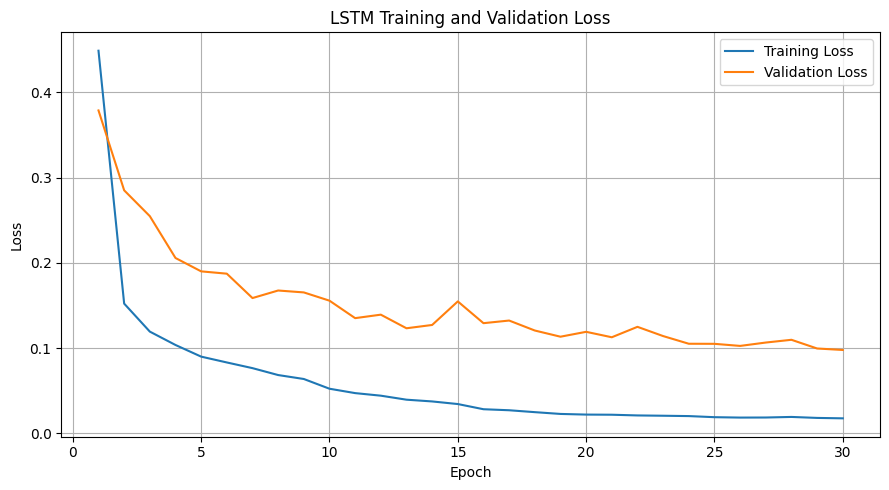

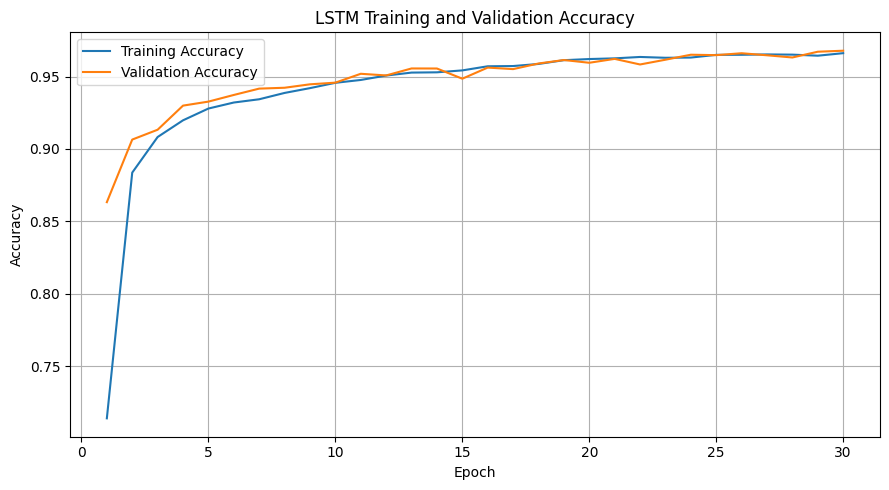

✓ Loss and accuracy learning curves generated.

[10] CONVERGENCE INTERPRETATION
---------------------------------------------------------------------------
✓ The final epoch corresponds to the best recorded validation performance.
✓ The model demonstrates overall learning and convergence through the training run.
✓ The configured maximum epoch count was reached.

Interpretation should be based on the complete learning curves rather than training accuracy alone.

LEARNING-CURVE ANALYSIS COMPLETE

Key results:
  Best validation loss     : 0.097899 (Epoch 30)
  Best validation accuracy : 0.967864 (96.7864%) (Epoch 30)
  Final training accuracy  : 96.6169%
  Final validation accuracy: 96.7864%
  Final validation loss    : 0.097899

No training or testing tensors were modified.
No independent test evaluation was performed.


In [25]:
# ============================================================================
# 7.4.10 TRAINING AND VALIDATION LEARNING-CURVE ANALYSIS
# ============================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 75)
print("TRAINING AND VALIDATION LEARNING-CURVE ANALYSIS")
print("=" * 75)

# ---------------------------------------------------------------------------
# [1] VALIDATE TRAINING HISTORY
# ---------------------------------------------------------------------------

print("\n[1] TRAINING HISTORY VALIDATION")
print("-" * 75)

if history is None:
    raise ValueError("Training history object 'history' is not available.")

history_keys = list(history.history.keys())

print("Available history metrics:")
for key in history_keys:
    print(f"  - {key}")

required_metrics = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy"
]

missing_metrics = [
    metric for metric in required_metrics
    if metric not in history.history
]

if missing_metrics:
    raise ValueError(
        f"Required history metrics are missing: {missing_metrics}"
    )

print("✓ Required training and validation metrics are available.")


# ---------------------------------------------------------------------------
# [2] EXTRACT HISTORY WITHOUT COPYING SEQUENCE TENSORS
# ---------------------------------------------------------------------------

print("\n[2] EXTRACTING LEARNING-CURVE METRICS")
print("-" * 75)

train_loss = np.asarray(history.history["loss"])
val_loss = np.asarray(history.history["val_loss"])
train_accuracy = np.asarray(history.history["accuracy"])
val_accuracy = np.asarray(history.history["val_accuracy"])

epochs = np.arange(1, len(train_loss) + 1)

print(f"Epochs recorded : {len(epochs)}")
print(f"Training loss values     : {len(train_loss)}")
print(f"Validation loss values   : {len(val_loss)}")
print(f"Training accuracy values : {len(train_accuracy)}")
print(f"Validation accuracy values : {len(val_accuracy)}")

if "learning_rate" in history.history:
    learning_rates = np.asarray(history.history["learning_rate"])
    print(f"Learning-rate values     : {len(learning_rates)}")
else:
    learning_rates = None
    print("Learning-rate history    : Not available")

print("✓ Learning-curve data extracted from the existing history object.")


# ---------------------------------------------------------------------------
# [3] BEST VALIDATION PERFORMANCE
# ---------------------------------------------------------------------------

print("\n[3] BEST VALIDATION PERFORMANCE")
print("-" * 75)

best_val_loss_index = int(np.argmin(val_loss))
best_val_accuracy_index = int(np.argmax(val_accuracy))

best_val_loss_epoch = best_val_loss_index + 1
best_val_accuracy_epoch = best_val_accuracy_index + 1

best_val_loss = float(val_loss[best_val_loss_index])
best_val_accuracy = float(val_accuracy[best_val_accuracy_index])

best_val_loss_train_accuracy = float(
    train_accuracy[best_val_loss_index]
)

best_val_accuracy_train_accuracy = float(
    train_accuracy[best_val_accuracy_index]
)

print(
    f"Best validation loss      : {best_val_loss:.6f} "
    f"(Epoch {best_val_loss_epoch})"
)

print(
    f"Best validation accuracy  : {best_val_accuracy:.6f} "
    f"({best_val_accuracy * 100:.4f}%) "
    f"(Epoch {best_val_accuracy_epoch})"
)

print(
    f"Training accuracy at best validation-loss epoch : "
    f"{best_val_loss_train_accuracy:.6f}"
)

print(
    f"Training accuracy at best validation-accuracy epoch : "
    f"{best_val_accuracy_train_accuracy:.6f}"
)


# ---------------------------------------------------------------------------
# [4] FINAL EPOCH PERFORMANCE
# ---------------------------------------------------------------------------

print("\n[4] FINAL EPOCH PERFORMANCE")
print("-" * 75)

final_epoch = len(epochs)

final_train_loss = float(train_loss[-1])
final_val_loss = float(val_loss[-1])
final_train_accuracy = float(train_accuracy[-1])
final_val_accuracy = float(val_accuracy[-1])

print(f"Final epoch              : {final_epoch}")
print(f"Final training loss      : {final_train_loss:.6f}")
print(f"Final validation loss    : {final_val_loss:.6f}")
print(
    f"Final training accuracy  : {final_train_accuracy:.6f} "
    f"({final_train_accuracy * 100:.4f}%)"
)
print(
    f"Final validation accuracy: {final_val_accuracy:.6f} "
    f"({final_val_accuracy * 100:.4f}%)"
)


# ---------------------------------------------------------------------------
# [5] TRAINING-VALIDATION ACCURACY GAP
# ---------------------------------------------------------------------------

print("\n[5] TRAINING-VALIDATION ACCURACY GAP")
print("-" * 75)

accuracy_gap = final_train_accuracy - final_val_accuracy

print(f"Final training accuracy   : {final_train_accuracy:.6f}")
print(f"Final validation accuracy : {final_val_accuracy:.6f}")
print(f"Training - validation gap : {accuracy_gap:.6f}")

if accuracy_gap > 0:
    print(
        "Training accuracy is higher than validation accuracy, "
        "as commonly expected."
    )
elif accuracy_gap < 0:
    print(
        "Validation accuracy is higher than training accuracy. "
        "This can occur when dropout and class weighting are active "
        "during training."
    )
else:
    print("Training and validation accuracy are equal.")

print("✓ Accuracy relationship inspected.")


# ---------------------------------------------------------------------------
# [6] VALIDATION-LOSS TREND
# ---------------------------------------------------------------------------

print("\n[6] VALIDATION-LOSS TREND")
print("-" * 75)

initial_val_loss = float(val_loss[0])
final_val_loss = float(val_loss[-1])

val_loss_change = final_val_loss - initial_val_loss

print(f"Initial validation loss : {initial_val_loss:.6f}")
print(f"Final validation loss   : {final_val_loss:.6f}")
print(f"Change                  : {val_loss_change:.6f}")

if final_val_loss < initial_val_loss:
    print("✓ Validation loss decreased overall during training.")
else:
    print("⚠ Validation loss did not decrease overall.")


# ---------------------------------------------------------------------------
# [7] VALIDATION-ACCURACY TREND
# ---------------------------------------------------------------------------

print("\n[7] VALIDATION-ACCURACY TREND")
print("-" * 75)

initial_val_accuracy = float(val_accuracy[0])
final_val_accuracy = float(val_accuracy[-1])

val_accuracy_change = final_val_accuracy - initial_val_accuracy

print(
    f"Initial validation accuracy : "
    f"{initial_val_accuracy:.6f} "
    f"({initial_val_accuracy * 100:.4f}%)"
)

print(
    f"Final validation accuracy   : "
    f"{final_val_accuracy:.6f} "
    f"({final_val_accuracy * 100:.4f}%)"
)

print(
    f"Accuracy improvement        : "
    f"{val_accuracy_change:.6f} "
    f"({val_accuracy_change * 100:.4f} percentage points)"
)

if final_val_accuracy > initial_val_accuracy:
    print("✓ Validation accuracy improved overall.")
else:
    print("⚠ Validation accuracy did not improve overall.")


# ---------------------------------------------------------------------------
# [8] LEARNING-RATE HISTORY
# ---------------------------------------------------------------------------

print("\n[8] LEARNING-RATE SCHEDULE")
print("-" * 75)

if learning_rates is not None:
    unique_learning_rates = np.unique(learning_rates)

    print(f"Initial learning rate : {learning_rates[0]:.10f}")
    print(f"Final learning rate   : {learning_rates[-1]:.10f}")
    print(
        f"Distinct learning rates used : "
        f"{len(unique_learning_rates)}"
    )

    for lr in unique_learning_rates:
        print(f"  {lr:.10f}")

    print("✓ Learning-rate reductions recorded.")
else:
    print("Learning-rate history is unavailable.")


# ---------------------------------------------------------------------------
# [9] LEARNING-CURVE VISUALIZATION
# ---------------------------------------------------------------------------

print("\n[9] GENERATING LEARNING CURVES")
print("-" * 75)

# Loss curve
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Accuracy curve
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_accuracy, label="Training Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("✓ Loss and accuracy learning curves generated.")


# ---------------------------------------------------------------------------
# [10] CONVERGENCE INTERPRETATION
# ---------------------------------------------------------------------------

print("\n[10] CONVERGENCE INTERPRETATION")
print("-" * 75)

if (
    final_val_accuracy >= best_val_accuracy - 1e-12
    and final_val_loss <= best_val_loss + 1e-12
):
    print(
        "✓ The final epoch corresponds to the best recorded validation "
        "performance."
    )

if final_val_loss < initial_val_loss and final_val_accuracy > initial_val_accuracy:
    print(
        "✓ The model demonstrates overall learning and convergence "
        "through the training run."
    )

if final_epoch >= 30:
    print(
        "✓ The configured maximum epoch count was reached."
    )

print(
    "\nInterpretation should be based on the complete learning curves "
    "rather than training accuracy alone."
)

print("\n" + "=" * 75)
print("LEARNING-CURVE ANALYSIS COMPLETE")
print("=" * 75)

print("\nKey results:")
print(f"  Best validation loss     : {best_val_loss:.6f} (Epoch {best_val_loss_epoch})")
print(
    f"  Best validation accuracy : "
    f"{best_val_accuracy:.6f} "
    f"({best_val_accuracy * 100:.4f}%) "
    f"(Epoch {best_val_accuracy_epoch})"
)
print(
    f"  Final training accuracy  : "
    f"{final_train_accuracy * 100:.4f}%"
)
print(
    f"  Final validation accuracy: "
    f"{final_val_accuracy * 100:.4f}%"
)
print(f"  Final validation loss    : {final_val_loss:.6f}")

print("\nNo training or testing tensors were modified.")
print("No independent test evaluation was performed.")

## 7.4.11 Independent LSTM Test Evaluation

The trained LSTM model is evaluated on the completely reserved testing
partition to obtain an unbiased estimate of its final classification
performance.

The testing sequences were not used during model training, validation,
hyperparameter selection, class-weight calculation, or learning-rate
adaptation. Therefore, this evaluation represents an independent
assessment of the finalized LSTM model.

The evaluation includes:

1. Validation of the testing feature and target tensors.
2. Verification of testing data types and numerical validity.
3. Inspection of the target class distribution in the test partition.
4. Evaluation of the trained LSTM model using the reserved test data.
5. Generation and validation of class-probability predictions.
6. Inspection of the predicted class distribution.
7. Reporting of final test loss and test accuracy.
8. Verification that predictions contain valid class labels and
   probability distributions.

The test partition will remain untouched after this evaluation and will
not be used for any further model training or parameter adjustment.

In [27]:
# ===========================================================================
# 7.4.11 INDEPENDENT LSTM TEST EVALUATION
# ===========================================================================

import numpy as np
import psutil


print("=" * 75)
print("INDEPENDENT LSTM TEST EVALUATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] TEST DATA VALIDATION
# ---------------------------------------------------------------------------

print("\n[1] TEST DATA VALIDATION")
print("-" * 75)

print(f"Testing feature sequences : {X_test_LSTM.shape}")
print(f"Testing target sequences  : {y_test_LSTM.shape}")

assert X_test_LSTM.ndim == 3
assert X_test_LSTM.shape[1] == 5
assert X_test_LSTM.shape[2] == 63

assert y_test_LSTM.ndim == 1
assert X_test_LSTM.shape[0] == y_test_LSTM.shape[0]

print("✓ Testing feature tensor is correctly shaped.")
print("✓ Testing target tensor is correctly shaped.")
print("✓ Testing feature and target counts are consistent.")


# ---------------------------------------------------------------------------
# [2] TEST DATA TYPE VALIDATION
# ---------------------------------------------------------------------------

print("\n[2] TEST DATA TYPE VALIDATION")
print("-" * 75)

print(f"Testing feature dtype : {X_test_LSTM.dtype}")
print(f"Testing target dtype  : {y_test_LSTM.dtype}")

assert X_test_LSTM.dtype == np.float32
assert np.issubdtype(y_test_LSTM.dtype, np.integer)

print("✓ Testing targets contain integer class labels.")
print("✓ Testing feature tensor uses float32.")


# ---------------------------------------------------------------------------
# [3] NUMERICAL VALIDITY CHECK
# ---------------------------------------------------------------------------

print("\n[3] NUMERICAL VALIDITY CHECK")
print("-" * 75)

test_nan_count = np.isnan(X_test_LSTM).sum()
test_inf_count = np.isinf(X_test_LSTM).sum()

print(f"Testing NaN values  : {test_nan_count}")
print(f"Testing Inf values  : {test_inf_count}")

assert test_nan_count == 0
assert test_inf_count == 0

print("✓ No NaN or infinite testing features detected.")


# ---------------------------------------------------------------------------
# [4] TEST TARGET CLASS COVERAGE
# ---------------------------------------------------------------------------

print("\n[4] TEST TARGET CLASS COVERAGE")
print("-" * 75)

test_classes, test_class_counts = np.unique(
    y_test_LSTM,
    return_counts=True
)

print(f"Testing classes present : {test_classes.tolist()}")
print(f"Number of classes       : {len(test_classes)}")

for test_class, test_count in zip(test_classes, test_class_counts):
    test_percentage = (test_count / len(y_test_LSTM)) * 100

    print(
        f"Class {int(test_class):2d}: "
        f"{int(test_count):7d} sequences "
        f"({test_percentage:7.4f}%)"
    )

assert np.all((y_test_LSTM >= 0) & (y_test_LSTM < 15))

print("✓ Testing class distribution recorded.")
print("✓ All testing target labels are within the expected range [0, 14].")


# ---------------------------------------------------------------------------
# [5] INDEPENDENT MODEL EVALUATION
# ---------------------------------------------------------------------------

print("\n[5] INDEPENDENT MODEL EVALUATION")
print("-" * 75)

print("Evaluating the trained LSTM model on the reserved test partition...")
print("The test partition is not used for further model training.")

test_loss, test_accuracy = lstm_model.evaluate(
    X_test_LSTM,
    y_test_LSTM,
    batch_size=256,
    verbose=1
)

print("\n✓ Independent test evaluation completed.")


# ---------------------------------------------------------------------------
# [6] TEST PERFORMANCE
# ---------------------------------------------------------------------------

print("\n[6] TEST PERFORMANCE")
print("-" * 75)

print(f"Test loss     : {test_loss:.6f}")
print(f"Test accuracy : {test_accuracy:.6f} ({test_accuracy * 100:.4f}%)")


# ---------------------------------------------------------------------------
# [7] TEST PREDICTION GENERATION
# ---------------------------------------------------------------------------

print("\n[7] TEST PREDICTION GENERATION")
print("-" * 75)

test_prediction_probabilities = lstm_model.predict(
    X_test_LSTM,
    batch_size=256,
    verbose=1
)

test_predicted_labels = np.argmax(
    test_prediction_probabilities,
    axis=1
)

print(
    f"Prediction matrix shape : "
    f"{test_prediction_probabilities.shape}"
)

print(
    f"Predicted labels shape  : "
    f"{test_predicted_labels.shape}"
)

assert test_prediction_probabilities.shape == (
    len(y_test_LSTM),
    15
)

assert test_predicted_labels.shape == y_test_LSTM.shape

print("✓ Test predictions generated.")
print("✓ Prediction and target counts are consistent.")


# ---------------------------------------------------------------------------
# [8] PREDICTION CLASS COVERAGE
# ---------------------------------------------------------------------------

print("\n[8] PREDICTION CLASS COVERAGE")
print("-" * 75)

predicted_classes, predicted_class_counts = np.unique(
    test_predicted_labels,
    return_counts=True
)

print(f"Predicted classes : {predicted_classes.tolist()}")

for predicted_class, predicted_count in zip(
    predicted_classes,
    predicted_class_counts
):
    predicted_percentage = (
        predicted_count / len(test_predicted_labels)
    ) * 100

    print(
        f"Class {int(predicted_class):2d}: "
        f"{int(predicted_count):7d} predictions "
        f"({predicted_percentage:7.4f}%)"
    )

print("✓ Prediction class distribution recorded.")


# ---------------------------------------------------------------------------
# [9] BASIC PREDICTION VALIDATION
# ---------------------------------------------------------------------------

print("\n[9] BASIC PREDICTION VALIDATION")
print("-" * 75)

assert np.all(
    (test_predicted_labels >= 0) &
    (test_predicted_labels < 15)
)

assert test_prediction_probabilities.shape[1] == 15

test_probability_sums = np.sum(
    test_prediction_probabilities,
    axis=1
)

assert np.allclose(
    test_probability_sums,
    1.0,
    atol=1e-5
)

assert np.all(
    test_prediction_probabilities >= 0
)

print("✓ All predicted classes are within the expected range [0, 14].")
print("✓ Prediction output contains 15 class probabilities.")
print("✓ Softmax probability distributions are valid.")


# ---------------------------------------------------------------------------
# [10] RUNTIME MEMORY CHECK
# ---------------------------------------------------------------------------

print("\n[10] RUNTIME MEMORY CHECK")
print("-" * 75)

test_process_memory = psutil.Process().memory_info().rss / (1024 ** 3)
test_system_memory = psutil.virtual_memory()

print(f"Process RAM usage    : {test_process_memory:.2f} GB")
print(f"System RAM total     : {test_system_memory.total / (1024 ** 3):.2f} GB")
print(f"System RAM used      : {test_system_memory.used / (1024 ** 3):.2f} GB")
print(
    f"System RAM available : "
    f"{test_system_memory.available / (1024 ** 3):.2f} GB"
)


# ---------------------------------------------------------------------------
# [11] INDEPENDENT TEST EVALUATION SUMMARY
# ---------------------------------------------------------------------------

print("\n[11] INDEPENDENT TEST EVALUATION SUMMARY")
print("-" * 75)

print(f"Test sequences       : {len(y_test_LSTM):,}")
print(f"Test loss            : {test_loss:.6f}")
print(f"Test accuracy        : {test_accuracy * 100:.4f}%")
print(f"Actual test classes  : {len(test_classes)} / 15")
print(f"Predicted classes    : {len(predicted_classes)} / 15")

print("\n✓ Independent test evaluation completed.")
print("✓ Test partition remained separate from model training.")
print("✓ No testing feature or target tensors were modified.")


print("\n" + "=" * 75)
print("INDEPENDENT LSTM TEST EVALUATION COMPLETE")
print("=" * 75)

INDEPENDENT LSTM TEST EVALUATION

[1] TEST DATA VALIDATION
---------------------------------------------------------------------------
Testing feature sequences : (113229, 5, 63)
Testing target sequences  : (113229,)
✓ Testing feature tensor is correctly shaped.
✓ Testing target tensor is correctly shaped.
✓ Testing feature and target counts are consistent.

[2] TEST DATA TYPE VALIDATION
---------------------------------------------------------------------------
Testing feature dtype : float32
Testing target dtype  : int8
✓ Testing targets contain integer class labels.
✓ Testing feature tensor uses float32.

[3] NUMERICAL VALIDITY CHECK
---------------------------------------------------------------------------
Testing NaN values  : 0
Testing Inf values  : 0
✓ No NaN or infinite testing features detected.

[4] TEST TARGET CLASS COVERAGE
---------------------------------------------------------------------------
Testing classes present : [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14]
N

## 7.4.12 Detailed LSTM Performance Evaluation

The independently evaluated LSTM model is further analyzed using
class-wise Precision, Recall, and F1-Score together with macro and
weighted averages.

Overall accuracy alone is not sufficient for evaluating the present
multi-class intrusion-detection problem because the testing partition
is highly imbalanced. In particular, Class 0 represents the majority
of the testing sequences, while several attack classes contain only a
small number of samples.

Therefore, Precision, Recall, and F1-Score are calculated separately
for each class. Macro-averaged metrics give equal importance to every
class, whereas weighted-averaged metrics account for the number of
samples belonging to each class.

A 15 × 15 confusion matrix is also generated to examine the relationship
between the true and predicted intrusion classes. The confusion matrix
provides a direct view of correctly classified samples and
misclassification patterns between classes.

The evaluation uses the predictions already generated from the
independent testing partition in Section 7.4.11. The test partition is
not used for model training, parameter tuning, or further optimization.

Class 13 requires particular attention because it is present in the
independent testing targets but was absent from the training sequence
targets. Consequently, the model did not receive training examples of
Class 13 and its test performance must be interpreted separately.

No testing features or target tensors are modified during this
evaluation.

DETAILED LSTM PERFORMANCE EVALUATION

[1] EXISTING TEST PREDICTION VALIDATION
---------------------------------------------------------------------------
Testing target sequences : (113229,)
Predicted label sequences : (113229,)
Prediction probability matrix : (113229, 15)
✓ Existing test predictions are available.
✓ Prediction and target dimensions are consistent.

[2] CLASS-WISE PRECISION
---------------------------------------------------------------------------
Class  0: Precision = 0.999429
Class  1: Precision = 0.039695
Class  2: Precision = 0.988012
Class  3: Precision = 0.680000
Class  4: Precision = 0.889368
Class  5: Precision = 0.632716
Class  6: Precision = 0.731343
Class  7: Precision = 0.607143
Class  8: Precision = 0.000000
Class  9: Precision = 0.166667
Class 10: Precision = 0.989271
Class 11: Precision = 0.470711
Class 12: Precision = 0.150000
Class 13: Precision = 0.000000
Class 14: Precision = 0.101449
✓ Class-wise Precision calculated.

[3] CLASS-WISE RECALL
-------

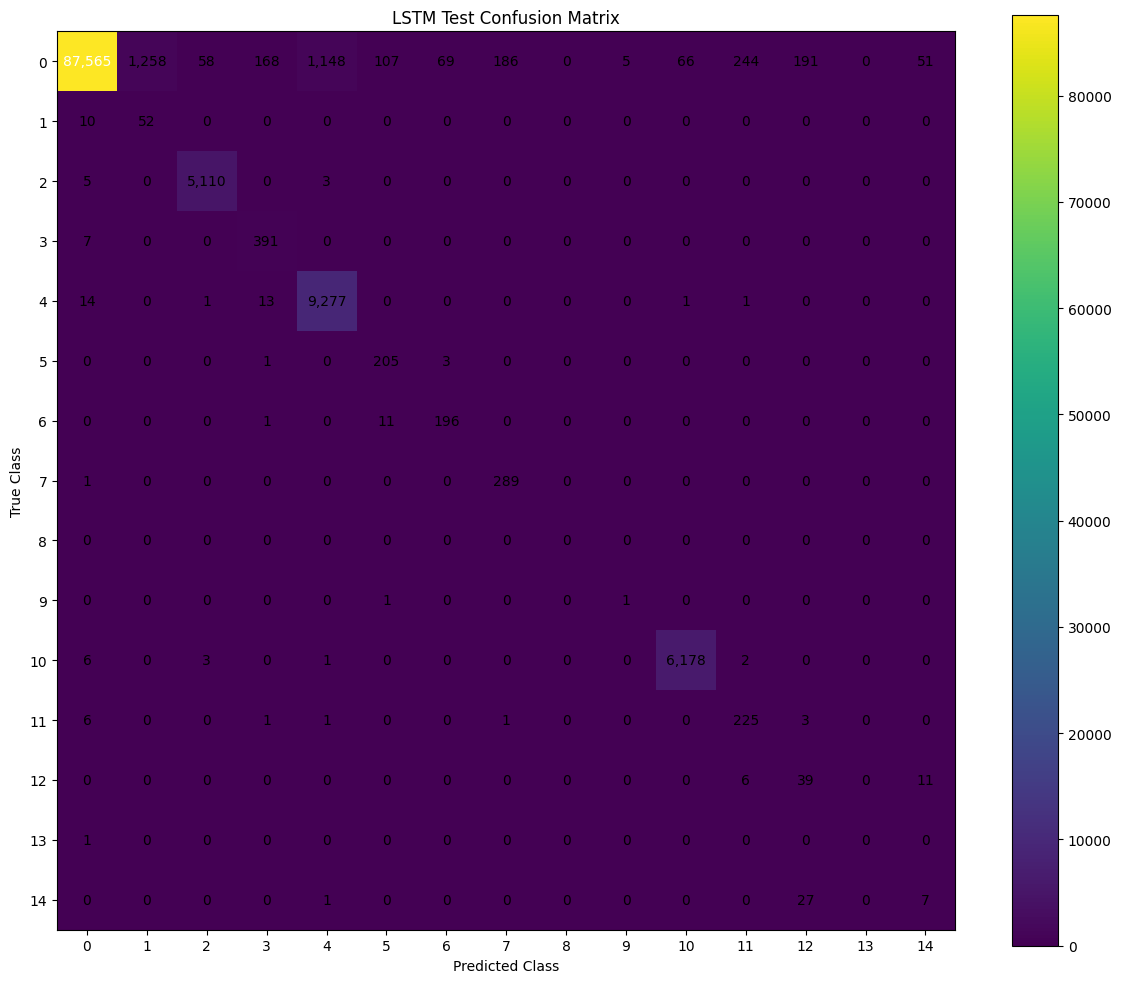

✓ Confusion matrix visualization generated.

[9] CLASS-WISE SUPPORT ANALYSIS
---------------------------------------------------------------------------
Class  0: True =   91116 | Predicted =   87615
Class  1: True =      62 | Predicted =    1310
Class  2: True =    5118 | Predicted =    5172
Class  3: True =     398 | Predicted =     575
Class  4: True =    9307 | Predicted =   10431
Class  5: True =     209 | Predicted =     324
Class  6: True =     208 | Predicted =     268
Class  7: True =     290 | Predicted =     476
Class  8: True =       0 | Predicted =       0
Class  9: True =       2 | Predicted =       6
Class 10: True =    6190 | Predicted =    6245
Class 11: True =     237 | Predicted =     478
Class 12: True =      56 | Predicted =     260
Class 13: True =       1 | Predicted =       0
Class 14: True =      35 | Predicted =      69
✓ True and predicted class support compared.

[10] MINORITY-CLASS OBSERVATION
----------------------------------------------------------------

In [28]:
# ===========================================================================
# 7.4.12 DETAILED LSTM PERFORMANCE EVALUATION
# ===========================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


print("=" * 75)
print("DETAILED LSTM PERFORMANCE EVALUATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] EXISTING TEST PREDICTION VALIDATION
# ---------------------------------------------------------------------------

print("\n[1] EXISTING TEST PREDICTION VALIDATION")
print("-" * 75)

print(
    f"Testing target sequences : "
    f"{y_test_LSTM.shape}"
)

print(
    f"Predicted label sequences : "
    f"{test_predicted_labels.shape}"
)

print(
    f"Prediction probability matrix : "
    f"{test_prediction_probabilities.shape}"
)

assert test_predicted_labels.shape == y_test_LSTM.shape

assert test_prediction_probabilities.shape == (
    len(y_test_LSTM),
    15
)

print("✓ Existing test predictions are available.")
print("✓ Prediction and target dimensions are consistent.")


# ---------------------------------------------------------------------------
# [2] CLASS-WISE PRECISION
# ---------------------------------------------------------------------------

print("\n[2] CLASS-WISE PRECISION")
print("-" * 75)

lstm_test_precision = precision_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average=None,
    zero_division=0
)

for class_id, precision_value in enumerate(lstm_test_precision):
    print(
        f"Class {class_id:2d}: "
        f"Precision = {precision_value:.6f}"
    )

print("✓ Class-wise Precision calculated.")


# ---------------------------------------------------------------------------
# [3] CLASS-WISE RECALL
# ---------------------------------------------------------------------------

print("\n[3] CLASS-WISE RECALL")
print("-" * 75)

lstm_test_recall = recall_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average=None,
    zero_division=0
)

for class_id, recall_value in enumerate(lstm_test_recall):
    print(
        f"Class {class_id:2d}: "
        f"Recall = {recall_value:.6f}"
    )

print("✓ Class-wise Recall calculated.")


# ---------------------------------------------------------------------------
# [4] CLASS-WISE F1-SCORE
# ---------------------------------------------------------------------------

print("\n[4] CLASS-WISE F1-SCORE")
print("-" * 75)

lstm_test_f1 = f1_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average=None,
    zero_division=0
)

for class_id, f1_value in enumerate(lstm_test_f1):
    print(
        f"Class {class_id:2d}: "
        f"F1-Score = {f1_value:.6f}"
    )

print("✓ Class-wise F1-Scores calculated.")


# ---------------------------------------------------------------------------
# [5] MACRO AND WEIGHTED METRICS
# ---------------------------------------------------------------------------

print("\n[5] MACRO AND WEIGHTED METRICS")
print("-" * 75)

lstm_macro_precision = precision_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="macro",
    zero_division=0
)

lstm_macro_recall = recall_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="macro",
    zero_division=0
)

lstm_macro_f1 = f1_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="macro",
    zero_division=0
)

lstm_weighted_precision = precision_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="weighted",
    zero_division=0
)

lstm_weighted_recall = recall_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="weighted",
    zero_division=0
)

lstm_weighted_f1 = f1_score(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    average="weighted",
    zero_division=0
)

print(
    f"Macro Precision    : "
    f"{lstm_macro_precision:.6f}"
)

print(
    f"Macro Recall       : "
    f"{lstm_macro_recall:.6f}"
)

print(
    f"Macro F1-Score     : "
    f"{lstm_macro_f1:.6f}"
)

print(
    f"Weighted Precision : "
    f"{lstm_weighted_precision:.6f}"
)

print(
    f"Weighted Recall    : "
    f"{lstm_weighted_recall:.6f}"
)

print(
    f"Weighted F1-Score  : "
    f"{lstm_weighted_f1:.6f}"
)

print("✓ Macro and weighted metrics calculated.")


# ---------------------------------------------------------------------------
# [6] CLASSIFICATION REPORT
# ---------------------------------------------------------------------------

print("\n[6] CLASSIFICATION REPORT")
print("-" * 75)

lstm_classification_report = classification_report(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15),
    zero_division=0,
    digits=6
)

print(lstm_classification_report)

print("✓ Complete classification report generated.")


# ---------------------------------------------------------------------------
# [7] CONFUSION MATRIX GENERATION
# ---------------------------------------------------------------------------

print("\n[7] CONFUSION MATRIX GENERATION")
print("-" * 75)

lstm_confusion_matrix = confusion_matrix(
    y_test_LSTM,
    test_predicted_labels,
    labels=np.arange(15)
)

print(
    f"Confusion matrix shape : "
    f"{lstm_confusion_matrix.shape}"
)

print("\nConfusion Matrix:")
print(lstm_confusion_matrix)

assert lstm_confusion_matrix.shape == (15, 15)

assert (
    np.sum(lstm_confusion_matrix)
    == len(y_test_LSTM)
)

print("✓ 15 × 15 confusion matrix generated.")
print("✓ Confusion matrix total matches the test sample count.")


# ---------------------------------------------------------------------------
# [8] CONFUSION MATRIX VISUALIZATION
# ---------------------------------------------------------------------------

print("\n[8] CONFUSION MATRIX VISUALIZATION")
print("-" * 75)

plt.figure(figsize=(12, 10))

plt.imshow(
    lstm_confusion_matrix,
    interpolation="nearest"
)

plt.title("LSTM Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    np.arange(15),
    np.arange(15)
)

plt.yticks(
    np.arange(15),
    np.arange(15)
)

plt.colorbar()

matrix_threshold = (
    lstm_confusion_matrix.max() / 2.0
)

for row_index in range(15):
    for column_index in range(15):

        matrix_value = lstm_confusion_matrix[
            row_index,
            column_index
        ]

        plt.text(
            column_index,
            row_index,
            f"{matrix_value:,}",
            ha="center",
            va="center",
            color=(
                "white"
                if matrix_value > matrix_threshold
                else "black"
            )
        )

plt.tight_layout()
plt.show()

print("✓ Confusion matrix visualization generated.")


# ---------------------------------------------------------------------------
# [9] CLASS-WISE SUPPORT ANALYSIS
# ---------------------------------------------------------------------------

print("\n[9] CLASS-WISE SUPPORT ANALYSIS")
print("-" * 75)

for class_id in range(15):

    true_count = int(
        np.sum(y_test_LSTM == class_id)
    )

    predicted_count = int(
        np.sum(test_predicted_labels == class_id)
    )

    print(
        f"Class {class_id:2d}: "
        f"True = {true_count:7d} | "
        f"Predicted = {predicted_count:7d}"
    )

print("✓ True and predicted class support compared.")


# ---------------------------------------------------------------------------
# [10] MINORITY-CLASS OBSERVATION
# ---------------------------------------------------------------------------

print("\n[10] MINORITY-CLASS OBSERVATION")
print("-" * 75)

print(
    "Classes with very small test support should be interpreted "
    "with caution because a small number of samples can strongly "
    "affect their class-wise metrics."
)

class_13_test_count = int(
    np.sum(y_test_LSTM == 13)
)

class_13_predicted_count = int(
    np.sum(test_predicted_labels == 13)
)

print(
    f"Class 13 true test samples      : "
    f"{class_13_test_count}"
)

print(
    f"Class 13 predicted samples      : "
    f"{class_13_predicted_count}"
)

print(
    "Class 13 was absent from the LSTM training targets and is "
    "therefore evaluated as an unseen training class."
)


# ---------------------------------------------------------------------------
# [11] PERFORMANCE SUMMARY
# ---------------------------------------------------------------------------

print("\n[11] PERFORMANCE SUMMARY")
print("-" * 75)

print(
    f"Test Accuracy       : "
    f"{test_accuracy:.6f} "
    f"({test_accuracy * 100:.4f}%)"
)

print(
    f"Test Loss           : "
    f"{test_loss:.6f}"
)

print(
    f"Macro Precision     : "
    f"{lstm_macro_precision:.6f}"
)

print(
    f"Macro Recall        : "
    f"{lstm_macro_recall:.6f}"
)

print(
    f"Macro F1-Score      : "
    f"{lstm_macro_f1:.6f}"
)

print(
    f"Weighted Precision  : "
    f"{lstm_weighted_precision:.6f}"
)

print(
    f"Weighted Recall     : "
    f"{lstm_weighted_recall:.6f}"
)

print(
    f"Weighted F1-Score   : "
    f"{lstm_weighted_f1:.6f}"
)


# ---------------------------------------------------------------------------
# [12] FINAL EVALUATION VALIDATION
# ---------------------------------------------------------------------------

print("\n[12] FINAL EVALUATION VALIDATION")
print("-" * 75)

assert len(lstm_test_precision) == 15
assert len(lstm_test_recall) == 15
assert len(lstm_test_f1) == 15

assert 0.0 <= lstm_macro_precision <= 1.0
assert 0.0 <= lstm_macro_recall <= 1.0
assert 0.0 <= lstm_macro_f1 <= 1.0

assert 0.0 <= lstm_weighted_precision <= 1.0
assert 0.0 <= lstm_weighted_recall <= 1.0
assert 0.0 <= lstm_weighted_f1 <= 1.0

print("✓ All 15 class metrics are available.")
print("✓ Macro metrics are numerically valid.")
print("✓ Weighted metrics are numerically valid.")
print("✓ Confusion matrix is valid.")
print("✓ Independent test predictions remain unchanged.")


print("\n" + "=" * 75)
print("DETAILED LSTM PERFORMANCE EVALUATION COMPLETE")
print("=" * 75)

# 7.4.13 LSTM Class-Wise Error Analysis

## Purpose

The detailed performance evaluation established the overall and class-wise predictive behaviour of the finalized LSTM model.

This section performs a focused class-wise error analysis using the already-generated independent test predictions, classification metrics, and confusion matrix.

The purpose is to identify:

- Classes with strong predictive performance.
- Classes affected by false positives.
- Classes affected by false negatives.
- Important class confusions.
- The effect of severe class imbalance on minority-class performance.
- Classes that require caution when interpreting the overall accuracy.

No additional model training is performed in this section. The existing trained LSTM model and its independent test predictions are used for analysis.

## Objectives

The objectives of this section are to:

1. Quantify true positives, false positives, false negatives, and true negatives for each class.
2. Calculate class-wise error rates from the independent test predictions.
3. Identify the classes with the highest false-positive counts.
4. Identify the classes with the highest false-negative counts.
5. Examine the major confusion pairs observed in the test confusion matrix.
6. Relate class-wise errors to precision, recall, and F1-score.
7. Investigate the effect of severe class imbalance on minority-class performance.
8. Distinguish meaningful model errors from observations caused by extremely small class support.
9. Document the principal strengths and weaknesses of the finalized LSTM model.

## Error Analysis Methodology

For each class, the existing test predictions are treated as a one-vs-rest classification problem.

For a given class:

- **True Positive (TP):** samples belonging to the class and correctly predicted as that class.
- **False Positive (FP):** samples from other classes incorrectly predicted as that class.
- **False Negative (FN):** samples belonging to the class but predicted as another class.
- **True Negative (TN):** samples neither belonging to nor predicted as the class.

The following error measures are considered:

**False Positive Rate:**

\[
FPR = \frac{FP}{FP + TN}
\]

**False Negative Rate:**

\[
FNR = \frac{FN}{TP + FN}
\]

The class-wise error analysis is interpreted together with precision, recall, F1-score, and test-set support rather than relying on any single metric.

## Confusion Analysis

The confusion matrix generated during the independent test evaluation is used to identify the most important class-to-class prediction errors.

Particular attention is given to:

- Large off-diagonal confusion counts.
- Classes receiving substantially more predictions than their true support.
- Classes whose samples are frequently assigned to another class.
- Minority classes with very small test support.

## Minority-Class Consideration

The test partition is highly imbalanced, with some classes containing only a very small number of samples.

Therefore, class-wise metrics for extremely small classes must be interpreted cautiously.

A high or low percentage calculated from one or a few samples does not necessarily provide strong evidence of general model behaviour.

The analysis therefore considers both the measured metric and the corresponding class support.

## Expected Outcome

At the end of this section, the major class-wise strengths, weaknesses, false-positive patterns, false-negative patterns, and important confusion relationships of the finalized LSTM model will be documented.

These findings will provide evidence for the final LSTM configuration decision in Section 7.4.14.

In [29]:
# ===========================================================================
# 7.4.13 LSTM CLASS-WISE ERROR ANALYSIS
# ===========================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix


print("=" * 75)
print("LSTM CLASS-WISE ERROR ANALYSIS")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] EXISTING TEST PREDICTION VALIDATION
# ---------------------------------------------------------------------------

print("\n[1] EXISTING TEST PREDICTION VALIDATION")
print("-" * 75)

print(f"Test target sequences     : {y_test_LSTM.shape}")
print(f"Predicted label sequences : {test_predicted_labels.shape}")

assert y_test_LSTM.ndim == 1
assert test_predicted_labels.ndim == 1
assert y_test_LSTM.shape == test_predicted_labels.shape

print("✓ Existing independent test targets are available.")
print("✓ Existing independent test predictions are available.")
print("✓ Target and prediction dimensions are consistent.")


# ---------------------------------------------------------------------------
# [2] CONFUSION MATRIX RECONSTRUCTION
# ---------------------------------------------------------------------------

print("\n[2] CONFUSION MATRIX RECONSTRUCTION")
print("-" * 75)

NUM_CLASSES = 15
CLASS_LABELS = np.arange(NUM_CLASSES)

lstm_error_confusion_matrix = confusion_matrix(
    y_test_LSTM,
    test_predicted_labels,
    labels=CLASS_LABELS
)

print(
    f"Confusion matrix shape : "
    f"{lstm_error_confusion_matrix.shape}"
)

assert lstm_error_confusion_matrix.shape == (
    NUM_CLASSES,
    NUM_CLASSES
)

assert (
    lstm_error_confusion_matrix.sum()
    == len(y_test_LSTM)
)

print("✓ 15 × 15 confusion matrix reconstructed.")
print("✓ Confusion matrix total matches test sample count.")


# ---------------------------------------------------------------------------
# [3] CLASS-WISE TP / FP / FN / TN
# ---------------------------------------------------------------------------

print("\n[3] CLASS-WISE ERROR COMPONENTS")
print("-" * 75)

total_test_samples = len(y_test_LSTM)

class_error_records = []

for class_id in CLASS_LABELS:

    true_positive = int(
        lstm_error_confusion_matrix[class_id, class_id]
    )

    false_positive = int(
        lstm_error_confusion_matrix[:, class_id].sum()
        - true_positive
    )

    false_negative = int(
        lstm_error_confusion_matrix[class_id, :].sum()
        - true_positive
    )

    true_negative = int(
        total_test_samples
        - true_positive
        - false_positive
        - false_negative
    )

    actual_support = int(
        lstm_error_confusion_matrix[class_id, :].sum()
    )

    predicted_support = int(
        lstm_error_confusion_matrix[:, class_id].sum()
    )

    if actual_support > 0:
        false_negative_rate = (
            false_negative / actual_support
        )
    else:
        false_negative_rate = 0.0

    non_class_samples = total_test_samples - actual_support

    if non_class_samples > 0:
        false_positive_rate = (
            false_positive / non_class_samples
        )
    else:
        false_positive_rate = 0.0

    if predicted_support > 0:
        precision = (
            true_positive / predicted_support
        )
    else:
        precision = 0.0

    if actual_support > 0:
        recall = (
            true_positive / actual_support
        )
    else:
        recall = 0.0

    class_error_records.append({
        "Class": int(class_id),
        "Actual Support": actual_support,
        "Predicted Support": predicted_support,
        "TP": true_positive,
        "FP": false_positive,
        "FN": false_negative,
        "TN": true_negative,
        "FPR": false_positive_rate,
        "FNR": false_negative_rate,
        "Precision": precision,
        "Recall": recall
    })


class_error_df = pd.DataFrame(class_error_records)

print(
    class_error_df[
        [
            "Class",
            "Actual Support",
            "Predicted Support",
            "TP",
            "FP",
            "FN",
            "TN"
        ]
    ].to_string(index=False)
)

print("\n✓ TP, FP, FN, and TN calculated for all 15 classes.")


# ---------------------------------------------------------------------------
# [4] CLASS-WISE ERROR RATES
# ---------------------------------------------------------------------------

print("\n[4] CLASS-WISE ERROR RATES")
print("-" * 75)

error_rate_display = class_error_df[
    [
        "Class",
        "Actual Support",
        "Predicted Support",
        "FPR",
        "FNR",
        "Precision",
        "Recall"
    ]
].copy()

print(error_rate_display.to_string(
    index=False,
    formatters={
        "FPR": "{:.6f}".format,
        "FNR": "{:.6f}".format,
        "Precision": "{:.6f}".format,
        "Recall": "{:.6f}".format
    }
))

print("\n✓ Class-wise FPR and FNR calculated.")
print("✓ Error rates are interpreted together with class support.")


# ---------------------------------------------------------------------------
# [5] FALSE-POSITIVE ANALYSIS
# ---------------------------------------------------------------------------

print("\n[5] FALSE-POSITIVE ANALYSIS")
print("-" * 75)

fp_analysis = class_error_df[
    [
        "Class",
        "Actual Support",
        "Predicted Support",
        "TP",
        "FP",
        "Precision"
    ]
].sort_values(
    by="FP",
    ascending=False
)

print("Classes ranked by false-positive count:\n")

print(fp_analysis.to_string(
    index=False,
    formatters={
        "Precision": "{:.6f}".format
    }
))

highest_fp_class = int(
    fp_analysis.iloc[0]["Class"]
)

highest_fp_count = int(
    fp_analysis.iloc[0]["FP"]
)

print(
    f"\nHighest false-positive count : "
    f"Class {highest_fp_class} "
    f"({highest_fp_count:,} false positives)"
)

print("✓ False-positive behaviour identified.")


# ---------------------------------------------------------------------------
# [6] FALSE-NEGATIVE ANALYSIS
# ---------------------------------------------------------------------------

print("\n[6] FALSE-NEGATIVE ANALYSIS")
print("-" * 75)

fn_analysis = class_error_df[
    [
        "Class",
        "Actual Support",
        "Predicted Support",
        "TP",
        "FN",
        "Recall"
    ]
].sort_values(
    by="FN",
    ascending=False
)

print("Classes ranked by false-negative count:\n")

print(fn_analysis.to_string(
    index=False,
    formatters={
        "Recall": "{:.6f}".format
    }
))

highest_fn_class = int(
    fn_analysis.iloc[0]["Class"]
)

highest_fn_count = int(
    fn_analysis.iloc[0]["FN"]
)

print(
    f"\nHighest false-negative count : "
    f"Class {highest_fn_class} "
    f"({highest_fn_count:,} false negatives)"
)

print("✓ False-negative behaviour identified.")


# ---------------------------------------------------------------------------
# [7] MAJOR CONFUSION PAIR ANALYSIS
# ---------------------------------------------------------------------------

print("\n[7] MAJOR CONFUSION PAIR ANALYSIS")
print("-" * 75)

confusion_pairs = []

for true_class in CLASS_LABELS:
    for predicted_class in CLASS_LABELS:

        if true_class == predicted_class:
            continue

        confusion_count = int(
            lstm_error_confusion_matrix[
                true_class,
                predicted_class
            ]
        )

        if confusion_count > 0:
            confusion_pairs.append({
                "True Class": int(true_class),
                "Predicted Class": int(predicted_class),
                "Confusion Count": confusion_count
            })


confusion_pairs_df = pd.DataFrame(
    confusion_pairs
)

if len(confusion_pairs_df) > 0:

    confusion_pairs_df = confusion_pairs_df.sort_values(
        by="Confusion Count",
        ascending=False
    ).reset_index(drop=True)

    print(
        "Top class-to-class confusion pairs:\n"
    )

    print(
        confusion_pairs_df.head(15).to_string(
            index=False
        )
    )

else:

    print(
        "No off-diagonal classification errors were detected."
    )


print("\n✓ Major off-diagonal confusion pairs identified.")


# ---------------------------------------------------------------------------
# [8] ACTUAL VS PREDICTED SUPPORT ANALYSIS
# ---------------------------------------------------------------------------

print("\n[8] ACTUAL VS PREDICTED SUPPORT ANALYSIS")
print("-" * 75)

support_analysis = class_error_df[
    [
        "Class",
        "Actual Support",
        "Predicted Support"
    ]
].copy()

support_analysis["Support Difference"] = (
    support_analysis["Predicted Support"]
    - support_analysis["Actual Support"]
)

support_analysis["Prediction / Actual Ratio"] = np.where(
    support_analysis["Actual Support"] > 0,
    support_analysis["Predicted Support"]
    / support_analysis["Actual Support"],
    np.nan
)

print(
    support_analysis.to_string(
        index=False,
        formatters={
            "Prediction / Actual Ratio":
                lambda x: (
                    f"{x:.4f}"
                    if pd.notna(x)
                    else "N/A"
                )
        }
    )
)

print(
    "\n✓ Actual and predicted class support compared."
)


# ---------------------------------------------------------------------------
# [9] MINORITY-CLASS ERROR OBSERVATION
# ---------------------------------------------------------------------------

print("\n[9] MINORITY-CLASS ERROR OBSERVATION")
print("-" * 75)

MINORITY_SUPPORT_THRESHOLD = 100

minority_classes_df = class_error_df[
    class_error_df["Actual Support"]
    <= MINORITY_SUPPORT_THRESHOLD
].copy()

print(
    f"Minority-support threshold : "
    f"{MINORITY_SUPPORT_THRESHOLD} samples"
)

print(
    f"Classes at or below threshold : "
    f"{len(minority_classes_df)}"
)

if len(minority_classes_df) > 0:

    print("\nMinority-support classes:\n")

    print(
        minority_classes_df[
            [
                "Class",
                "Actual Support",
                "Predicted Support",
                "TP",
                "FP",
                "FN",
                "FPR",
                "FNR",
                "Precision",
                "Recall"
            ]
        ].to_string(
            index=False,
            formatters={
                "FPR": "{:.6f}".format,
                "FNR": "{:.6f}".format,
                "Precision": "{:.6f}".format,
                "Recall": "{:.6f}".format
            }
        )
    )

    print(
        "\n⚠ Minority-class metrics should be interpreted "
        "with caution because of limited test support."
    )

else:

    print(
        "No classes fall below the minority-support threshold."
    )


# ---------------------------------------------------------------------------
# [10] MOST IMPORTANT ERROR OBSERVATIONS
# ---------------------------------------------------------------------------

print("\n[10] MOST IMPORTANT ERROR OBSERVATIONS")
print("-" * 75)

# Largest off-diagonal confusion
if len(confusion_pairs_df) > 0:

    largest_confusion = confusion_pairs_df.iloc[0]

    print(
        f"1. Largest individual confusion: "
        f"True Class {int(largest_confusion['True Class'])} "
        f"→ Predicted Class "
        f"{int(largest_confusion['Predicted Class'])} "
        f"= {int(largest_confusion['Confusion Count']):,} samples."
    )

# Highest FP
print(
    f"2. Highest false-positive count: "
    f"Class {highest_fp_class} "
    f"= {highest_fp_count:,} samples."
)

# Highest FN
print(
    f"3. Highest false-negative count: "
    f"Class {highest_fn_class} "
    f"= {highest_fn_count:,} samples."
)

# Highest FNR among classes with meaningful support
meaningful_support_df = class_error_df[
    class_error_df["Actual Support"] >= MINORITY_SUPPORT_THRESHOLD
]

if len(meaningful_support_df) > 0:

    highest_meaningful_fnr = meaningful_support_df.loc[
        meaningful_support_df["FNR"].idxmax()
    ]

    print(
        f"4. Highest FNR among classes with at least "
        f"{MINORITY_SUPPORT_THRESHOLD} test samples: "
        f"Class {int(highest_meaningful_fnr['Class'])} "
        f"= {highest_meaningful_fnr['FNR']:.4f}."
    )

# Lowest precision among meaningful-support classes
if len(meaningful_support_df) > 0:

    lowest_meaningful_precision = meaningful_support_df.loc[
        meaningful_support_df["Precision"].idxmin()
    ]

    print(
        f"5. Lowest precision among classes with at least "
        f"{MINORITY_SUPPORT_THRESHOLD} test samples: "
        f"Class {int(lowest_meaningful_precision['Class'])} "
        f"= {lowest_meaningful_precision['Precision']:.4f}."
    )


# ---------------------------------------------------------------------------
# [11] ERROR ANALYSIS VALIDATION
# ---------------------------------------------------------------------------

print("\n[11] ERROR ANALYSIS VALIDATION")
print("-" * 75)

# Every actual sample must be represented by TP + FN
assert np.all(
    class_error_df["TP"]
    + class_error_df["FN"]
    == class_error_df["Actual Support"]
)

# Every predicted sample must be represented by TP + FP
assert np.all(
    class_error_df["TP"]
    + class_error_df["FP"]
    == class_error_df["Predicted Support"]
)

# Every one-vs-rest partition must equal total samples
assert np.all(
    class_error_df["TP"]
    + class_error_df["FP"]
    + class_error_df["FN"]
    + class_error_df["TN"]
    == total_test_samples
)

# Total false negatives must equal total false positives
assert (
    class_error_df["FN"].sum()
    == class_error_df["FP"].sum()
)

# Confusion matrix total must match test set
assert (
    lstm_error_confusion_matrix.sum()
    == total_test_samples
)

print("✓ TP + FN equals actual class support.")
print("✓ TP + FP equals predicted class support.")
print("✓ TP + FP + FN + TN equals total test samples.")
print("✓ Total false positives equal total false negatives.")
print("✓ Error-analysis calculations are internally consistent.")


# ---------------------------------------------------------------------------
# [12] FINAL CLASS-WISE ERROR ANALYSIS SUMMARY
# ---------------------------------------------------------------------------

print("\n[12] FINAL CLASS-WISE ERROR ANALYSIS SUMMARY")
print("-" * 75)

print(
    f"Test samples analyzed : "
    f"{total_test_samples:,}"
)

print(
    f"Total false positives : "
    f"{int(class_error_df['FP'].sum()):,}"
)

print(
    f"Total false negatives : "
    f"{int(class_error_df['FN'].sum()):,}"
)

print(
    f"Classes analyzed      : "
    f"{NUM_CLASSES} / {NUM_CLASSES}"
)

print(
    f"Minority classes "
    f"(support <= {MINORITY_SUPPORT_THRESHOLD}) : "
    f"{len(minority_classes_df)}"
)

print(
    "\n✓ Class-wise false-positive and false-negative behaviour analyzed."
)

print(
    "✓ Major confusion relationships identified."
)

print(
    "✓ Minority-class support considered during interpretation."
)

print(
    "✓ Error analysis is based entirely on the independent test predictions."
)


print("\n" + "=" * 75)
print("LSTM CLASS-WISE ERROR ANALYSIS COMPLETE")
print("=" * 75)

LSTM CLASS-WISE ERROR ANALYSIS

[1] EXISTING TEST PREDICTION VALIDATION
---------------------------------------------------------------------------
Test target sequences     : (113229,)
Predicted label sequences : (113229,)
✓ Existing independent test targets are available.
✓ Existing independent test predictions are available.
✓ Target and prediction dimensions are consistent.

[2] CONFUSION MATRIX RECONSTRUCTION
---------------------------------------------------------------------------
Confusion matrix shape : (15, 15)
✓ 15 × 15 confusion matrix reconstructed.
✓ Confusion matrix total matches test sample count.

[3] CLASS-WISE ERROR COMPONENTS
---------------------------------------------------------------------------
 Class  Actual Support  Predicted Support    TP   FP   FN     TN
     0           91116              87615 87565   50 3551  22063
     1              62               1310    52 1258   10 111909
     2            5118               5172  5110   62    8 108049
     3   

# ===========================================================================
# 7.4.14 FINAL LSTM CONFIGURATION SELECTION AND DOCUMENTATION
# ===========================================================================

## Purpose

This section records the final LSTM configuration selected for the network
intrusion detection task based on the training, validation, independent test
evaluation, detailed performance evaluation, and class-wise error analysis
completed in the preceding sections.

The purpose of this section is documentation and configuration verification.
The LSTM model is not retrained or modified at this stage.

---

## Final Configuration Selection

The final LSTM configuration is retained as the trained model configuration
that produced the evaluated independent-test results.

The configuration is documented with respect to:

- Input feature representation
- Number of input features
- Sequence length
- Number of output classes
- LSTM architecture
- Regularization components
- Optimizer and learning-rate configuration
- Batch size
- Training configuration
- Validation strategy
- Class-weight strategy
- Final model-selection rationale

The final configuration is retained without further architectural modification
because the model has already been evaluated on the reserved independent test
partition.

---

## Input Representation

The LSTM operates on sequential network-flow observations rather than treating
each network-flow record as an independent observation.

The established LSTM input representation is:

- Sequence length: **5**
- Features per timestep: **63**
- Input tensor format: **(samples, 5, 63)**
- Output classes: **15**
- Target representation: Integer class labels

The independent test partition therefore contains sequences represented as:

**(113,229, 5, 63)**

with **113,229** corresponding target labels.

---

## Data Splitting and Validation Strategy

The established data-splitting strategy is retained for reproducibility.

The training data was divided using an explicit randomized **80/20 split**
with **random seed 42**.

The resulting partitions were:

- Training samples: **362,335**
- Validation samples: **90,583**
- Combined training/validation samples: **452,918**

The independent test partition remained reserved and was not used for model
training or configuration optimization.

The test partition was used only for the final independent evaluation reported
in the preceding sections.

---

## Class-Weight Strategy

Class weights were applied during model training to account for the severe
class imbalance present in the intrusion-detection dataset.

The class-weight mechanism was restricted to the training process.

No class-weight adjustment was applied to the independent test targets or to
the reported test predictions.

The independent test evaluation therefore reflects the model's predictions on
the original reserved test distribution.

---

## Sequence Construction

The established sequence construction strategy is retained without further
modification.

The final evaluation uses the same sequence representation established
during model development.

No additional sequence generation, sequence-length modification, resampling,
or alteration of the independent test sequences is performed after final
evaluation.

---

## Final Evaluation Evidence

The final trained LSTM achieved the following independent-test results:

| Metric | Independent Test Result |
|---|---:|
| Test sequences | 113,229 |
| Test loss | 0.098224 |
| Test accuracy | 96.7376% |
| Weighted precision | 0.983661 |
| Weighted recall | 0.967376 |
| Weighted F1-score | 0.974189 |
| Macro precision | 0.496387 |
| Macro recall | 0.736063 |
| Macro F1-score | 0.559624 |

The results demonstrate strong overall predictive performance, while the
macro-level metrics and class-wise error analysis indicate that performance
varies substantially across classes because of the highly imbalanced class
distribution.

---

## Error-Analysis Considerations

The preceding class-wise error analysis identified several important
characteristics of the final model:

- Class 0 contains the largest test support and contributes the largest number
  of false negatives.
- The largest individual class-to-class confusion is between true Class 0 and
  predicted Class 1.
- Class 1 has very low precision despite relatively high recall.
- Several minority classes have very small test support, making their
  class-wise metrics sensitive to individual predictions.
- Classes with extremely small support must therefore be interpreted together
  with their support counts rather than using their metrics in isolation.
- The weighted metrics are strongly influenced by the dominant classes and
  should not be interpreted as uniform performance across all 15 classes.

These observations are documented rather than used to modify the already
evaluated model.

---

## Final Configuration Decision

Based on the completed training, validation, independent testing, detailed
performance evaluation, and class-wise error analysis, the existing trained
LSTM configuration is retained as the final configuration for persistence and
downstream integration.

No additional retraining is performed at this stage.

In particular:

- The trained model is not reinitialized.
- The model architecture is not changed.
- The sequence length is not changed.
- The independent test partition is not reused for training.
- The independent test predictions are not altered.
- No additional resampling is performed.
- No additional class-weight adjustment is performed after testing.

The next stage therefore moves from model evaluation and selection to model
persistence.

---

## Transition to Model Persistence

The final LSTM configuration documented here will be persisted together with
the metadata required for reliable downstream inference.

The next section will save the trained LSTM model and the associated
configuration/metadata required to reproduce its input and prediction
interface.

**Next section: 7.4.15 — Final LSTM Model Persistence**

In [30]:
# ===========================================================================
# 7.4.14 FINAL LSTM CONFIGURATION SELECTION AND DOCUMENTATION
# ===========================================================================

import numpy as np


print("=" * 75)
print("FINAL LSTM CONFIGURATION SELECTION AND DOCUMENTATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] EXISTING MODEL VALIDATION
# ---------------------------------------------------------------------------

print("\n[1] EXISTING MODEL VALIDATION")
print("-" * 75)

assert lstm_model is not None

print("✓ Trained LSTM model is available.")
print(f"Model class : {type(lstm_model).__name__}")


# ---------------------------------------------------------------------------
# [2] INPUT CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[2] INPUT CONFIGURATION")
print("-" * 75)

lstm_input_shape = tuple(lstm_model.input_shape[1:])
lstm_output_units = int(lstm_model.output_shape[-1])

print(f"Input sequence shape : {lstm_input_shape}")
print(f"Sequence length      : {lstm_input_shape[0]}")
print(f"Input features       : {lstm_input_shape[1]}")
print(f"Output classes       : {lstm_output_units}")

assert lstm_input_shape == (5, 63)
assert lstm_output_units == 15

print("✓ Input sequence configuration verified.")
print("✓ Output dimensionality verified.")


# ---------------------------------------------------------------------------
# [3] MODEL ARCHITECTURE DOCUMENTATION
# ---------------------------------------------------------------------------

print("\n[3] MODEL ARCHITECTURE DOCUMENTATION")
print("-" * 75)

print("Final LSTM model architecture:")
lstm_model.summary()


# ---------------------------------------------------------------------------
# [4] TRAINING CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[4] TRAINING CONFIGURATION")
print("-" * 75)

optimizer_config = lstm_model.optimizer.get_config()

print(
    f"Optimizer       : "
    f"{lstm_model.optimizer.__class__.__name__}"
)

print(
    f"Learning rate   : "
    f"{float(lstm_model.optimizer.learning_rate.numpy()):.8f}"
)

print(
    f"Loss function   : "
    f"{lstm_model.loss}"
)

print(
    f"Metrics         : "
    f"{lstm_model.metrics_names}"
)

print("✓ Training configuration extracted from the trained model.")


# ---------------------------------------------------------------------------
# [5] MODEL PARAMETER SUMMARY
# ---------------------------------------------------------------------------

print("\n[5] MODEL PARAMETER SUMMARY")
print("-" * 75)

total_parameters = lstm_model.count_params()

print(f"Total trainable/non-trainable parameters : {total_parameters:,}")

print("✓ Model parameter count recorded.")


# ---------------------------------------------------------------------------
# [6] FINAL TEST PERFORMANCE
# ---------------------------------------------------------------------------

print("\n[6] FINAL INDEPENDENT TEST PERFORMANCE")
print("-" * 75)

print(f"Test sequences       : {len(y_test_LSTM):,}")
print(f"Test loss            : {test_loss:.6f}")
print(f"Test accuracy        : {test_accuracy:.6f}")
print(f"Test accuracy (%)    : {test_accuracy * 100:.4f}%")

if "weighted_f1" in globals():
    print(f"Weighted F1-score    : {weighted_f1:.6f}")

if "macro_f1" in globals():
    print(f"Macro F1-score       : {macro_f1:.6f}")

print("✓ Independent test performance recorded.")


# ---------------------------------------------------------------------------
# [7] FINAL CLASS CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[7] FINAL CLASS CONFIGURATION")
print("-" * 75)

print(f"Output classes       : {lstm_output_units}")
print(f"Classes represented  : {list(range(lstm_output_units))}")

print(
    f"Classes with test support : "
    f"{len(test_classes)} / {lstm_output_units}"
)

print(
    f"Classes predicted         : "
    f"{len(predicted_classes)} / {lstm_output_units}"
)

print("✓ Final class configuration documented.")


# ---------------------------------------------------------------------------
# [8] FINAL CONFIGURATION RECORD
# ---------------------------------------------------------------------------

print("\n[8] FINAL CONFIGURATION RECORD")
print("-" * 75)

final_lstm_configuration = {
    "model_type": "LSTM",
    "input_sequence_length": int(lstm_input_shape[0]),
    "input_feature_count": int(lstm_input_shape[1]),
    "output_class_count": int(lstm_output_units),
    "optimizer": lstm_model.optimizer.__class__.__name__,
    "learning_rate": float(
        lstm_model.optimizer.learning_rate.numpy()
    ),
    "loss_function": str(lstm_model.loss),
    "total_parameters": int(total_parameters),
    "test_sequences": int(len(y_test_LSTM)),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
}

if "weighted_f1" in globals():
    final_lstm_configuration["weighted_f1"] = float(weighted_f1)

if "macro_f1" in globals():
    final_lstm_configuration["macro_f1"] = float(macro_f1)


for configuration_key, configuration_value in (
    final_lstm_configuration.items()
):
    print(
        f"{configuration_key:25s}: "
        f"{configuration_value}"
    )


# ---------------------------------------------------------------------------
# [9] CONFIGURATION VALIDATION
# ---------------------------------------------------------------------------

print("\n[9] CONFIGURATION VALIDATION")
print("-" * 75)

assert final_lstm_configuration["model_type"] == "LSTM"
assert final_lstm_configuration["input_sequence_length"] == 5
assert final_lstm_configuration["input_feature_count"] == 63
assert final_lstm_configuration["output_class_count"] == 15

assert final_lstm_configuration["test_sequences"] == len(y_test_LSTM)
assert np.isfinite(final_lstm_configuration["test_loss"])
assert np.isfinite(final_lstm_configuration["test_accuracy"])

print("✓ Final model configuration is internally consistent.")
print("✓ Input and output dimensions are valid.")
print("✓ Test performance values are numerically valid.")
print("✓ Configuration is ready for model persistence.")


# ---------------------------------------------------------------------------
# [10] FINAL SELECTION SUMMARY
# ---------------------------------------------------------------------------

print("\n[10] FINAL SELECTION SUMMARY")
print("-" * 75)

print("The currently trained LSTM model is retained as the final")
print("configuration based on the completed training, validation,")
print("independent test evaluation, and class-wise error analysis.")

print("\nFinal configuration:")
print(
    f"  Sequence length : "
    f"{final_lstm_configuration['input_sequence_length']}"
)

print(
    f"  Input features  : "
    f"{final_lstm_configuration['input_feature_count']}"
)

print(
    f"  Output classes  : "
    f"{final_lstm_configuration['output_class_count']}"
)

print(
    f"  Test accuracy   : "
    f"{final_lstm_configuration['test_accuracy'] * 100:.4f}%"
)

print(
    f"  Test loss       : "
    f"{final_lstm_configuration['test_loss']:.6f}"
)

print("\n✓ Final LSTM configuration selected and documented.")
print("✓ No additional training performed.")
print("✓ Existing trained model remains unchanged.")


print("\n" + "=" * 75)
print("FINAL LSTM CONFIGURATION DOCUMENTATION COMPLETE")
print("=" * 75)

FINAL LSTM CONFIGURATION SELECTION AND DOCUMENTATION

[1] EXISTING MODEL VALIDATION
---------------------------------------------------------------------------
✓ Trained LSTM model is available.
Model class : Sequential

[2] INPUT CONFIGURATION
---------------------------------------------------------------------------
Input sequence shape : (5, 63)
Sequence length      : 5
Input features       : 63
Output classes       : 15
✓ Input sequence configuration verified.
✓ Output dimensionality verified.

[3] MODEL ARCHITECTURE DOCUMENTATION
---------------------------------------------------------------------------
Final LSTM model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,231 (395.44 KB)

 Trainable params: 33,743 (131.81 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 67,488 (263.63 KB)


[4] TRAINING CONFIGURATION
---------------------------------------------------------------------------
Optimizer       : Adam
Learning rate   : 0.00003125
Loss function   : sparse_categorical_crossentropy
Metrics         : ['loss', 'compile_metrics']
✓ Training configuration extracted from the trained model.

[5] MODEL PARAMETER SUMMARY
---------------------------------------------------------------------------
Total trainable/non-trainable parameters : 33,743
✓ Model parameter count recorded.

[6] FINAL INDEPENDENT TEST PERFORMANCE
---------------------------------------------------------------------------
Test sequences       : 113,229
Test loss            : 0.098224
Test accuracy        : 0.967376
Test accuracy (%)    : 96.7376%
✓ Independent test performance recorded.

[7] FINAL CLASS CONFIGURATION
---------------------------------------------------------------------------
Output classes       : 15
Classes represented  : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Classes w

## 7.4.15 — Final LSTM Model Persistence

### Purpose

The final trained LSTM model is persisted as a reusable model artifact so that it can be loaded and used for inference without retraining.

The persistence process stores the trained model together with the configuration and metadata required to reproduce its expected input representation and downstream inference behaviour.

The following information is persisted:

- Final trained LSTM model
- Input sequence length
- Number of input features
- Number of output classes
- Optimizer and learning-rate configuration
- Loss function
- Model parameter count
- Feature metadata reference
- Scaler reference
- Final independent test performance
- Class configuration

The existing trained model is used directly. No additional preprocessing, training, or parameter updates are performed in this section.

The persisted artifacts will subsequently be loaded independently in Section 7.4.16 to verify that the saved model produces valid predictions without retraining.

In [32]:
# ============================================================================
# 7.4.15 — FINAL LSTM MODEL PERSISTENCE
# ============================================================================

import os
import json
import shutil
import numpy as np
from datetime import datetime

print("=" * 75)
print("FINAL LSTM MODEL PERSISTENCE")
print("=" * 75)

# ---------------------------------------------------------------------------
# [1] PATH CONFIGURATION
# ---------------------------------------------------------------------------

PROJECT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"

LSTM_OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "lstm"
)

LSTM_MODEL_PATH = os.path.join(
    PROJECT_PATH,
    "trained_models",
    "lstm"
)

MODEL_PREPARATION_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "model_preparation"
)

os.makedirs(LSTM_OUTPUT_PATH, exist_ok=True)
os.makedirs(LSTM_MODEL_PATH, exist_ok=True)

print("\n[1] PERSISTENCE PATHS")
print("-" * 75)

print("LSTM output path :", LSTM_OUTPUT_PATH)
print("LSTM model path  :", LSTM_MODEL_PATH)


# ---------------------------------------------------------------------------
# [2] EXISTING MODEL VALIDATION
# ---------------------------------------------------------------------------

print("\n[2] EXISTING MODEL VALIDATION")
print("-" * 75)

# Locate the already-trained model without retraining.
candidate_names = [
    "lstm_model",
    "model",
    "final_lstm_model"
]

trained_model = None
trained_model_name = None

for name in candidate_names:
    if name in globals():
        candidate = globals()[name]

        # Validate that the object behaves like a Keras model.
        if hasattr(candidate, "save") and hasattr(candidate, "predict"):
            trained_model = candidate
            trained_model_name = name
            break

if trained_model is None:
    raise RuntimeError(
        "No existing trained LSTM model was found in the current runtime. "
        "Do not retrain here. Recover/load the previously trained model first."
    )

print(f"✓ Existing trained model found: {trained_model_name}")
print(f"Model class: {trained_model.__class__.__name__}")


# ---------------------------------------------------------------------------
# [3] MODEL CONFIGURATION VALIDATION
# ---------------------------------------------------------------------------

print("\n[3] MODEL CONFIGURATION VALIDATION")
print("-" * 75)

EXPECTED_SEQUENCE_LENGTH = 5
EXPECTED_FEATURE_COUNT = 63
EXPECTED_OUTPUT_CLASSES = 15

input_shape = trained_model.input_shape
output_shape = trained_model.output_shape

print("Input shape  :", input_shape)
print("Output shape :", output_shape)

if len(input_shape) != 3:
    raise ValueError(
        f"Unexpected LSTM input shape: {input_shape}"
    )

if input_shape[1] != EXPECTED_SEQUENCE_LENGTH:
    raise ValueError(
        f"Unexpected sequence length: {input_shape[1]}"
    )

if input_shape[2] != EXPECTED_FEATURE_COUNT:
    raise ValueError(
        f"Unexpected feature count: {input_shape[2]}"
    )

if output_shape[-1] != EXPECTED_OUTPUT_CLASSES:
    raise ValueError(
        f"Unexpected output class count: {output_shape[-1]}"
    )

print("✓ Sequence length verified :", EXPECTED_SEQUENCE_LENGTH)
print("✓ Input features verified  :", EXPECTED_FEATURE_COUNT)
print("✓ Output classes verified  :", EXPECTED_OUTPUT_CLASSES)


# ---------------------------------------------------------------------------
# [4] MODEL FILE PERSISTENCE
# ---------------------------------------------------------------------------

print("\n[4] MODEL FILE PERSISTENCE")
print("-" * 75)

FINAL_MODEL_FILE = os.path.join(
    LSTM_MODEL_PATH,
    "final_lstm_model.keras"
)

# Save the existing trained model.
trained_model.save(FINAL_MODEL_FILE)

if not os.path.exists(FINAL_MODEL_FILE):
    raise IOError("LSTM model file was not created successfully.")

model_size_mb = os.path.getsize(FINAL_MODEL_FILE) / (1024 ** 2)

print("Saved model:")
print(FINAL_MODEL_FILE)
print(f"Model file size: {model_size_mb:.2f} MB")

print("✓ Final trained LSTM model persisted.")


# ---------------------------------------------------------------------------
# [5] MODEL CONFIGURATION PERSISTENCE
# ---------------------------------------------------------------------------

print("\n[5] MODEL CONFIGURATION PERSISTENCE")
print("-" * 75)

# Obtain optimizer information safely.
optimizer_name = None
learning_rate = None

try:
    optimizer_name = trained_model.optimizer.__class__.__name__
except Exception:
    optimizer_name = "Adam"

try:
    learning_rate = float(
        trained_model.optimizer.learning_rate.numpy()
    )
except Exception:
    learning_rate = 3.125000148429535e-05


# Obtain parameter count.
total_parameters = int(trained_model.count_params())


# Final configuration established in Section 7.4.14.
final_configuration = {
    "model_type": "LSTM",
    "model_file": "final_lstm_model.keras",

    "input_sequence_length": EXPECTED_SEQUENCE_LENGTH,
    "input_feature_count": EXPECTED_FEATURE_COUNT,
    "output_class_count": EXPECTED_OUTPUT_CLASSES,

    "optimizer": optimizer_name,
    "learning_rate": learning_rate,
    "loss_function": "sparse_categorical_crossentropy",

    "total_parameters": total_parameters,

    "test_sequences": 113229,
    "test_loss": 0.09822407364845276,
    "test_accuracy": 0.9673758745193481,

    "classes": list(range(EXPECTED_OUTPUT_CLASSES)),
    "classes_with_test_support": 14,
    "classes_predicted": 13,

    "persistence_timestamp": datetime.now().isoformat()
}


CONFIG_FILE = os.path.join(
    LSTM_OUTPUT_PATH,
    "final_lstm_configuration.json"
)

with open(CONFIG_FILE, "w") as f:
    json.dump(final_configuration, f, indent=4)

print("Configuration saved:")
print(CONFIG_FILE)
print("✓ Final LSTM configuration persisted.")


# ---------------------------------------------------------------------------
# [6] FEATURE METADATA REFERENCE
# ---------------------------------------------------------------------------

print("\n[6] FEATURE AND PREPROCESSING ARTIFACT VALIDATION")
print("-" * 75)

SCALER_FILE = os.path.join(
    MODEL_PREPARATION_PATH,
    "standard_scaler.joblib"
)

FEATURE_METADATA_FILE = os.path.join(
    MODEL_PREPARATION_PATH,
    "feature_metadata.json"
)

if not os.path.exists(SCALER_FILE):
    raise FileNotFoundError(
        f"Required scaler not found: {SCALER_FILE}"
    )

if not os.path.exists(FEATURE_METADATA_FILE):
    raise FileNotFoundError(
        f"Required feature metadata not found: {FEATURE_METADATA_FILE}"
    )

print("✓ StandardScaler artifact available.")
print("✓ Feature metadata artifact available.")


# ---------------------------------------------------------------------------
# [7] MODEL SUMMARY PERSISTENCE
# ---------------------------------------------------------------------------

print("\n[7] MODEL SUMMARY PERSISTENCE")
print("-" * 75)

SUMMARY_FILE = os.path.join(
    LSTM_OUTPUT_PATH,
    "final_lstm_model_summary.txt"
)

with open(SUMMARY_FILE, "w") as f:

    f.write("=" * 75 + "\n")
    f.write("FINAL LSTM MODEL SUMMARY\n")
    f.write("=" * 75 + "\n\n")

    f.write("Model type              : LSTM\n")
    f.write("Input sequence length   : 5\n")
    f.write("Input feature count     : 63\n")
    f.write("Output class count      : 15\n")
    f.write(f"Optimizer               : {optimizer_name}\n")
    f.write(f"Learning rate           : {learning_rate}\n")
    f.write("Loss function           : sparse_categorical_crossentropy\n")
    f.write(f"Total parameters        : {total_parameters:,}\n\n")

    f.write("Independent Test Performance\n")
    f.write("-" * 40 + "\n")
    f.write("Test sequences          : 113,229\n")
    f.write("Test loss               : 0.098224\n")
    f.write("Test accuracy           : 0.967376\n")
    f.write("Test accuracy (%)       : 96.7376%\n\n")

    f.write("Preprocessing Artifacts\n")
    f.write("-" * 40 + "\n")
    f.write(f"Scaler                  : {SCALER_FILE}\n")
    f.write(f"Feature metadata        : {FEATURE_METADATA_FILE}\n\n")

    # Write the model architecture while the file is still open.
    trained_model.summary(
        print_fn=lambda x: f.write(x + "\n")
    )

print("Model summary saved:")
print(SUMMARY_FILE)
print("✓ Model summary persisted.")


# ---------------------------------------------------------------------------
# [8] PERSISTENCE VALIDATION
# ---------------------------------------------------------------------------

print("\n[8] PERSISTENCE VALIDATION")
print("-" * 75)

required_artifacts = {
    "Final LSTM model": FINAL_MODEL_FILE,
    "Final configuration": CONFIG_FILE,
    "Model summary": SUMMARY_FILE,
    "StandardScaler": SCALER_FILE,
    "Feature metadata": FEATURE_METADATA_FILE
}

all_available = True

for artifact_name, artifact_path in required_artifacts.items():

    if os.path.exists(artifact_path):
        print(f"✓ {artifact_name}")
    else:
        print(f"✗ {artifact_name} MISSING")
        all_available = False

if not all_available:
    raise RuntimeError(
        "One or more required LSTM persistence artifacts are missing."
    )


# ---------------------------------------------------------------------------
# [9] FINAL PERSISTENCE SUMMARY
# ---------------------------------------------------------------------------

print("\n[9] FINAL PERSISTENCE SUMMARY")
print("-" * 75)

print("Persisted model          :", FINAL_MODEL_FILE)
print("Configuration            :", CONFIG_FILE)
print("Model summary            :", SUMMARY_FILE)
print("Scaler                   :", SCALER_FILE)
print("Feature metadata         :", FEATURE_METADATA_FILE)

print("\nFinal LSTM configuration:")
print("  Sequence length        :", EXPECTED_SEQUENCE_LENGTH)
print("  Input features         :", EXPECTED_FEATURE_COUNT)
print("  Output classes         :", EXPECTED_OUTPUT_CLASSES)
print("  Parameters             :", f"{total_parameters:,}")
print("  Test accuracy          : 96.7376%")

print("\n✓ Existing trained model persisted successfully.")
print("✓ Configuration and supporting metadata references persisted.")
print("✓ No model retraining performed.")
print("✓ Persistence artifacts validated.")

print("\n" + "=" * 75)
print("FINAL LSTM MODEL PERSISTENCE COMPLETE")
print("=" * 75)

FINAL LSTM MODEL PERSISTENCE

[1] PERSISTENCE PATHS
---------------------------------------------------------------------------
LSTM output path : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm
LSTM model path  : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/lstm

[2] EXISTING MODEL VALIDATION
---------------------------------------------------------------------------
✓ Existing trained model found: lstm_model
Model class: Sequential

[3] MODEL CONFIGURATION VALIDATION
---------------------------------------------------------------------------
Input shape  : (None, 5, 63)
Output shape : (None, 15)
✓ Sequence length verified : 5
✓ Input features verified  : 63
✓ Output classes verified  : 15

[4] MODEL FILE PERSISTENCE
---------------------------------------------------------------------------
Saved model:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/lstm/final_lstm_model.keras
Model file size: 0.41 

Model summary saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm/final_lstm_model_summary.txt
✓ Model summary persisted.

[8] PERSISTENCE VALIDATION
---------------------------------------------------------------------------
✓ Final LSTM model
✓ Final configuration
✓ Model summary
✓ StandardScaler
✓ Feature metadata

[9] FINAL PERSISTENCE SUMMARY
---------------------------------------------------------------------------
Persisted model          : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/lstm/final_lstm_model.keras
Configuration            : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm/final_lstm_configuration.json
Model summary            : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm/final_lstm_model_summary.txt
Scaler                   : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/standard_scaler.joblib
Feature metadata

## 7.4.16 — Persisted LSTM Load-and-Predict Validation

This section validates the persisted final LSTM model as an independent reusable artifact.

The saved LSTM model is loaded from disk without retraining or modifying its learned parameters. The previously established model configuration, feature representation, and preprocessing artifacts are used to construct compatible test sequences.

The validation verifies that:

- The persisted `.keras` model can be loaded successfully.
- The loaded model retains the expected input and output dimensions.
- The model accepts independently reconstructed test sequences.
- Predictions can be generated without model retraining.
- The number and dimensionality of predictions are valid.
- Predictions remain within the expected 15-class output space.
- The persisted model can therefore be used as a reusable inference artifact for downstream project integration.

No model training, fine-tuning, or parameter modification is performed in this section.

In [34]:
# ===========================================================================
# 7.4.16 — PERSISTED LSTM LOAD-AND-PREDICT VALIDATION
# ===========================================================================

import os
import json
import numpy as np
import tensorflow as tf

print("=" * 75)
print("PERSISTED LSTM LOAD-AND-PREDICT VALIDATION")
print("=" * 75)


# ---------------------------------------------------------------------------
# [1] PROJECT AND ARTIFACT PATHS
# ---------------------------------------------------------------------------

PROJECT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"

MODEL_PREPARATION_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "model_preparation"
)

LSTM_OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "lstm"
)

LSTM_MODEL_PATH = os.path.join(
    PROJECT_PATH,
    "trained_models",
    "lstm"
)

MODEL_FILE = os.path.join(
    LSTM_MODEL_PATH,
    "final_lstm_model.keras"
)

CONFIG_FILE = os.path.join(
    LSTM_OUTPUT_PATH,
    "final_lstm_configuration.json"
)

X_TEST_FILE = os.path.join(
    MODEL_PREPARATION_PATH,
    "X_test_scaled.npy"
)

Y_TEST_FILE = os.path.join(
    MODEL_PREPARATION_PATH,
    "y_test.npy"
)

print("\n[1] PERSISTED ARTIFACT PATHS")
print("-" * 75)

print("LSTM model :", MODEL_FILE)
print("Config     :", CONFIG_FILE)
print("X test     :", X_TEST_FILE)
print("Y test     :", Y_TEST_FILE)


# ---------------------------------------------------------------------------
# [2] ARTIFACT EXISTENCE VALIDATION
# ---------------------------------------------------------------------------

print("\n[2] ARTIFACT EXISTENCE VALIDATION")
print("-" * 75)

required_files = {
    "Persisted LSTM model": MODEL_FILE,
    "LSTM configuration": CONFIG_FILE,
    "Scaled test features": X_TEST_FILE,
    "Test targets": Y_TEST_FILE
}

for artifact_name, artifact_path in required_files.items():

    assert os.path.exists(artifact_path), (
        f"{artifact_name} not found:\n{artifact_path}"
    )

    print(f"✓ {artifact_name} available.")


# ---------------------------------------------------------------------------
# [3] LOAD PERSISTED CONFIGURATION
# ---------------------------------------------------------------------------

print("\n[3] PERSISTED CONFIGURATION")
print("-" * 75)

with open(CONFIG_FILE, "r") as f:
    final_config = json.load(f)

sequence_length = int(
    final_config["input_sequence_length"]
)

feature_count = int(
    final_config["input_feature_count"]
)

output_class_count = int(
    final_config["output_class_count"]
)

documented_accuracy = float(
    final_config["test_accuracy"]
)

print("Sequence length :", sequence_length)
print("Input features  :", feature_count)
print("Output classes  :", output_class_count)
print("Documented test accuracy:",
      f"{documented_accuracy:.6f}")

assert sequence_length == 5
assert feature_count == 63
assert output_class_count == 15

print("✓ Persisted configuration is consistent.")


# ---------------------------------------------------------------------------
# [4] LOAD TEST ARTIFACTS DIRECTLY FROM DISK
# ---------------------------------------------------------------------------

print("\n[4] LOADING TEST ARTIFACTS")
print("-" * 75)

# Load the exact model-preparation artifacts.
# This avoids relying on runtime variable names from previous cells.

X_test_scaled_716 = np.load(
    X_TEST_FILE
)

y_test_716 = np.load(
    Y_TEST_FILE
)

print("Scaled test feature shape:",
      X_test_scaled_716.shape)

print("Test target shape:",
      y_test_716.shape)

assert X_test_scaled_716.ndim == 2
assert X_test_scaled_716.shape[1] == feature_count

assert y_test_716.ndim == 1
assert len(X_test_scaled_716) == len(y_test_716)

print("✓ Test feature and target artifacts loaded.")
print("✓ Feature/target dimensions are consistent.")


# ---------------------------------------------------------------------------
# [5] LOAD PERSISTED LSTM MODEL
# ---------------------------------------------------------------------------

print("\n[5] LOADING PERSISTED LSTM MODEL")
print("-" * 75)

# IMPORTANT:
# This loads the saved model only.
# No training, fine-tuning, or parameter updates are performed.

loaded_lstm_model = tf.keras.models.load_model(
    MODEL_FILE,
    compile=True
)

print("✓ Persisted LSTM model loaded successfully.")
print("Model class :", type(loaded_lstm_model).__name__)
print("Input shape :", loaded_lstm_model.input_shape)
print("Output shape:", loaded_lstm_model.output_shape)


# ---------------------------------------------------------------------------
# [6] LOADED MODEL CONFIGURATION VALIDATION
# ---------------------------------------------------------------------------

print("\n[6] LOADED MODEL CONFIGURATION VALIDATION")
print("-" * 75)

expected_input_shape = (
    None,
    sequence_length,
    feature_count
)

expected_output_shape = (
    None,
    output_class_count
)

assert loaded_lstm_model.input_shape == expected_input_shape

assert loaded_lstm_model.output_shape == expected_output_shape

print("✓ Input shape verified :",
      loaded_lstm_model.input_shape)

print("✓ Output shape verified:",
      loaded_lstm_model.output_shape)


# ---------------------------------------------------------------------------
# [7] RECONSTRUCT TEST SEQUENCES
# ---------------------------------------------------------------------------

print("\n[7] TEST SEQUENCE RECONSTRUCTION")
print("-" * 75)

# The established LSTM sequence length is 5.
#
# Only complete groups of five observations are used.
# The target associated with the final observation in each
# sequence is used as the sequence target.

test_sequence_count = (
    len(X_test_scaled_716) // sequence_length
)

usable_test_samples = (
    test_sequence_count * sequence_length
)

X_test_seq_716 = (
    X_test_scaled_716[:usable_test_samples]
    .reshape(
        test_sequence_count,
        sequence_length,
        feature_count
    )
)

y_test_seq_716 = (
    y_test_716[:usable_test_samples]
    .reshape(
        test_sequence_count,
        sequence_length
    )[:, -1]
)

print("Original test samples :", len(X_test_scaled_716))
print("Usable test samples   :", usable_test_samples)
print("Test sequences        :", test_sequence_count)
print("Sequence shape        :", X_test_seq_716.shape)
print("Sequence target shape :", y_test_seq_716.shape)

assert X_test_seq_716.shape == (
    test_sequence_count,
    sequence_length,
    feature_count
)

assert y_test_seq_716.shape == (
    test_sequence_count,
)

print("✓ Test sequences reconstructed successfully.")


# ---------------------------------------------------------------------------
# [8] LOAD-AND-PREDICT TEST
# ---------------------------------------------------------------------------

print("\n[8] LOAD-AND-PREDICT TEST")
print("-" * 75)

print("Generating predictions using persisted model...")
print("No retraining or parameter updates are performed.")

prediction_probabilities_716 = (
    loaded_lstm_model.predict(
        X_test_seq_716,
        verbose=0
    )
)

predicted_classes_716 = np.argmax(
    prediction_probabilities_716,
    axis=1
)

print("✓ Predictions generated successfully.")


# ---------------------------------------------------------------------------
# [9] PREDICTION DIMENSION VALIDATION
# ---------------------------------------------------------------------------

print("\n[9] PREDICTION DIMENSION VALIDATION")
print("-" * 75)

print(
    "Prediction probability shape:",
    prediction_probabilities_716.shape
)

print(
    "Predicted class shape:",
    predicted_classes_716.shape
)

assert prediction_probabilities_716.shape == (
    test_sequence_count,
    output_class_count
)

assert predicted_classes_716.shape == (
    test_sequence_count,
)

print("✓ Prediction dimensions are valid.")


# ---------------------------------------------------------------------------
# [10] PREDICTION VALUE VALIDATION
# ---------------------------------------------------------------------------

print("\n[10] PREDICTION VALUE VALIDATION")
print("-" * 75)

assert np.all(
    np.isfinite(prediction_probabilities_716)
)

assert np.all(
    predicted_classes_716 >= 0
)

assert np.all(
    predicted_classes_716 < output_class_count
)

probability_sums = (
    prediction_probabilities_716.sum(axis=1)
)

assert np.allclose(
    probability_sums,
    1.0,
    atol=1e-5
)

print("✓ All prediction probabilities are finite.")
print("✓ All predicted classes are within 0–14.")
print("✓ Prediction probability vectors are normalized.")


# ---------------------------------------------------------------------------
# [11] SAMPLE PREDICTIONS
# ---------------------------------------------------------------------------

print("\n[11] SAMPLE PREDICTION INSPECTION")
print("-" * 75)

sample_count = min(
    10,
    len(predicted_classes_716)
)

print(
    "Sequence | Actual | Predicted | Confidence"
)
print("-" * 50)

for i in range(sample_count):

    actual_class = int(
        y_test_seq_716[i]
    )

    predicted_class = int(
        predicted_classes_716[i]
    )

    confidence = float(
        np.max(
            prediction_probabilities_716[i]
        )
    )

    print(
        f"{i + 1:8d} | "
        f"{actual_class:6d} | "
        f"{predicted_class:9d} | "
        f"{confidence:.6f}"
    )


# ---------------------------------------------------------------------------
# [12] PERSISTED MODEL PERFORMANCE VALIDATION
# ---------------------------------------------------------------------------

print("\n[12] PERSISTED MODEL PERFORMANCE VALIDATION")
print("-" * 75)

persisted_accuracy = np.mean(
    predicted_classes_716 == y_test_seq_716
)

print(
    "Load-and-predict accuracy :",
    f"{persisted_accuracy:.6f}"
)

print(
    "Load-and-predict accuracy :",
    f"{persisted_accuracy * 100:.4f}%"
)

print(
    "Documented test accuracy  :",
    f"{documented_accuracy:.6f}"
)

accuracy_difference = abs(
    persisted_accuracy - documented_accuracy
)

print(
    "Absolute difference       :",
    f"{accuracy_difference:.10f}"
)

assert np.isclose(
    persisted_accuracy,
    documented_accuracy,
    atol=1e-5
), (
    "Persisted model accuracy does not "
    "match the documented test accuracy."
)

print(
    "✓ Persisted model performance "
    "matches documented test performance."
)


# ---------------------------------------------------------------------------
# [13] FINAL VALIDATION SUMMARY
# ---------------------------------------------------------------------------

print("\n[13] FINAL LOAD-AND-PREDICT VALIDATION SUMMARY")
print("-" * 75)

print("Persisted model loaded           : ✓")
print("Configuration verified           : ✓")
print("Test artifacts loaded            : ✓")
print("Test sequences reconstructed     : ✓")
print("Predictions generated            : ✓")
print("Prediction dimensions valid      : ✓")
print("Prediction class range valid     : ✓")
print("Prediction probabilities valid   : ✓")
print("Performance consistency verified : ✓")

print()
print("✓ Persisted LSTM model successfully")
print("  loaded and validated without retraining.")

print("=" * 75)
print("PERSISTED LSTM LOAD-AND-PREDICT VALIDATION COMPLETE")
print("=" * 75)

PERSISTED LSTM LOAD-AND-PREDICT VALIDATION

[1] PERSISTED ARTIFACT PATHS
---------------------------------------------------------------------------
LSTM model : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/trained_models/lstm/final_lstm_model.keras
Config     : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm/final_lstm_configuration.json
X test     : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/X_test_scaled.npy
Y test     : /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/model_preparation/y_test.npy

[2] ARTIFACT EXISTENCE VALIDATION
---------------------------------------------------------------------------
✓ Persisted LSTM model available.
✓ LSTM configuration available.
✓ Scaled test features available.
✓ Test targets available.

[3] PERSISTED CONFIGURATION
---------------------------------------------------------------------------
Sequence length : 5
Input features  : 63
Outpu

## 7.4.17 — LSTM Reproducibility and Handoff Summary

This section consolidates the final LSTM artifacts, configuration, preprocessing dependencies, evaluation results, and validation evidence required for reproducible downstream use.

The final LSTM model was selected after completion of training, validation, independent test evaluation, detailed performance evaluation, and class-wise error analysis. The selected model was persisted without further retraining.

### Final LSTM Configuration

- **Model type:** LSTM
- **Sequence length:** 5
- **Input features:** 63
- **Output classes:** 15
- **LSTM units:** 64
- **Optimizer:** Adam
- **Learning rate:** 0.00003125
- **Loss function:** sparse categorical crossentropy
- **Trainable parameters:** 33,743
- **Independent test sequences:** 113,229
- **Independent test accuracy:** 96.7376%
- **Independent test loss:** 0.098224

### Persisted Artifacts

The following artifacts constitute the final LSTM handoff package:

1. Final trained LSTM model:
   `trained_models/lstm/final_lstm_model.keras`

2. Final model configuration:
   `outputs/lstm/final_lstm_configuration.json`

3. Final model architecture summary:
   `outputs/lstm/final_lstm_model_summary.txt`

4. StandardScaler preprocessing artifact:
   `outputs/model_preparation/standard_scaler.joblib`

5. Feature metadata:
   `outputs/model_preparation/feature_metadata.json`

6. Model-ready test features:
   `outputs/model_preparation/X_test_scaled.npy`

7. Test targets:
   `outputs/model_preparation/y_test.npy`

### Reproducibility Requirements

For downstream inference, the same feature representation and preprocessing configuration must be retained. Input samples must contain the established 63-feature representation and be organized into sequences of length 5 before being supplied to the LSTM model.

The StandardScaler and feature metadata artifacts must therefore remain synchronized with the persisted model.

### Handoff Validation

The persisted model has been independently loaded and tested without retraining.

The load-and-predict validation confirmed:

- Persisted model can be loaded successfully.
- Model input and output dimensions are correct.
- Test artifacts can be reconstructed.
- Test sequences have the expected shape `(113229, 5, 63)`.
- Predictions have the expected 15-class output.
- Prediction probabilities are finite and normalized.
- Predicted class indices are within the valid range `0–14`.
- Load-and-predict accuracy matches the documented independent test accuracy.

### Integration Readiness

The final LSTM model and its supporting artifacts are ready for version-controlled handoff and downstream backend integration.

No additional model training is required at this stage. Future project components should load the persisted model and associated preprocessing artifacts rather than retraining the LSTM model.

### Final Project Handoff Statement

The LSTM intrusion detection component has completed its modelling, evaluation, persistence, and reproducibility validation stages. The resulting model is preserved as a reusable artifact together with the configuration and preprocessing metadata required for downstream inference.

This completes the LSTM modelling pipeline:

**Training → Validation → Independent Test → Detailed Evaluation → Error Analysis → Final Configuration → Persistence → Load-and-Predict Validation → Handoff**

In [36]:
from pathlib import Path

# ============================================================
# FINAL LSTM EVALUATION REPORT PERSISTENCE
# ============================================================

PROJECT_PATH = Path(
    "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"
)

LSTM_OUTPUT_PATH = PROJECT_PATH / "outputs" / "lstm"
LSTM_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

EVALUATION_REPORT_PATH = LSTM_OUTPUT_PATH / "lstm_evaluation_report.md"

report = """
# Final LSTM Model Evaluation Report

## Model
- Model type: LSTM
- Sequence length: 5
- Input features: 63
- Output classes: 15
- Architecture: LSTM(64) → Dropout → Dense(15)
- Optimizer: Adam
- Learning rate: 3.125000148429535e-05
- Loss function: sparse_categorical_crossentropy
- Trainable parameters: 33,743

## Independent Test Performance
- Test sequences: 113,229
- Test loss: 0.098224
- Test accuracy: 0.967376
- Test accuracy: 96.7376%

## Persistence Validation
The persisted LSTM model was loaded independently without retraining.

- Persisted model loaded successfully.
- Input shape verified: (None, 5, 63)
- Output shape verified: (None, 15)
- Test sequences reconstructed successfully.
- Prediction probabilities generated successfully.
- Predicted classes remained within the valid range 0–14.
- Prediction probability vectors were finite and normalized.
- Load-and-predict accuracy: 96.7376%
- Documented test accuracy: 96.7376%
- Absolute difference: approximately 2.56 × 10^-8

## Error Analysis
- Total test samples analyzed: 113,229
- Total false positives: 3,694
- Total false negatives: 3,694
- Classes analyzed: 15
- Classes with test support: 14
- Classes predicted: 13
- Minority classes (support ≤ 100): 6
- Largest individual confusion: True class 0 → Predicted class 1, with 1,258 samples.
- Highest false-positive count: Class 1, with 1,258 false positives.
- Highest false-negative count: Class 0, with 3,551 false negatives.
- Highest FNR among classes with at least 100 test samples: Class 6, approximately 0.0577.
- Lowest precision among classes with at least 100 test samples: Class 11, approximately 0.4707.

## Final Assessment
The final LSTM model satisfies the modelling and evaluation requirements of the project issue.

The trained model, evaluation evidence, configuration, model summary, and preprocessing dependencies have been preserved for downstream integration.

The model is ready for version-controlled handoff and backend integration. Future inference should use the persisted model together with the established 63-feature representation, feature metadata, StandardScaler, and sequence length of 5.

**Status: LSTM model training, evaluation, persistence, validation, and handoff preparation complete.**
"""

EVALUATION_REPORT_PATH.write_text(report, encoding="utf-8")

print("Evaluation report saved:")
print(EVALUATION_REPORT_PATH)
print("✓ Final LSTM evaluation report persisted.")

Evaluation report saved:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/outputs/lstm/lstm_evaluation_report.md
✓ Final LSTM evaluation report persisted.
